- Target variable - Incurred (final cost of the claim = all payments made by the insurer)
> - At stage 1, the model learns from the available claim descriptions and other available information to predict 'Incurred' and at stage 2, converts predicted cost into low, medium or high priority using MAE, RMSE and R2.
- Problem:-
> - multi-class classification problem: Severity

# **Import Libraries**

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# **Data Collection**

In [4]:
df = pd.read_csv("DR_Demo_Statistical_Case_Estimates.csv")

In [5]:
df.head()

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
0,15,11,28,500.00,M,S,44.0,0,0,F,5,5/10/2005,STRUCK SCAFFOLDING STRAIN LOWER BACK,3Thurs,9500,151.254501
1,22,5,29,500.00,M,S,38.0,0,0,F,5,28/10/2003,STRUCK KNIFE LACERATED LEFT THUMB,2Wed,11500,442.125024
2,22,7,28,197.37,M,M,16.0,0,0,P,3,25/05/2004,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,2Wed,8000,1494.490505
3,15,12,40,0.00,M,M,0.0,1,0,F,5,21/07/1994,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,4Fri,500,138.900000
4,38,12,22,435.70,M,M,38.0,0,0,F,5,9/06/1992,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,4Fri,320,296.160000


In [6]:
df.tail()

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
21686,23,9,53,200.00,M,M,38.0,0,0,F,5,18/06/2000,STRUCK KNIFE CUT RIGHT HAND CUT,1Tues,2650,582.166718
21687,15,13,23,500.00,M,S,40.0,0,0,F,5,23/06/2004,STRUCK WITH HAMMER FRACTURE RIGHT MIDDLE FINGER,3Thurs,1000,908.635098
21688,109,12,19,200.00,M,S,38.0,0,0,F,5,6/01/1996,STRUCK METAL GRINDING FOREIGN BODY LEFT BODY L...,2Wed,814,60.250000
21689,7,9,34,553.13,M,S,38.0,0,0,F,5,5/12/1996,STRUCK MOVING STEEL LACERATION LEFT KNEE LEFT ...,3Thurs,1500,761.625000
21690,8,11,23,200.00,M,S,38.0,0,0,F,5,16/05/2002,LIFTING BACK STRAIN LOWER BACK STRAIN LOWER BACK,4Fri,10700,1853.010547


# **Data Cleaning**

In [7]:
df.shape

(21691, 16)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21691 entries, 0 to 21690
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ReportingDelay       21691 non-null  int64  
 1   AccidentHour         21691 non-null  int64  
 2   Age                  21691 non-null  int64  
 3   WeeklyRate           21691 non-null  float64
 4   Gender               21691 non-null  str    
 5   MaritalStatus        21669 non-null  str    
 6   HoursWorkedPerWeek   21691 non-null  float64
 7   DependentChildren    21691 non-null  int64  
 8   DependentsOther      21691 non-null  int64  
 9   PartTimeFullTime     21691 non-null  str    
 10  DaysWorkedPerWeek    21691 non-null  int64  
 11  DateOfAccident       21691 non-null  str    
 12  ClaimDescription     21691 non-null  str    
 13  ReportedDay          21691 non-null  str    
 14  InitialCaseEstimate  21691 non-null  int64  
 15  Incurred             21691 non-null  float64
dt

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.dtypes

ReportingDelay           int64
AccidentHour             int64
Age                      int64
WeeklyRate             float64
Gender                     str
MaritalStatus              str
HoursWorkedPerWeek     float64
DependentChildren        int64
DependentsOther          int64
PartTimeFullTime           str
DaysWorkedPerWeek        int64
DateOfAccident             str
ClaimDescription           str
ReportedDay                str
InitialCaseEstimate      int64
Incurred               float64
dtype: object

In [11]:
df.isnull().sum()

ReportingDelay          0
AccidentHour            0
Age                     0
WeeklyRate              0
Gender                  0
MaritalStatus          22
HoursWorkedPerWeek      0
DependentChildren       0
DependentsOther         0
PartTimeFullTime        0
DaysWorkedPerWeek       0
DateOfAccident          0
ClaimDescription        0
ReportedDay             0
InitialCaseEstimate     0
Incurred                0
dtype: int64

### Investigating NULL values

In [12]:
df[df["MaritalStatus"].isnull()]

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
386,14,20,24,413.40,F,NaN,40.0,0,0,F,5,21/02/1992,STRUCK KNIFE LACERATED RIGHT WRIST,4Fri,500,39.600000
607,10,14,18,52.29,F,NaN,7.0,0,0,P,4,28/11/2000,STEPPING DOWN STAIRS SPRAINED LEFT ANKLE,4Fri,10000,1825.593147
1904,20,10,58,100.00,F,NaN,40.0,0,0,F,5,7/09/1990,STRUCK METAL IN EYE SORE RIGHT LEG,3Thurs,500,135.350000
3452,53,17,22,475.00,F,NaN,38.0,0,0,F,5,10/02/2003,STRUCK KNIFE LACERATED LEFT THUMB,4Fri,1500,358.236511
3806,169,9,48,0.00,M,NaN,0.0,0,0,F,5,15/08/1990,STRUCK KNIFE LACERATED RIGHT HAND LACERATED RI...,3Thurs,250,122.450000
5815,27,12,29,200.00,M,NaN,38.0,0,0,F,5,16/04/1997,STRUCK AGAINST DRILL BRUISED RIGHT HAND BRUISED,1Tues,600,171.832500
6965,21,14,19,204.28,M,NaN,38.0,0,0,F,5,15/04/2002,GRINDING METAL FOREIGN BODY RIGHT EYE,0Mon,500,438.034382
7441,20,10,29,467.80,M,NaN,40.0,0,0,F,5,3/07/2002,SLIPPED ON BACK STRAIN RIGHT HAND,1Tues,20748,80380.812540
8349,11,20,53,0.00,M,NaN,0.0,0,0,F,5,18/05/2000,SLIPPED ON METAL SHEET LACERATION LEFT FINGER ...,0Mon,1000,78.400153
9328,14,10,17,200.00,F,NaN,38.0,0,0,F,5,11/04/1997,FELL DOWN STAIRS BACK STRAIN,4Fri,1100,548.100000


all the individuals with missing values in Marital status have values 0 (zero) under 'dependent children' and 'dependent other'. Missing values will be retained as they seem to be connected.

In [13]:
df['MaritalStatus'] = df['MaritalStatus'].fillna('Unknown')

Missing values in MaritalStatus were replaced with an Unknown category rather than imputed using the mode, because the actual marital status of the affected individuals could not be reliably inferred from the available data.

In [14]:
# confirming missing values
df["MaritalStatus"].isnull().sum()

np.int64(0)

# **Exploratory Data Analysis**

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ReportingDelay,21691.0,41.991148,96.169390,0.000000e+00,14.000,22.00000,42.000000,5360.000
AccidentHour,21691.0,11.505048,3.742078,0.000000e+00,9.000,11.00000,14.000000,24.000
Age,21691.0,34.002951,12.180424,1.300000e+01,24.000,32.00000,43.000000,79.000
WeeklyRate,21691.0,373.274852,272.689262,0.000000e+00,200.000,364.60000,500.000000,5811.300
HoursWorkedPerWeek,21691.0,33.792465,18.097107,0.000000e+00,38.000,38.00000,40.000000,700.000
DependentChildren,21691.0,0.112720,0.505178,0.000000e+00,0.000,0.00000,0.000000,6.000
DependentsOther,21691.0,0.008667,0.101708,0.000000e+00,0.000,0.00000,0.000000,4.000
DaysWorkedPerWeek,21691.0,4.908995,0.534661,1.000000e+00,5.000,5.00000,5.000000,7.000
InitialCaseEstimate,21691.0,6721.948504,15014.873847,1.000000e+00,500.000,1500.00000,7500.000000,500000.000
Incurred,21691.0,9647.972782,47130.506200,2.220000e-15,180.275,495.92655,1827.120743,1563322.696


- ReportingDelay: The mean reporting delay is approximately 42 days, while the median is 22 days. The maximum is 5,360 days, indicating substantial variation, with some claims reported much later than others.
- AccidentHour: The mean accident hour is approximately 11.51 and the median is 11. The maximum value of 24 requires investigation because conventional 24-hour time representation ranges from 0 to 23.
- Age: The average claimant age is approximately 34 years, with a median of 32 years and a range of 13 to 79 years. This indicates variation in claimant ages, which may be useful when investigating patterns associated with claim severity.
- WeeklyRate: The mean weekly rate is approximately 373.27, compared with a median of 364.60. The maximum value of 5,811.30 is considerably higher than the 75th percentile of 500, suggesting potential extreme values that require further investigation.
- HoursWorkedPerWeek: The mean is approximately 33.79 hours, and the median is 38 hours. The maximum value of 700 hours is unusually high and exceeds the 168 hours available in a week. This observation should be investigated as a potential data-quality issue.
- DependentChildren and DependentsOther: Both variables have a median of zero, indicating that at least half of the claimants have no dependent children or other dependants, respectively.
- DaysWorkedPerWeek: The median and 75th percentile are both five days, suggesting that a five-day working week is typical among the claimants represented in the dataset.
- InitialCaseEstimate: The mean initial case estimate is approximately 6,721.95, while the median is 1,500. The maximum value is 500,000, indicating substantial variability and likely influenced by high estimates.
- Incurred: The mean incurred claim amount is approximately 9,647.97, whereas the median is approximately 495.93. The maximum is 1,563,322.70, suggesting a strongly right-skewed distribution in which a relatively small number of high-value claims may substantially influence the mean. The minimum value, approximately zero, may reflect a genuine zero-value claim or floating-point precision.

### Inspecting the high unusual working hours

In [16]:
df[df['HoursWorkedPerWeek'] > 168] # 168 hours in a week

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
158,260,12,17,318.16,M,S,319.80,0,0,F,5,4/04/1993,STRUCK WITH KNIFE LACERATION LEFT HAND BURN TO...,0Mon,2500,725.000000
2671,21,12,19,400.00,M,S,476.85,0,0,F,5,25/07/1988,LIFTING HEAVY LIFTING STRAINED LOWER BACK INJURY,0Mon,4200,2945.910000
2720,3,6,19,400.00,M,S,400.00,0,0,F,5,8/08/1994,LIFTING INTO CONCRETE LOWER BACK STRAIN,3Thurs,5000,1097.025000
3796,60,0,48,370.00,F,M,300.00,0,0,F,5,30/04/1998,TRIPPED OVER ONTO SHOULDER STRAIN RIGHT WRIST,0Mon,20000,44100.000000
3860,14,15,29,375.00,M,S,320.00,0,0,F,5,22/12/1988,SLIPPED ON PALLET STRAIN RIGHT FOOT RIGHT THUMB,3Thurs,3500,599.637500
4586,3,14,52,380.00,F,M,338.00,0,0,F,5,31/01/1997,STRUCK WITH KNIFE LACERATION LEFT THUMB LACERA...,0Mon,330,481.950000
5323,13,9,20,442.00,M,S,400.00,0,0,F,5,2/06/1988,HIT WITH HAMMER FRACTURE TO LEFT SHOULDER TEAR,2Wed,7500,1064.740000
6190,8,9,39,657.03,F,M,400.00,1,0,F,5,30/10/2005,STRUCK KNIFE LACERATION THUMB,0Mon,500,524.348937
6505,3,10,23,400.00,M,U,400.00,0,0,F,5,10/05/2002,STRUCK WITH KNIFE LACERATED RIGHT UPPER ARM,0Mon,7500,201.148356
9640,9,15,35,500.00,F,S,225.00,0,0,F,5,25/08/2004,HIT KNIFE LACERATED RIGHT SHOULDER RIGHT HAND,4Fri,800,114.355051


all the observations are invalid because a week has 168 hours and the values range from 225 up to 700 in the rows above. 

In [17]:
# Count observations with impossible working hours
invalid_hours = (df['HoursWorkedPerWeek'] > 168)
invalid_hours.sum()

np.int64(23)

In [18]:
# Removing the rows
df = df.loc[~invalid_hours].copy()

In [19]:
# verify
print("Remaining rows:", len(df))
print("Invalid working hours remaining:",
      (df['HoursWorkedPerWeek'] > 168).sum())

Remaining rows: 21668
Invalid working hours remaining: 0


### Inspecting the large unusual reporting delays

In [20]:
df[df['ReportingDelay'] > 365] # number of days in a year

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
81,383,7,54,500.00,F,S,40.0,0,0,F,5,18/04/2004,REPETITIVE LIFTING STRAIN RIGHT FOREIGN BODY R...,4Fri,7500,3.859705e+02
201,383,10,39,976.92,M,U,84.0,0,0,F,5,23/06/2005,STRUCK WITH PERSON STRAIN RIGHT FOREARM,1Tues,1300,4.368385e+02
352,551,12,17,213.60,M,S,30.0,0,0,P,4,1/02/2001,FALL FROM LADDER FRACTURE LEFT WRIST,1Tues,9500,2.520656e+01
375,477,8,42,690.00,M,M,40.0,1,0,F,5,1/02/2001,LIFTING TROLLEY STRAIN RIGHT SHOULDER,4Fri,45000,1.310000e-13
613,684,15,27,266.27,M,M,38.0,2,2,F,5,18/02/2000,SLIPPED ON CONCRETE STRAINED NECK AND NECK AND...,2Wed,10000,8.776381e+03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20878,480,12,33,470.55,M,S,40.0,0,0,F,5,28/03/2003,LIFTING SLIPPED CUT HAND LEFT HAND,1Tues,600,3.155845e+02
20881,927,15,44,487.50,F,M,32.0,0,0,P,4,24/07/1992,LIFTING HEAVY BOX STRAINED LEFT HAND LEFT WRIST,0Mon,1500,4.889000e+02
20947,726,12,39,500.00,M,U,38.0,0,0,F,5,10/07/1992,LIFTING AND LIFTING STRAIN RIGHT WRIST,2Wed,50000,3.039203e+04
21191,437,12,53,543.78,M,M,40.0,2,0,F,5,4/12/2001,TRIPPED ON FLOOR STRAIN LEFT ELBOW,4Fri,19000,4.891749e+04


In [21]:
(df['ReportingDelay'] > 365).sum()

np.int64(177)

keeping the large reporting delays since they could be genuine

### Inspecting under 18 who are working

In [22]:
df[df['Age'] < 18][['Age', 'ClaimDescription', 'HoursWorkedPerWeek',
                     'PartTimeFullTime', 'DaysWorkedPerWeek', 'MaritalStatus', 'DependentChildren', 'DependentsOther']]

,Age,ClaimDescription,HoursWorkedPerWeek,PartTimeFullTime,DaysWorkedPerWeek,MaritalStatus,DependentChildren,DependentsOther
7,17,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,0.0,F,5,S,0,0
79,16,FELL OFF LADDER LACERATION LEFT THUMB,38.0,F,5,S,0,0
184,16,TRIPPED ON CONCRETE FLOOR BRUISED LEFT KNEE,15.0,P,2,S,0,0
193,17,HIT METAL CUT LEFT LOWER LEFT KNEE,38.0,F,5,S,0,0
258,17,STRUCK GRINDER LACERATED RIGHT FINGERS,40.0,F,5,S,0,0
...,...,...,...,...,...,...,...,...
21427,15,STRUCK METAL DOOR STRAIN NECK AND NECK,25.5,P,3,U,0,0
21498,17,STRUCK METAL LACERATED LEFT LOWER BACK UPPER B...,5.5,P,5,S,0,0
21537,16,HIT MACHINE LOWER BACK INJURY,0.0,F,5,S,0,0
21594,16,LIFTING CARTONS BACK TWISTED LOWER BACK INJURY,12.0,P,2,S,0,0


In [23]:
# confirming min age value
df['Age'].min()

np.int64(13)

In [24]:
# locate the record
df[df['Age'] == df['Age'].min()]

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
18639,33,12,13,0.0,M,S,0.0,0,0,F,5,8/06/1990,SLIPPED ON WET FLOOR STRAINED RIGHT ELBOW,2Wed,300,729.15


## Visualizing the numerical columns

In [25]:
df.columns

Index(['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender',
       'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren',
       'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek',
       'DateOfAccident', 'ClaimDescription', 'ReportedDay',
       'InitialCaseEstimate', 'Incurred'],
      dtype='str')

In [26]:
df.dtypes

ReportingDelay           int64
AccidentHour             int64
Age                      int64
WeeklyRate             float64
Gender                     str
MaritalStatus              str
HoursWorkedPerWeek     float64
DependentChildren        int64
DependentsOther          int64
PartTimeFullTime           str
DaysWorkedPerWeek        int64
DateOfAccident             str
ClaimDescription           str
ReportedDay                str
InitialCaseEstimate      int64
Incurred               float64
dtype: object

In [27]:
# converting dateofaccident to datetime
df['DateOfAccident'] = pd.to_datetime(
    df['DateOfAccident'],
    dayfirst=True,
    errors='coerce'
)

In [28]:
df.dtypes

ReportingDelay                  int64
AccidentHour                    int64
Age                             int64
WeeklyRate                    float64
Gender                            str
MaritalStatus                     str
HoursWorkedPerWeek            float64
DependentChildren               int64
DependentsOther                 int64
PartTimeFullTime                  str
DaysWorkedPerWeek               int64
DateOfAccident         datetime64[us]
ClaimDescription                  str
ReportedDay                       str
InitialCaseEstimate             int64
Incurred                      float64
dtype: object

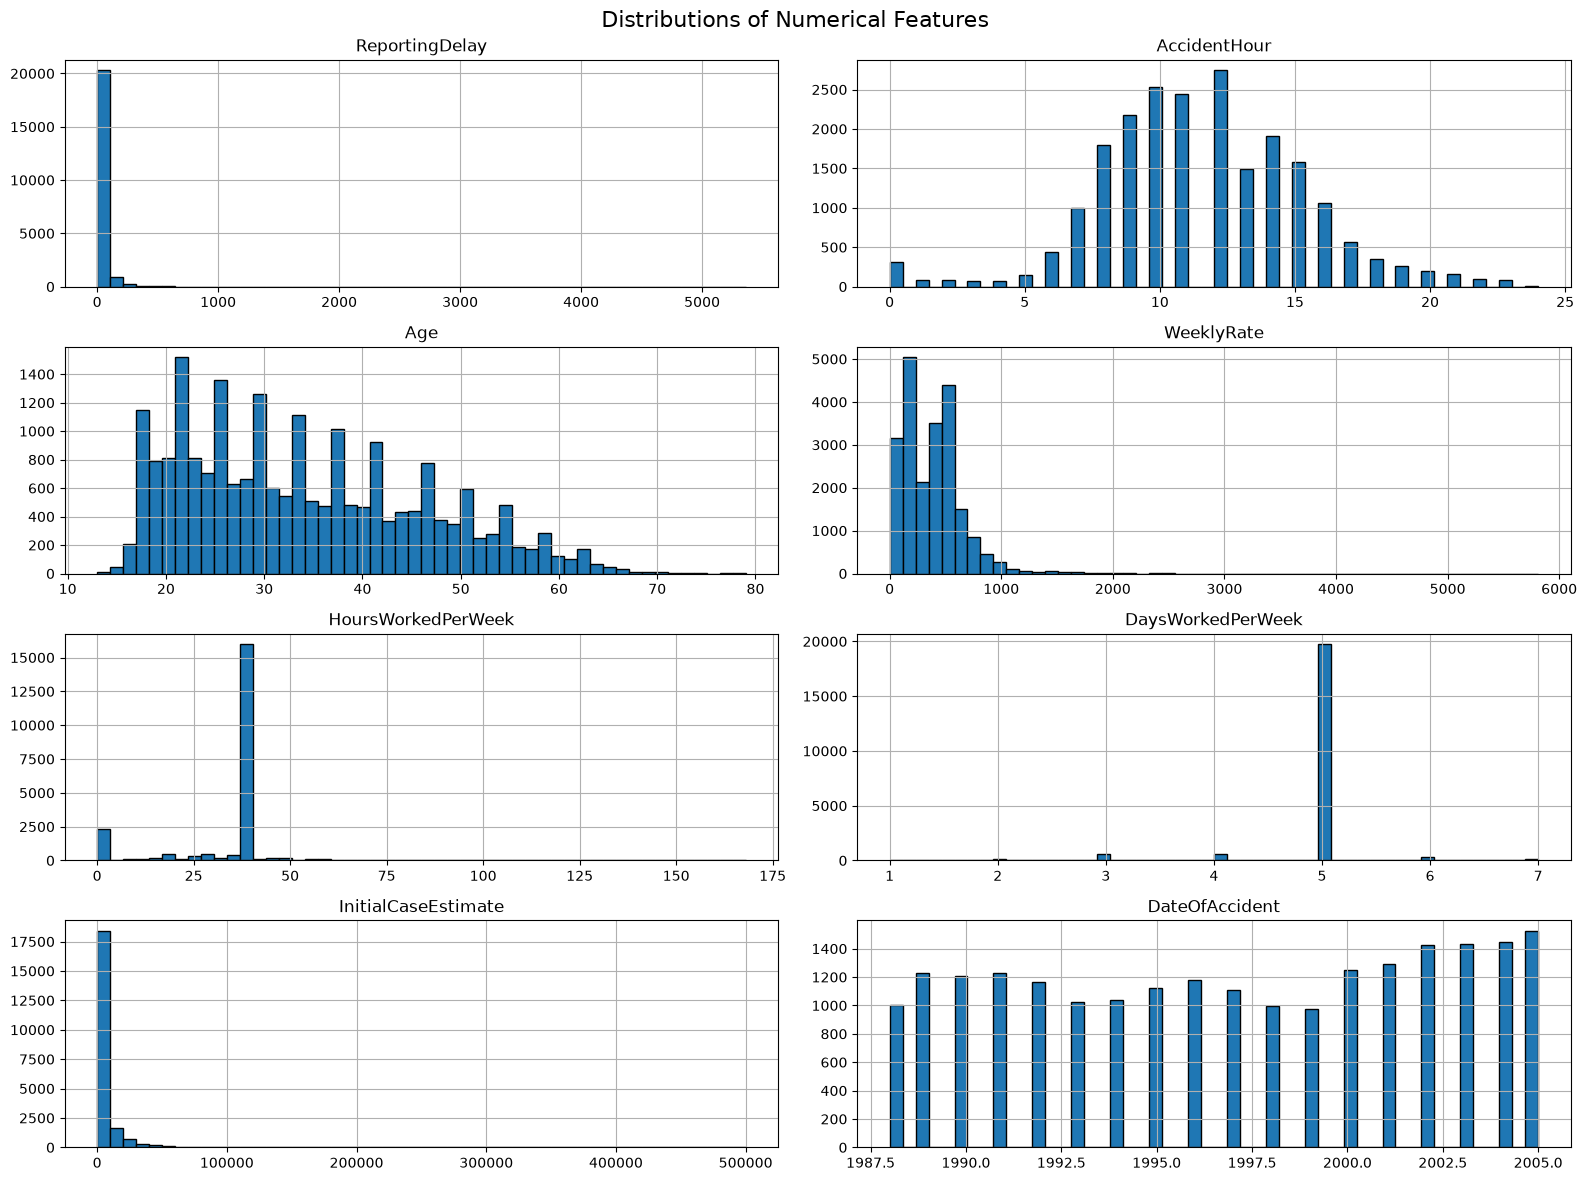

In [29]:
num_cols = [
    'ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate',
    'HoursWorkedPerWeek', 'DaysWorkedPerWeek',
    'InitialCaseEstimate', 'DateOfAccident'
]

# Create a copy for visualization
plot_df = df[num_cols].copy()

# Convert accident date to year for visualization
plot_df['DateOfAccident'] = plot_df['DateOfAccident'].dt.year

# Plot all histograms together
plot_df.hist(
    figsize=(16, 12),
    bins=50,
    layout=(4, 2),
    edgecolor='black'
)

plt.suptitle('Distributions of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

- Reporting delay is strongly right skewed.
- AccidentHour is almost normal.
- Age is right skewed.
- WeeklyRate is right skwewed.
- HoursWorkedPerWeek, most observations are concentrated around 38–40 hours per week.
- DaysWorkedPerWeek, most observations are concentrated at five days per week.
- InitialCaseEstimate is strongly right skewed.
- Date of accident is somehow normal.

## Visualizing the categorical columns

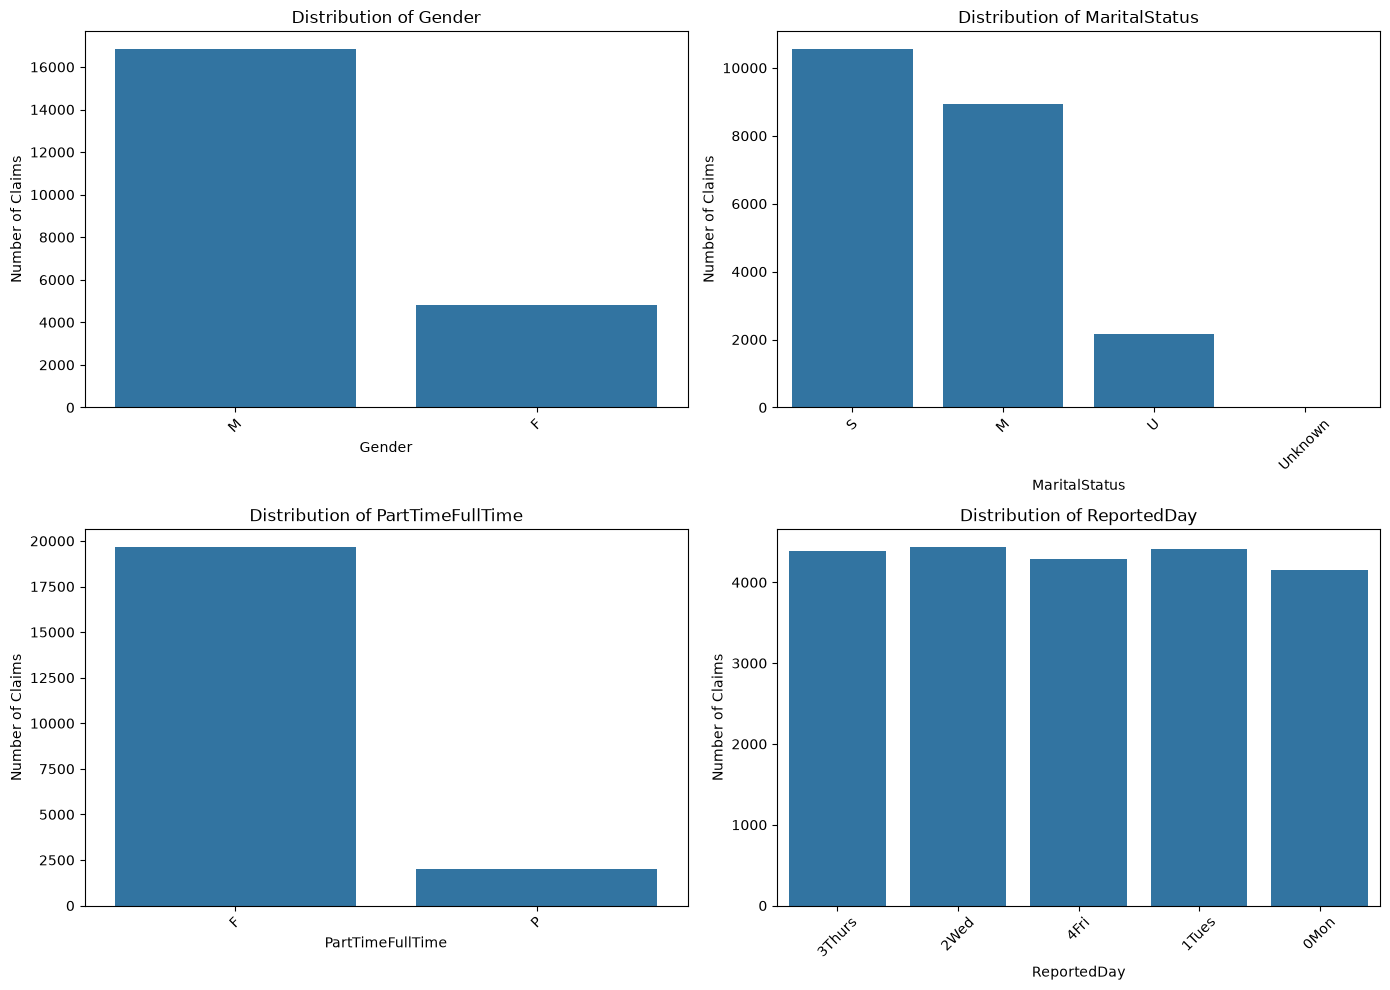

In [30]:
cat_cols = [
    'Gender',
    'MaritalStatus',
    'PartTimeFullTime',
    'ReportedDay'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Number of Claims')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

- Male are more compared to female.
- Single people are leading, followed by Married and lastly U (unknown)
- Full time employees are so many compared to part-time employees.
- The distribution of reportedDays is almost equal

In [31]:
df['MaritalStatus'].value_counts(dropna=False)

MaritalStatus
S          10549
M           8947
U           2150
Unknown       22
Name: count, dtype: int64

### Correlation heatmap

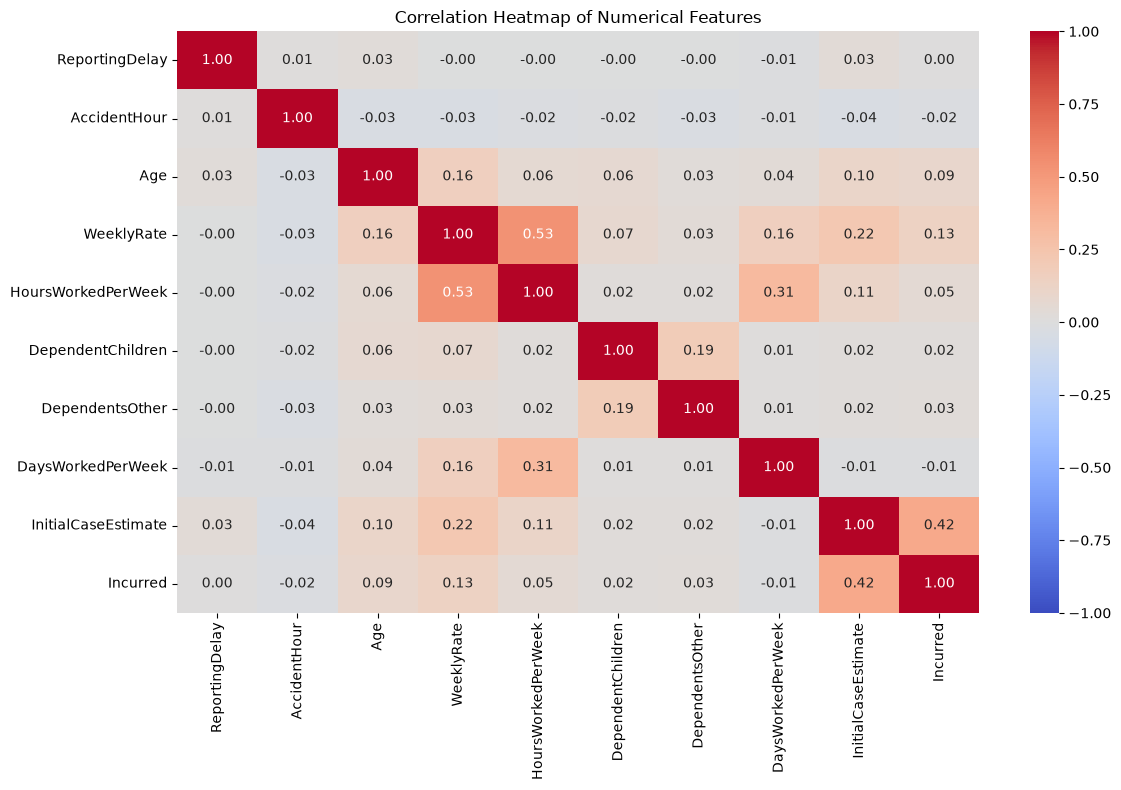

In [32]:
# Select numerical columns only
num_df = df.select_dtypes(include='number')

# Calculate correlations
corr = num_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

1. Strongest Positive Relationships (High Correlation)

• WeeklyRate & HoursWorkedPerWeek (0.53): A moderate-to-strong positive correlation. This suggests that individuals who work more hours per week tend to have a higher weekly wage rate, which aligns with standard hourly or productivity-based compensation structures.
• Incurred & InitialCaseEstimate (0.42): A moderate positive correlation. This indicates that the initial financial estimate set for a case is moderately reflective of the final total incurred cost, though there is still a significant amount of variance or adjustments made later.

2. Modest/Weak Positive Relationships

• DaysWorkedPerWeek & HoursWorkedPerWeek (0.31): A weak-to-moderate positive correlation. More days worked generally means more hours accumulated per week, though varying shift lengths keep this from being a perfect 1:1 relationship.
• WeeklyRate & InitialCaseEstimate (0.22): A very slight positive trend, indicating higher-earning individuals might occasionally be associated with higher initial case valuation estimates.
• DependentChildren & DependentOther (0.19): A weak positive correlation, likely reflecting general household sizes (families with more children may occasionally have other dependents living with them).

3. Near-Zero or Negligible Relationships (No Correlation)

• ReportingDelay & AccidentHour / Age / WeeklyRate (-0.01 to 0.03): The time it takes to report an incident has virtually zero linear connection to the worker's age, salary rate, or the specific hour of the day the accident occurred.
• Dependents & Operational Factors: Both DependentChildren and DependentOther show near-zero correlations (between -0.03 and 0.02) with job metrics like hours worked, days worked, or financial metrics like the incurred case costs.

## VIF for multicollinearity.
- VIF = 1: no multicollinearity
- VIF </= 5: Moderate multicollinearity
- VIF > 5 (or 10): High multicollinearity

In [33]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical predictor variables
vif_cols = [
    'ReportingDelay',
    'AccidentHour',
    'Age',
    'WeeklyRate',
    'HoursWorkedPerWeek',
    'DependentChildren',
    'DependentsOther',
    'DaysWorkedPerWeek',
    'InitialCaseEstimate'
]

# Prepare data for VIF
X_vif = df[vif_cols].dropna()

# Calculate VIF
vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_data = vif_data.sort_values('VIF', ascending=False)
vif_data.round(2)

,Feature,VIF
4,HoursWorkedPerWeek,1.52
3,WeeklyRate,1.49
7,DaysWorkedPerWeek,1.11
8,InitialCaseEstimate,1.06
5,DependentChildren,1.05
6,DependentsOther,1.04
2,Age,1.04
1,AccidentHour,1.00
0,ReportingDelay,1.00


ReportingDelay and AccidentHour have almost no multicollinearity, while the rest have a low multicollinearity

## Outlier Treatment

In [34]:
numerical_cols = [
    'ReportingDelay',
    'AccidentHour',
    'Age',
    'WeeklyRate',
    'HoursWorkedPerWeek',
    'DependentChildren',
    'DependentsOther',
    'DaysWorkedPerWeek',
    'InitialCaseEstimate',
    'Incurred'
]

outlier_results = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_results.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage (%)': len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)
outlier_summary.round(2)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,ReportingDelay,-28.00,84.00,2042,9.42
1,AccidentHour,1.50,21.50,584,2.70
2,Age,-4.50,71.50,12,0.06
3,WeeklyRate,-250.00,950.00,572,2.64
4,HoursWorkedPerWeek,35.00,43.00,5165,23.84
5,DependentChildren,0.00,0.00,1267,5.85
6,DependentsOther,0.00,0.00,172,0.79
7,DaysWorkedPerWeek,5.00,5.00,1934,8.93
8,InitialCaseEstimate,-10000.00,18000.00,1924,8.88
9,Incurred,-2288.16,4294.27,3397,15.68


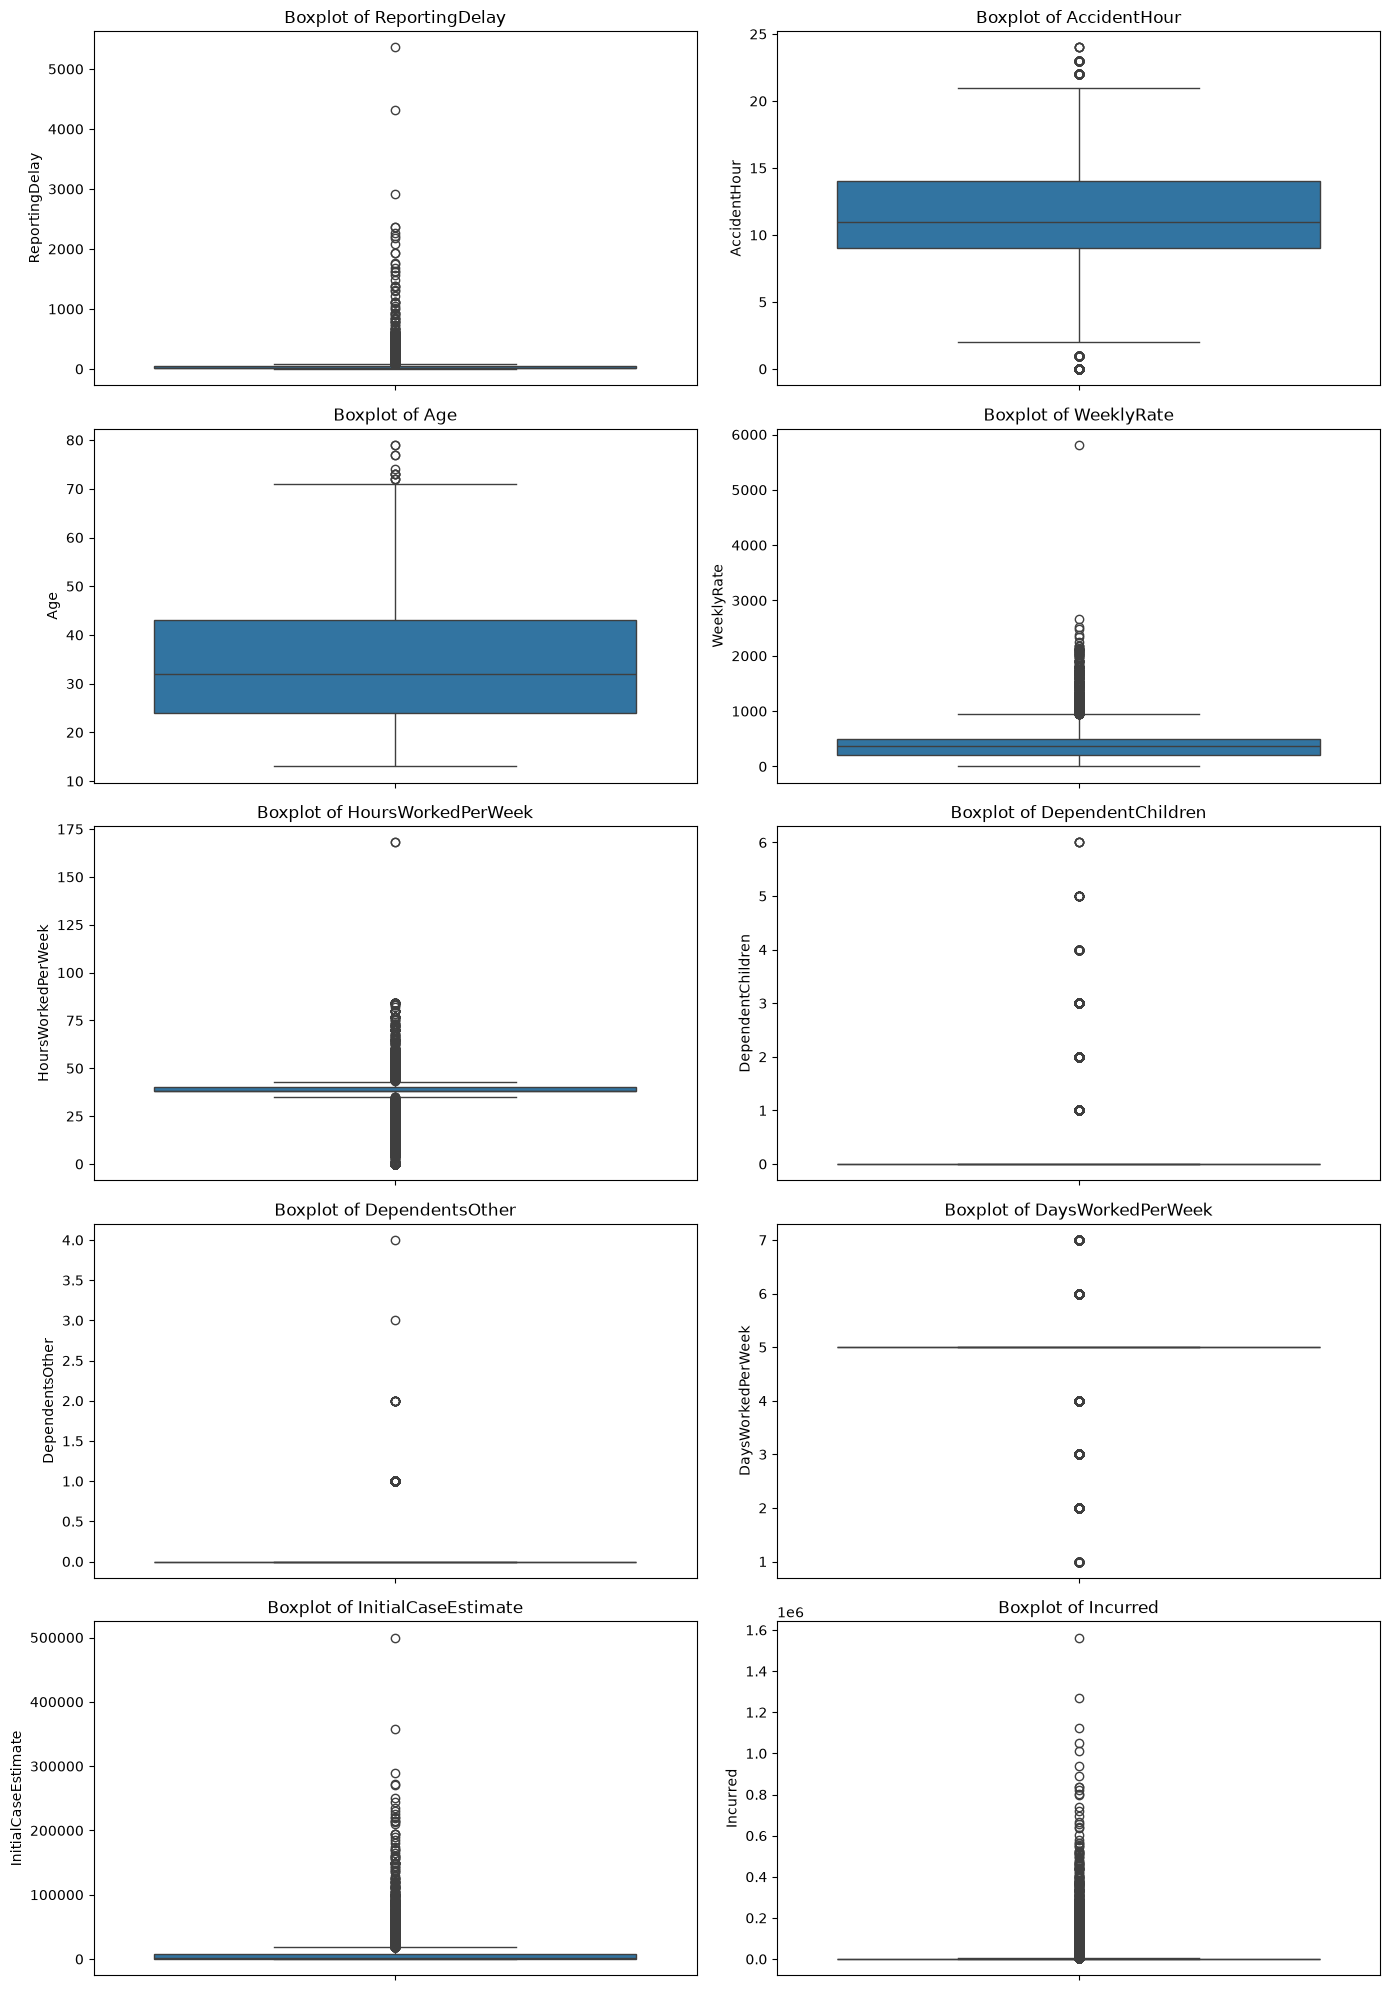

In [35]:
fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

The boxplots reveal potential outliers in several numerical features, particularly ReportingDelay, WeeklyRate, HoursWorkedPerWeek, InitialCaseEstimate and Incurred. Several features, including the number of dependants and days worked per week, are naturally discrete and concentrated around particular values.

Outlier detection alone is not sufficient reason to delete observations hence the next step is to investigate implausible values and distinguish genuine extreme observations from data errors. Since Incurred is the target for claim severity prediction, unusually high claim amounts should be retained unless there is evidence that they are incorrect. If the target is later converted into low, medium and high severity classes, these extreme amounts will also influence the choice of severity thresholds.

The boxplots for DependentChildren and DependentsOther look unusual because these are count variables with many zeros. The IQR method flags legitimate nonzero values simply because most observations are zero. This does not mean those records are erroneous.

### Investigating AccidentHour

In [36]:
print("Minimum:", df['AccidentHour'].min())
print("Maximum:", df['AccidentHour'].max())

df.loc[
    (df['AccidentHour'] < 0) | (df['AccidentHour'] > 23),
    ['AccidentHour', 'DateOfAccident', 'ClaimDescription']
]

Minimum: 0
Maximum: 24


,AccidentHour,DateOfAccident,ClaimDescription
6421,24,1988-02-27,STRUCK METAL BAR STRAIN RIGHT SHOULDER INJURY
10688,24,1994-06-08,HIT ARM ON HAND LACERATION LEFT LOWER LEFT HAND
12027,24,1994-02-20,FELL FROM MACHINE LACERATION TO RIGHT ELBOW
19938,24,2003-08-04,SLIPPED KNIFE LACERATED LEFT FINGER


In the conventional 24-hour clock, valid hour values are 0–23, so 24 is outside the expected range.

 The observations have an `AccidentHour` value of 24. Since the available dataset documentation does not clarify the meaning of this value, the observations will be retained during EDA without modification. Their treatment will be reviewed during preprocessing to avoid making unsupported assumptions or unnecessarily removing data.

### Investigating WeeklyRate

In [37]:
Q1 = df['WeeklyRate'].quantile(0.25)
Q3 = df['WeeklyRate'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:", (df['WeeklyRate'] > upper_bound).sum())

df.loc[
    df['WeeklyRate'] > upper_bound,
    ['WeeklyRate', 'Age', 'HoursWorkedPerWeek',
     'PartTimeFullTime', 'InitialCaseEstimate', 'Incurred']
].sort_values('WeeklyRate', ascending=False).head(15)

Upper IQR bound: 950.0
Outlier count: 572


,WeeklyRate,Age,HoursWorkedPerWeek,PartTimeFullTime,InitialCaseEstimate,Incurred
7163,5811.30,59,65.00,F,20000,5487.785455
4033,2674.00,58,56.00,F,10000,2772.844053
10900,2522.03,24,56.00,F,990,406.359345
13591,2487.00,48,38.00,F,56625,639076.468900
8727,2380.93,24,56.00,F,440,206.843762
10475,2335.00,39,84.00,F,12000,2619.844308
16043,2246.00,25,59.00,F,55000,3297.121061
1444,2178.90,39,30.00,F,1000,1227.868896
21009,2171.32,52,54.00,F,700,230.864977
6027,2168.56,54,40.00,F,500,237.940682


Outliers will be kept since they may represent legitimate observations thus scaling (Robustscaler) will be considered during the preprocessing step

### Investigating InitialCaseEstimate

In [38]:
Q1 = df['InitialCaseEstimate'].quantile(0.25)
Q3 = df['InitialCaseEstimate'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:",
      (df['InitialCaseEstimate'] > upper_bound).sum())

df.loc[
    df['InitialCaseEstimate'] > upper_bound,
    ['InitialCaseEstimate', 'Incurred',
     'ClaimDescription', 'ReportingDelay']
].sort_values('InitialCaseEstimate', ascending=False).head(15)

Upper IQR bound: 18000.0
Outlier count: 1924


,InitialCaseEstimate,Incurred,ClaimDescription,ReportingDelay
4002,500000,4.599808e+05,BENDING CLEANING STRAIN LOWER BACK STRAIN LOWE...,20
8991,358000,3.963779e+05,LIFTING LOWER BACK STRAIN,94
591,290000,4.755062e+05,LIFTING REPETITIVE STRAIN BACK STRAIN LOWER BA...,40
6250,272000,1.563323e+06,FELL DOWN LOWER BACK LOWER BACK PAIN,25
7702,270000,3.963779e+05,FELL OFF LADDER BACK STRAIN RIGHT SHOULDER STRAIN,13
15479,250297,5.083576e+04,LIFTING CHILD STRAIN BACK STRAIN UPPER BACK ST...,15
7128,245000,8.253917e+03,FELL DOWN STAIRS STRAIN LEFT FINGERS,28
11562,235000,3.657718e+04,LIFTING STRAIN RIGHT KNEE,54
20412,230069,2.682134e+04,STRUCK FORKLIFT LOW BACK STRAIN,193
15047,225000,6.025641e+05,LIFTING RESIDENT LOWER BACK INJURY,49


The InitialCaseEstimate variable has 1,924 observations above the upper IQR bound of 18,000. These observations are flagged as potential outliers, but they will be retained pending further investigation because high initial claim estimates may be legitimate. Their distribution and relationship with the Incurred target will be examined before deciding on any preprocessing

Some claims have high initial estimates but much lower Incurred values. This is worth exploring, as the initial estimate may not match the final cost.

### Scatter plot for InitialCaseEstimate vs. Incurred 

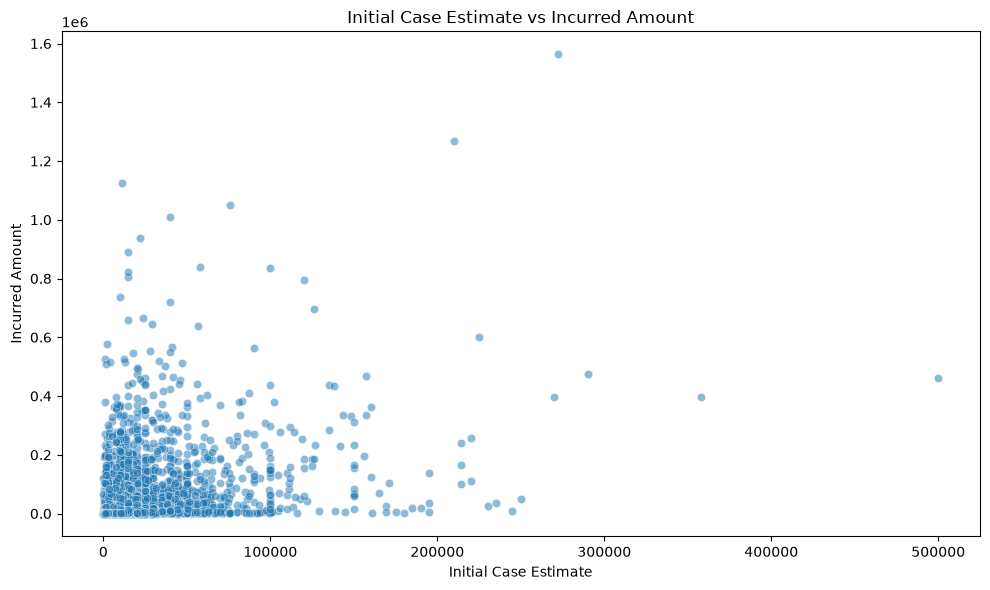

In [39]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='InitialCaseEstimate',
    y='Incurred',
    alpha=0.5
)

plt.title('Initial Case Estimate vs Incurred Amount')
plt.xlabel('Initial Case Estimate')
plt.ylabel('Incurred Amount')
plt.tight_layout()
plt.show()

1. High Volatility and Underestimation Risk at Low Estimates

• Severe Vertical Outliers: There is a distinct vertical column of data points near the left axis where the Initial Case Estimate is very low (under 50,000), but the Incurred Amount shoots up dramatically (reaching peak values between 1.0 and 1.6).
• Takeaway: This indicates a significant risk of severe underestimation—low initial estimates frequently result in unexpectedly massive actual costs.

2. Heteroscedasticity (Non-Constant Variance)

• Funnel Shape: The spread of the data points is extremely wide when the initial estimate is low, but narrows down significantly as the initial estimate increases toward 500,000.
• Takeaway: The variance of your residuals is not constant (heteroscedastic). Predictive models (like standard linear regression) will struggle to make accurate predictions at the lower end because the target variable is highly volatile there.

3. Heavy Density in the Bottom-Left Quadrant

• Mass Concentration: The vast majority of the data points are densely packed right near the origin (0,0).
• Takeaway: Most cases typically involve both low initial estimates and low final incurred amounts. The dataset is highly right-skewed, meaning typical cases are small, while large or severely underestimated cases are rarer but highly impactful.

### Investigating Incurred

In [40]:
Q1 = df['Incurred'].quantile(0.25)
Q3 = df['Incurred'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:", (df['Incurred'] > upper_bound).sum())

df.loc[
    df['Incurred'] > upper_bound,
    ['Incurred', 'InitialCaseEstimate', 'ClaimDescription',
     'Age', 'ReportingDelay']
].sort_values('Incurred', ascending=False).head(15)

Upper IQR bound: 4294.26682875
Outlier count: 3397


,Incurred,InitialCaseEstimate,ClaimDescription,Age,ReportingDelay
6250,1.563323e+06,272000,FELL DOWN LOWER BACK LOWER BACK PAIN,46,25
4854,1.269778e+06,210000,LIFTING LOWER BACK STRAIN LOWER BACK STRAIN,41,13
4316,1.124836e+06,11000,LIFTING BAGS BACK STRAIN LOWER BACK PAIN,49,28
3509,1.050411e+06,76000,SLIPPED ON STEP STRAIN RIGHT KNEE BACK STRAIN,41,6
8470,1.011132e+06,40000,STRUCK FALLING BOX LOWER BACK STRAIN LEFT LEG,33,8
7554,9.373632e+05,22000,LIFTING BOX STRAINED LOWER BACK STRAIN BACK,42,40
803,8.913606e+05,14500,TWISTED BACK STRAIN LOWER BACK STRAIN,26,63
6995,8.378862e+05,58115,LIFTING TRUCK BACK STRAIN LOWER BACK STRAIN,35,16
7304,8.345769e+05,100000,FALL OVER BACK STRAIN LOWER BACK INJURY,34,15
18000,8.234933e+05,15000,FELL FROM LADDER BACK SPRAIN,33,42


### Investigating DaysWorkedPerWeek

In [41]:
print(df['DaysWorkedPerWeek'].value_counts().sort_index())

DaysWorkedPerWeek
1       62
2      177
3      580
4      635
5    19734
6      360
7      120
Name: count, dtype: int64


# **Data Preprocessing**

# Creating a new target variable 'Severity'

Converting the continuous incurred amounts into three categories: Low, Medium and High severity through a process called *target variable descretisation or binning* (the process of converting a continuous numerical target variable into a finite set of discrete classes, bins or categories) since there is an abscence of established cost thresholds. Creation of a new column named "severity' and then categorize the thresholds into 33rd and 67th percentiles to divide into the three groups such that: claims below 33rd percentile are low severity, claims above 33rd but below 67th percentile are medium severity and lastly, claims above the 67th percentile are high severity. And also create some class balance.

In [42]:
# Checking Incurred distribution
df['Incurred'].describe(percentiles=[0.33, 0.50, 0.67])

count    2.166800e+04
mean     9.630120e+03
std      4.704018e+04
min      2.220000e-15
33%      2.484248e+02
50%      4.958777e+02
67%      1.121230e+03
max      1.563323e+06
Name: Incurred, dtype: float64

In [43]:
# Calculate the severity thresholds
lower_threshold = df['Incurred'].quantile(0.33)
upper_threshold = df['Incurred'].quantile(0.67)

print("Low severity upper limit:", lower_threshold)
print("Medium severity upper limit:", upper_threshold)

Low severity upper limit: 248.42475000000013
Medium severity upper limit: 1121.22955804


In [44]:
# Creating severity categories
df['Severity'] = np.select(
    [
        df['Incurred'] <= lower_threshold,
        df['Incurred'] <= upper_threshold
    ],
    [
        'Low',
        'Medium'
    ],
    default='High'
)

In [45]:
# Check resulting classes
print(df['Severity'].value_counts())

print("\nClass percentages:")
print((df['Severity'].value_counts(normalize=True) * 100).round(2))

Severity
Medium    7366
Low       7151
High      7151
Name: count, dtype: int64

Class percentages:
Severity
Medium    33.99
Low       33.00
High      33.00
Name: proportion, dtype: float64


The classes are nearly equally represented but medium has slightly more claims.

In [46]:
df.head(30)

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred,Severity
0,15,11,28,500.00,M,S,44.0,0,0,F,5,2005-10-05,STRUCK SCAFFOLDING STRAIN LOWER BACK,3Thurs,9500,151.254501,Low
1,22,5,29,500.00,M,S,38.0,0,0,F,5,2003-10-28,STRUCK KNIFE LACERATED LEFT THUMB,2Wed,11500,442.125024,Medium
2,22,7,28,197.37,M,M,16.0,0,0,P,3,2004-05-25,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,2Wed,8000,1494.490505,High
3,15,12,40,0.00,M,M,0.0,1,0,F,5,1994-07-21,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,4Fri,500,138.900000,Low
4,38,12,22,435.70,M,M,38.0,0,0,F,5,1992-06-09,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,4Fri,320,296.160000,Medium
5,55,7,18,263.45,F,U,40.0,0,0,F,5,1993-06-09,KNIFE SLIPPED CUT LEFT INDEX FINGER,1Tues,210,99.200000,Low
6,6,14,22,200.00,M,S,38.0,0,0,F,5,1995-04-20,SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...,2Wed,4000,154.625000,Low
7,105,7,17,0.00,M,S,0.0,0,0,F,5,1994-05-17,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,1Tues,500,252.500000,Medium
8,14,9,61,1446.00,M,M,60.0,0,0,F,5,2004-11-23,LIFTING PATIENT BACK PAIN,1Tues,5000,534.100143,Medium
9,10,12,62,461.90,M,M,25.0,0,0,P,4,1995-11-13,SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE,3Thurs,5000,766.425000,Medium


In [47]:
# Checking if creating 'Severity' created missing values
df['Severity'].isna().sum()

np.int64(0)

### Combining 'unknown' and 'U'

In [48]:
df['MaritalStatus'] = df['MaritalStatus'].replace({
    'U': 'Unknown',
    'Unknown': 'Unknown'
})

In [49]:
print(df['MaritalStatus'].value_counts())

MaritalStatus
S          10549
M           8947
Unknown     2172
Name: count, dtype: int64


### Key Note
impact of creating severity column from incurred column only.
> - ANS: Think of it this way: you know the final incurred amount for historical claims, so you use it to label them Low, Medium or High. The model then learns from the other available information to predict the severity of a new claim. The model learns from the available features by learning patterns connecting the available features to the severity labels. For a new claim, it receives the description, age and other eligible features, then predicts Low, Medium or High. It does not need the new claim's final Incurred amount to make that prediction.

# Extracting keywords from 'ClaimDescription'

In [50]:
# checking few descriptions in order to build the keyword categories
df['ClaimDescription'].head(30)

0                  STRUCK SCAFFOLDING STRAIN LOWER BACK
1                     STRUCK KNIFE LACERATED LEFT THUMB
2     SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...
3     HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...
4     STRUCK FALLING OBJECT LACERATION RIGHT RING FI...
5                   KNIFE SLIPPED CUT LEFT INDEX FINGER
6     SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...
7           LIFTING METAL SHEETS STRAIN LOWER BACK PAIN
8                             LIFTING PATIENT BACK PAIN
9       SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE
10    SLIPPED CUTTING WITH KNIFE LACERATION RIGHT IN...
11                        LIFTING PIPE LOWER BACK LOWER
12              HIT IN STEEL LOWER BACK STRAIN AND KNEE
13    LIFTING RESIDENT LACERATION LEFT ARM LEFT SHOU...
14    STRUCK KNIFE LACERATION LEFT THUMB INJURY HAND...
15               FELL DOWN LOWER BACK STRAIN LOWER BACK
16           LIFTING HEAVY LIFTING BACK LEFT EYE INJURY
17           LIFTING BACK STRAIN LOWER BACK INJU

Common keywords:- 

- **How accident happened**: struck, fell, strained, slipped, lifting, caught, hit, falling , cutting, cut
- **Injury type**: strain, sprain, strained, laceration, lacerated, bruise, bruised, fracture, crush, injury, pain, cut
- **Body part**: back, shoulder, knee, thumb, finger, hand, arm, leg, wrist, neck, eye, ankle, groin, head



### Stemming vs. Lemmatization
- Stemming - is a rule-based text normalisation technique that reduces words to their root form by removing prefixes or suffixes such as -ing, -ed, -es
- Lemmatization -  is a linguistically driven text normalization technique that converts words into their base dictionary form, known as a lemma, by considering grammar, vocabulary and context.

# Using Lemmatization

In [51]:
# # installing packages
# %pip install nltk

In [52]:
import nltk

nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [53]:
from nltk.stem import WordNetLemmatizer
import re

lemmatizer = WordNetLemmatizer()

def lemmatize_description(description):
    words = re.findall(r'\b[a-zA-Z]+\b', str(description).lower())
    return " ".join(lemmatizer.lemmatize(word, pos='v') for word in words)

df['ClaimDescription_Lemmatized'] = df['ClaimDescription'].apply(
    lemmatize_description
)

df[['ClaimDescription', 'ClaimDescription_Lemmatized']].head(30)

,ClaimDescription,ClaimDescription_Lemmatized
0,STRUCK SCAFFOLDING STRAIN LOWER BACK,strike scaffold strain lower back
1,STRUCK KNIFE LACERATED LEFT THUMB,strike knife lacerate leave thumb
2,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,slip and hit strain leave shoulder injury leav...
3,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,hit fall door laceration leave shoulder injury...
4,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,strike fall object laceration right ring finger
5,KNIFE SLIPPED CUT LEFT INDEX FINGER,knife slip cut leave index finger
6,SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...,slip on steel beam lower back bruise knee liga...
7,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,lift metal sheet strain lower back pain
8,LIFTING PATIENT BACK PAIN,lift patient back pain
9,SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE,slip off truck bruise lower back right knee


- words have been lemmatized but 'left thumb' has been converted to 'leave thumb'
- laceration has not been converted to lacerate like the way lacerated was

# Using Stemming

In [54]:
import re
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

# Normalize important irregular terms before stemming
word_map = {
    'fell': 'fall',
    'fallen': 'fall',
    'struck': 'strike'
}

def stem_description(description):
    words = re.findall(r'\b[a-zA-Z]+\b', str(description).lower())

    words = [word_map.get(word, word) for word in words]

    return " ".join(stemmer.stem(word) for word in words)

df['ClaimDescription_Stemmed'] = df['ClaimDescription'].apply(
    stem_description
)

df[['ClaimDescription', 'ClaimDescription_Stemmed']].head(30)

,ClaimDescription,ClaimDescription_Stemmed
0,STRUCK SCAFFOLDING STRAIN LOWER BACK,strike scaffold strain lower back
1,STRUCK KNIFE LACERATED LEFT THUMB,strike knife lacer left thumb
2,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,slip and hit strain left shoulder injuri left ...
3,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,hit fall door lacer left shoulder injuri right...
4,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,strike fall object lacer right ring finger
5,KNIFE SLIPPED CUT LEFT INDEX FINGER,knife slip cut left index finger
6,SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...,slip on steel beam lower back bruis knee ligament
7,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,lift metal sheet strain lower back pain
8,LIFTING PATIENT BACK PAIN,lift patient back pain
9,SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE,slip off truck bruis lower back right knee


all words have been correctly standardized with the body parts, such as left thumb has been preserved. **Thus stemming will be chosen over lemmatization.**

### Applying TF-IDF (term frequency-inverse document frequency)
- fitted on training data only to prevent data leakage
> - It is a statistical method used in natural language processing and information retrieval to evaluate how important a word is to a document in relation to a larger collection of documents by measuring how often a word appears in a document (term frequency) and reduces the weight of common words across multiple documents while increasing the weight of rare words (Inverse Document Frequency)

In [55]:
# !pip install scikit-learn

In [56]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=500)

X_text = tfidf.fit_transform(df['ClaimDescription_Stemmed'])

print("TF-IDF matrix shape:", X_text.shape)

TF-IDF matrix shape: (21668, 495)


- Each row reps a claim, each column reps a word or term and each value reps how important that term is within a claim relative to the dataset

In [57]:
# Inspect the features
print("Number of text features:", len(tfidf.get_feature_names_out()))
print(tfidf.get_feature_names_out()[:30])

Number of text features: 495
['abdomin' 'abras' 'accid' 'ach' 'against' 'air' 'aircraft' 'alleg'
 'aluminium' 'amput' 'and' 'angl' 'ankl' 'anxieti' 'arm' 'arthralgia'
 'assault' 'assist' 'at' 'back' 'backho' 'backward' 'bag' 'baggag' 'ball'
 'bar' 'batteri' 'beam' 'bed' 'belt']


numerical input features that help the model learn patterns associated with claim severity.

### Inspect the TF-IDF matrix

In [58]:
# numerical values of the first 5 claims
tfidf_df = pd.DataFrame(
    X_text[:5].toarray(),
    columns=tfidf.get_feature_names_out()
)

tfidf_df.iloc[:, :15]

,abdomin,abras,accid,ach,against,air,aircraft,alleg,aluminium,amput,and,angl,ankl,anxieti,arm
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.34139,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0


descriptions have been converted into numerical values correctly.

**NB**: Later, when we prepare the final model, we'll fit TF-IDF on the training descriptions only, then transform the test descriptions to prevent data leakage.

### Separate target vs. input features

In [59]:
df.columns

Index(['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender',
       'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren',
       'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek',
       'DateOfAccident', 'ClaimDescription', 'ReportedDay',
       'InitialCaseEstimate', 'Incurred', 'Severity',
       'ClaimDescription_Lemmatized', 'ClaimDescription_Stemmed'],
      dtype='str')

In [60]:
# Keep rows that have a valid target
model_df = df.dropna(subset=['Severity']).copy()

# Target variable
y = model_df['Severity']

# Input features: exclude targets and text columns
# X_nontext contains the candidate input features
X_nontext = model_df.drop(
    columns=[
        'Severity',
        'Incurred',
        'ClaimDescription',
        'ClaimDescription_Lemmatized',
        'ClaimDescription_Stemmed'
    ],
    errors='ignore'
)

print("Input features shape:", X_nontext.shape)
print("Target shape:", y.shape)

print("\nInput feature columns:")
print(X_nontext.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Input features shape: (21668, 14)
Target shape: (21668,)

Input feature columns:
['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender', 'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek', 'DateOfAccident', 'ReportedDay', 'InitialCaseEstimate']

Target distribution:
Severity
Medium    7366
Low       7151
High      7151
Name: count, dtype: int64


We dropped ClaimDescription when separating the target and input features because machine learning models cannot directly work with raw text in the same way they work with numerical features.


In [61]:
# Check datatypes and missing values
# Check data types
print(X_nontext.dtypes)

# Check missing values
print("\nMissing values per feature:")
print(X_nontext.isnull().sum())

ReportingDelay                  int64
AccidentHour                    int64
Age                             int64
WeeklyRate                    float64
Gender                            str
MaritalStatus                     str
HoursWorkedPerWeek            float64
DependentChildren               int64
DependentsOther                 int64
PartTimeFullTime                  str
DaysWorkedPerWeek               int64
DateOfAccident         datetime64[us]
ReportedDay                       str
InitialCaseEstimate             int64
dtype: object

Missing values per feature:
ReportingDelay         0
AccidentHour           0
Age                    0
WeeklyRate             0
Gender                 0
MaritalStatus          0
HoursWorkedPerWeek     0
DependentChildren      0
DependentsOther        0
PartTimeFullTime       0
DaysWorkedPerWeek      0
DateOfAccident         0
ReportedDay            0
InitialCaseEstimate    0
dtype: int64


### Extract date features
> - Machine-learning models generally cannot use a raw datetime column directly, so we'll extract useful information from it.

In [62]:
# Extract useful information from DateOfAccident
X_nontext['AccidentYear'] = X_nontext['DateOfAccident'].dt.year
X_nontext['AccidentMonth'] = X_nontext['DateOfAccident'].dt.month
X_nontext['AccidentDayOfWeek'] = X_nontext['DateOfAccident'].dt.dayofweek

# Remove the original datetime column
X_nontext = X_nontext.drop(columns=['DateOfAccident'])

# Check the updated features
print(X_nontext.shape)
print(X_nontext.columns.tolist())

(21668, 16)
['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender', 'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek', 'ReportedDay', 'InitialCaseEstimate', 'AccidentYear', 'AccidentMonth', 'AccidentDayOfWeek']


# Encoding categorical features
- Use one-hot encoding because categorical features are nominal, meaning they have no natural order and prevent the model from interpreting them as ranked values.

In [63]:
# Identify categorical columns
categorical_cols = X_nontext.select_dtypes(
    include=['str', 'object', 'category']
).columns.tolist()

print("Categorical columns:", categorical_cols)

Categorical columns: ['Gender', 'MaritalStatus', 'PartTimeFullTime', 'ReportedDay']


In [64]:
# One-hot encode categorical features
X_nontext_encoded = pd.get_dummies(
    X_nontext,
    columns=categorical_cols,
    drop_first=False, 
    dtype=int
)

print("Shape before encoding:", X_nontext.shape)
print("Shape after encoding:", X_nontext_encoded.shape)

print("\nEncoded feature columns:")
print(X_nontext_encoded.columns.tolist())

Shape before encoding: (21668, 16)
Shape after encoding: (21668, 24)

Encoded feature columns:
['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'DaysWorkedPerWeek', 'InitialCaseEstimate', 'AccidentYear', 'AccidentMonth', 'AccidentDayOfWeek', 'Gender_F', 'Gender_M', 'MaritalStatus_M', 'MaritalStatus_S', 'MaritalStatus_Unknown', 'PartTimeFullTime_F', 'PartTimeFullTime_P', 'ReportedDay_0Mon', 'ReportedDay_1Tues', 'ReportedDay_2Wed', 'ReportedDay_3Thurs', 'ReportedDay_4Fri']


increased columns from 16 to 24

# Train/Test Split

In [65]:
# checking date range
print("Earliest accident date:", model_df['DateOfAccident'].min())
print("Latest accident date:", model_df['DateOfAccident'].max())

Earliest accident date: 1988-01-02 00:00:00
Latest accident date: 2005-12-31 00:00:00


# Create a chronological train-test split
- Simulate real-world use: In practice, a model is trained on historical claims and use it to assess new claims arriving later.

Reasons for a chronological train-test split:
- Reduce temporal leakage: A random split could place older and newer claims in both training and testing sets, making the evaluation less representative of predicting future claims.
- Evaluate generalisation over time: The model learns from claims up to July 2022 and is tested on claims from July 2022 onward, allowing us to assess performance on later claims.
- The chronological split is appropriate since the intended use is to evaluate how well the model would perform on prediting the severity of claims from a later period using historical claims, which allows to train on earlier claims and test on later claims.
- A random split would have placed claims from later and earlier years in tha tarining set which would have given overly optimistic results.

In [66]:
# Get unique accident dates in chronological order
unique_dates = model_df['DateOfAccident'].sort_values().unique()

# Select the date boundary
split_point = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_point]

# Split so each date belongs to only one set
train_mask = model_df['DateOfAccident'] < split_date
test_mask = model_df['DateOfAccident'] >= split_date

# Create training and testing sets
X_train = X_nontext_encoded.loc[model_df.index[train_mask]]
X_test = X_nontext_encoded.loc[model_df.index[test_mask]]

y_train = model_df.loc[train_mask, 'Severity']
y_test = model_df.loc[test_mask, 'Severity']

print("Split date:", split_date)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Last training date:",
      model_df.loc[X_train.index, 'DateOfAccident'].max())
print("First testing date:",
      model_df.loc[X_test.index, 'DateOfAccident'].min())

Split date: 2002-07-22 00:00:00
Training features: (16615, 24)
Testing features: (5053, 24)
Last training date: 2002-07-20 00:00:00
First testing date: 2002-07-22 00:00:00


- 80% = training
- 20 % = testing

Important: This split is for the non-text features only. We'll apply the same split to the claim descriptions before fitting TF-IDF, so the vocabulary and feature weights are learned from training claims rather than the entire dataset

In [67]:
# Let's check whether the split should keep entire dates together to avoid this overlap.
print("Last training date:", model_df.loc[X_train.index, 'DateOfAccident'].max())
print("First testing date:", model_df.loc[X_test.index, 'DateOfAccident'].min())

print(
    "Same date in both sets:",
    model_df.loc[X_train.index, 'DateOfAccident'].max()
    == model_df.loc[X_test.index, 'DateOfAccident'].min()
)

Last training date: 2002-07-20 00:00:00
First testing date: 2002-07-22 00:00:00
Same date in both sets: False


 2003-01-17 appeared at the end of training and the beginning of testing, so claims from the same date may be in both sets. just confirming if there are any overlapping dates

## Prepare text data for TF-IDF

In [68]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Align descriptions with the existing chronological split
text_train = model_df.loc[X_train.index, 'ClaimDescription_Stemmed']
text_test = model_df.loc[X_test.index, 'ClaimDescription_Stemmed']

# Fit TF-IDF only on training descriptions
tfidf = TfidfVectorizer(max_features=500)

X_train_text = tfidf.fit_transform(text_train)
X_test_text = tfidf.transform(text_test)

print("Training text shape:", X_train_text.shape)
print("Testing text shape:", X_test_text.shape)

Training text shape: (16615, 465)
Testing text shape: (5053, 465)


# **Feature Scaling**

- Scaling helps the neural network learn effectively when features have very different numerical ranges
- using Standardscaler on structured features because MLP neural networks generally perform better when numerical features are standardized to have a mean of 0 and a standard deviation of 1, helping prevent features with larger numerical ranges from dominating the learning process.

In [69]:
print(X_train.columns.tolist())

['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'DaysWorkedPerWeek', 'InitialCaseEstimate', 'AccidentYear', 'AccidentMonth', 'AccidentDayOfWeek', 'Gender_F', 'Gender_M', 'MaritalStatus_M', 'MaritalStatus_S', 'MaritalStatus_Unknown', 'PartTimeFullTime_F', 'PartTimeFullTime_P', 'ReportedDay_0Mon', 'ReportedDay_1Tues', 'ReportedDay_2Wed', 'ReportedDay_3Thurs', 'ReportedDay_4Fri']


In [70]:
# Scaling using robust scaler because reporting delay and weeklyrate contain extreme values
from sklearn.preprocessing import RobustScaler

# Continuous numerical features to scale
numeric_cols = [
    'ReportingDelay',
    'AccidentHour',
    'Age',
    'WeeklyRate',
    'HoursWorkedPerWeek',
    'DependentChildren',
    'DependentsOther',
    'DaysWorkedPerWeek',
    'AccidentYear',
    'AccidentMonth',
    'AccidentDayOfWeek'
]

# Create copies so the original data remains unchanged
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit scaler on training data only
scaler = RobustScaler()

X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

# Use the same scaler to transform test data
X_test_scaled[numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (16615, 24)
Scaled testing shape: (5053, 24)


## Combine text and non-text features and split

In [71]:
from scipy.sparse import hstack, csr_matrix

# Convert scaled structured features to sparse matrices
X_train_structured = csr_matrix(X_train_scaled.to_numpy(dtype=float))
X_test_structured = csr_matrix(X_test_scaled.to_numpy(dtype=float))

# Combine structured and TF-IDF features
X_train_combined = hstack(
    [X_train_structured, X_train_text],
    format='csr'
)

X_test_combined = hstack(
    [X_test_structured, X_test_text],
    format='csr'
)

print("Combined training shape:", X_train_combined.shape)
print("Combined testing shape:", X_test_combined.shape)

Combined training shape: (16615, 489)
Combined testing shape: (5053, 489)


489 total features: 24 structured features + 465 text features.

# **Feature Selection**
- It shows how much the model relies on features, it does not prove that a feature causes a claim to be more severe.

### Random Forest

In [72]:
from sklearn.ensemble import RandomForestClassifier

# ranks features by importance

# Combine feature names in the same order as the combined matrix
feature_names = (
    X_train.columns.tolist()
    + tfidf.get_feature_names_out().tolist()
)

# Check that feature names match the combined data
print("Number of feature names:", len(feature_names))
print("Number of combined features:", X_train_combined.shape[1])

# Train a Random Forest for feature importance
rf_selector = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_selector.fit(X_train_combined, y_train)

# Rank features by importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_selector.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

# Display the 20 most important features
feature_importance.head(20)

Number of feature names: 489
Number of combined features: 489


,Feature,Importance
0,InitialCaseEstimate,0.104066
1,WeeklyRate,0.048877
2,Age,0.043277
3,ReportingDelay,0.036826
4,AccidentYear,0.032783
5,AccidentHour,0.031345
6,AccidentMonth,0.029921
7,HoursWorkedPerWeek,0.028922
8,strain,0.027141
9,back,0.025274


- InitialCaseEstimate (0.1041): the most important feature in this ranking, contributing about 10.41% of the model's total feature importance.
- WeeklyRate and Age: also contribute useful predictive information.
- ReportingDelay and AccidentYear: suggest that reporting behaviour and the timing of accidents may help distinguish severity classes.
- Text features such as strain, back, lacer, strike and finger indicate that the words in claim descriptions provide potentially useful information.

In particular, check InitialCaseEstimate: if it is not available at the point when a claim needs to be triaged, using it could cause information leakage and make your model appear more useful than it would be in practice.

### Drop 'InitialCaseEstimate' 
- The project uses initial claim description and information available when a claim is first reported to predict its eventual sevrity if low, medium or high.
> - Advantage: helps with prioritization of claims early.
> - Limitation: model must predict severity before the final cost is known.

In [73]:
from scipy.sparse import hstack, csr_matrix

# Remove InitialCaseEstimate from structured features
X_train_no_estimate = X_train_scaled.drop(columns=['InitialCaseEstimate'])
X_test_no_estimate = X_test_scaled.drop(columns=['InitialCaseEstimate'])

# Convert structured features to sparse matrices
X_train_structured = csr_matrix(
    X_train_no_estimate.to_numpy(dtype=float)
)
X_test_structured = csr_matrix(
    X_test_no_estimate.to_numpy(dtype=float)
)

# Combine structured and TF-IDF text features
X_train_combined = hstack(
    [X_train_structured, X_train_text],
    format='csr'
)

X_test_combined = hstack(
    [X_test_structured, X_test_text],
    format='csr'
)

print("Training shape:", X_train_combined.shape)
print("Testing shape:", X_test_combined.shape)

Training shape: (16615, 488)
Testing shape: (5053, 488)


# **Modelling**

**NB:** use Recall (esp for high severity class) because missing a genuinely high severity claim could be more costly than incorrectly flagging a low severity claim.

## 1. Random Forest Model

In [74]:
# train the random forest model
from sklearn.ensemble import RandomForestClassifier

# Initialize the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_combined, y_train) # learns patterns from the training claims

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test_combined) # predicts severity category of each test claim

print("Random Forest training complete.")
print("Number of predictions:", len(y_pred_rf))

Random Forest training complete.
Number of predictions: 5053


In [75]:
# evaluating the model

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

# Precision, recall and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Numerical confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=['Low', 'Medium', 'High']
)

print("\nConfusion Matrix:")
print("Rows = Actual classes; Columns = Predicted classes")
print("Class order: Low, Medium, High")
print(cm)


Accuracy: 0.5489808034830793

Classification Report:
              precision    recall  f1-score   support

        High       0.66      0.74      0.70      2278
         Low       0.40      0.37      0.38       993
      Medium       0.45      0.41      0.43      1782

    accuracy                           0.55      5053
   macro avg       0.51      0.50      0.50      5053
weighted avg       0.54      0.55      0.54      5053


Confusion Matrix:
Rows = Actual classes; Columns = Predicted classes
Class order: Low, Medium, High
[[ 364  418  211]
 [ 410  732  640]
 [ 126  474 1678]]


- Accuracy of 54.89%, meaning the model classifies appropriately 55 out of every 100 test claim.
- High severity: Recall is 74%, meaning the model identifies approximately 74% of genuinely High-severity claims and misses about 26%.
- Low severity: Recall is only 37%, so the model struggles to identify this class correctly.
- Medium severity: Recall is 41%, meaning many Medium claims are being assigned another category.

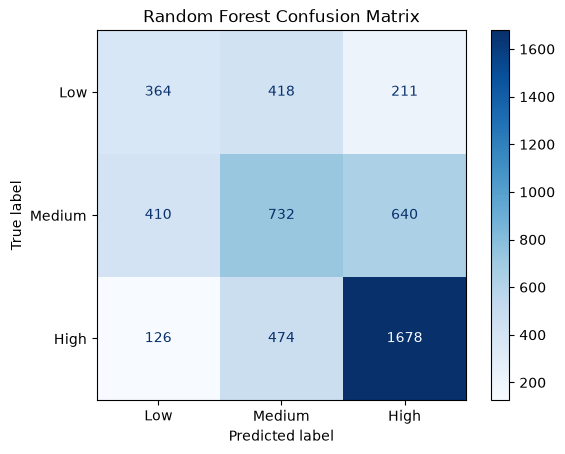

In [76]:
# visualizing confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Random Forest Confusion Matrix")
plt.show()


Confusion Matrix
- Low severity: Of 993 actual Low claims, the model correctly classified 364. It misclassified 418 as Medium and 211 as High. This means the model struggles to identify Low-severity claims correctly.

- Medium severity: Of 1,782 actual Medium claims, the model correctly classified 732. It predicted 410 as Low and 640 as High. This suggests that Medium claims are often confused with the other two classes.

- High severity: Of 2,278 actual High claims, the model correctly classified 1,678. It misclassified 474 as Medium and 126 as Low. The model identifies High-severity claims better than the other classes.

## 2. XGBoost

In [77]:
import xgboost as xgb

In [78]:
# Train the xgboost model

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Convert severity labels into numeric labels for XGBoost
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Initialize the Gradient Boosting model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6, # limit of every tree
    learning_rate=0.1,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_combined, y_train_encoded)

# Predict severity
y_pred_xgb_encoded = xgb_model.predict(X_test_combined)

# Convert predictions back to severity labels
y_pred_xgb = label_encoder.inverse_transform(
    y_pred_xgb_encoded.astype(int)
)

print("XGBoost training complete.")
print("Number of predictions:", len(y_pred_xgb))


XGBoost training complete.
Number of predictions: 5053


In [79]:
# Evaluate the model

# Evaluate accuracy
print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    labels=['High', 'Low', 'Medium', ],
    zero_division=0
))

# Numerical confusion matrix
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb,
    labels=['Low', 'Medium', 'High']
)

print("\nConfusion Matrix:")
print("Rows = Actual classes; Columns = Predicted classes")
print("Class order: Low, Medium, High")
print(cm_xgb)


XGBoost Accuracy: 0.5687710271126064

Classification Report:
              precision    recall  f1-score   support

        High       0.66      0.76      0.71      2278
         Low       0.47      0.31      0.38       993
      Medium       0.47      0.47      0.47      1782

    accuracy                           0.57      5053
   macro avg       0.53      0.51      0.52      5053
weighted avg       0.56      0.57      0.56      5053


Confusion Matrix:
Rows = Actual classes; Columns = Predicted classes
Class order: Low, Medium, High
[[ 311  456  226]
 [ 285  841  656]
 [  66  490 1722]]


- Accuracy of 56.87%, meaning the model classifies appropriately 56 out of every 100 test claim.
- High severity: Recall is 76%, meaning the model identifies approximately 76% of genuinely High-severity claims and misses about 24%.
- Low severity: Recall is only 31%, so the model struggles to identify this class correctly.
- Medium severity: Recall is 47%, meaning many Medium claims are being assigned another category.


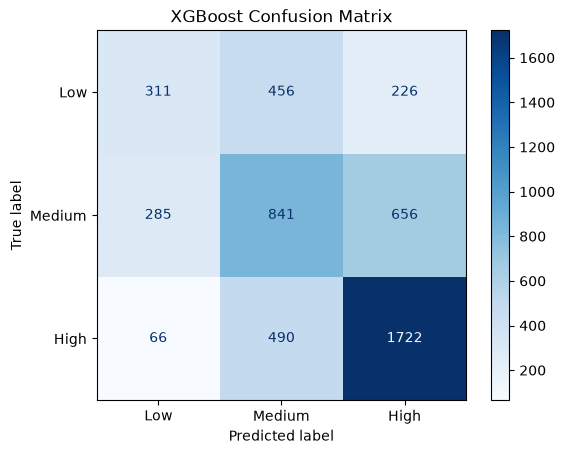

In [80]:
# confusion matrix visualization

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("XGBoost Confusion Matrix")
plt.show()



Confusion Matrix
- Low severity: Of 993 actual Low claims, the model correctly classified 311. It misclassified 456 as Medium and 226 as High. Low claims are the hardest class for this model to identify correctly.

- Medium severity: Of 1,782 actual Medium claims, the model correctly classified 841. It misclassified 285 as Low and 656 as High. The model frequently confuses Medium claims with High claims.

- High severity: Of 2,278 actual High claims, the model correctly classified 1,722. It misclassified 490 as Medium and 66 as Low. The model performs best at identifying High-severity claims.

# 3. Multilayer Perceptron — MLP

In [81]:
# Train MLP neural network
from sklearn.neural_network import MLPClassifier

# Initialize the MLP neural network
mlp_model = MLPClassifier(
    hidden_layer_sizes=(100, 50), # tow hidden layers with 100 neurons and 50 neurons
    activation='relu', # help network learn non-linear patterns
    solver='adam', # adjusts the network's weights during training
    max_iter=300,
    early_stopping=True, # stop training if validation performance stops improving
    random_state=42
)

# Train the model
mlp_model.fit(X_train_combined, y_train)

# Predict claim severity
y_pred_mlp = mlp_model.predict(X_test_combined)

print("MLP training complete.")
print("Number of predictions:", len(y_pred_mlp))

MLP training complete.
Number of predictions: 5053


In [82]:
# Evaluate the MLP model

# Calculate accuracy
print("MLP Accuracy:", accuracy_score(y_test, y_pred_mlp))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_mlp,
    labels=['High','Low', 'Medium', ],
    zero_division=0
))

# Numerical confusion matrix
cm_mlp = confusion_matrix(
    y_test,
    y_pred_mlp,
    labels=['Low', 'Medium', 'High']
)

print("\nConfusion Matrix:")
print("Rows = Actual classes; Columns = Predicted classes")
print("Class order: Low, Medium, High")
print(cm_mlp)


MLP Accuracy: 0.5602612309519097

Classification Report:
              precision    recall  f1-score   support

        High       0.65      0.78      0.71      2278
         Low       0.43      0.32      0.37       993
      Medium       0.46      0.42      0.44      1782

    accuracy                           0.56      5053
   macro avg       0.52      0.50      0.51      5053
weighted avg       0.54      0.56      0.55      5053


Confusion Matrix:
Rows = Actual classes; Columns = Predicted classes
Class order: Low, Medium, High
[[ 320  430  243]
 [ 337  740  705]
 [  83  424 1771]]


- Accuracy of 56.02%, meaning the model classifies appropriately 56 out of every 100 test claim.
- High severity: Recall is 78%, meaning the model identifies approximately 78% of genuinely High-severity claims and misses about 22%.
- Low severity: Recall is only 32%, so the model struggles to identify this class correctly.
- Medium severity: Recall is 42%, meaning many Medium claims are being assigned another category.

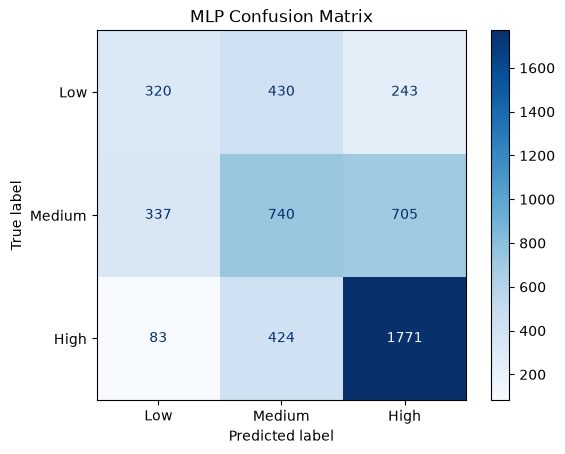

In [83]:
# confusion matrix visualization
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("MLP Confusion Matrix")
plt.show()



Confusion Matrix
- Low severity: Of 993 actual Low claims, the model correctly classified 320. It misclassified 430 as Medium and 243 as High. The model struggles to identify Low claims correctly.

- Medium severity: Of 1,782 actual Medium claims, the model correctly classified 740. It misclassified 337 as Low and 705 as High. Medium claims are frequently confused with High claims.

- High severity: Of 2,278 actual High claims, the model correctly classified 1,771. It misclassified 424 as Medium and 83 as Low. The model performs best at identifying High-severity claims.

**Note:** The MLP is effective at identifying High-cost claims, which could be useful for prioritising claims for review. 

### Final Model Comparison

In [84]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Compare the three models
models = {
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'MLP Neural Network': y_pred_mlp
}

results = []

for model_name, y_pred in models.items():
    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Low Recall': recall_score(
            y_test, y_pred, labels=['Low'], average=None
        )[0],
        'Medium Recall': recall_score(
            y_test, y_pred, labels=['Medium'], average=None
        )[0],
        'High Recall': recall_score(
            y_test, y_pred, labels=['High'], average=None
        )[0],
        'Macro F1-Score': f1_score(
            y_test, y_pred, average='macro'
        )
    })

comparison_df = pd.DataFrame(results)

# Display scores as percentages
comparison_df[['Accuracy', 'Low Recall', 'Medium Recall',
               'High Recall', 'Macro F1-Score']] *= 100

comparison_df = comparison_df.round(2)

comparison_df

,Model,Accuracy,Low Recall,Medium Recall,High Recall,Macro F1-Score
0,Random Forest,54.90,36.66,41.08,73.66,50.42
1,XGBoost,56.88,31.32,47.19,75.59,51.75
2,MLP Neural Network,56.03,32.23,41.53,77.74,50.55


The MLP Neural Network was selected because it achieved the highest High-severity recall of 77.74%,(which aligns with the project's priority of minimising missed High-severity claims while acknowledging that identifying Low- and Medium-severity claims remains a challenge.) making it the best of the three models at identifying High-severity insurance claims. This is important because failing to identify a High-severity claim could lead to inadequate prioritisation during claims handling.

# **Feature Importance**
> - It indicates how much a feature contributes to the Random Forest's predictive decisions; it does not establish that the feature causes higher claim severity.

In [85]:
# Combine structured feature names and TF-IDF keyword names
feature_names = (
    X_train_no_estimate.columns.tolist()
    + tfidf.get_feature_names_out().tolist()
)

# Extract feature importance from the trained Random Forest
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

# Display the 15 most important features
importance_df = importance_df.sort_values(
    by='Importance', ascending=False
)

importance_df.head(20)

,Feature,Importance
3,WeeklyRate,0.055560
2,Age,0.047873
0,ReportingDelay,0.041903
8,AccidentYear,0.037839
1,AccidentHour,0.034748
4,HoursWorkedPerWeek,0.033874
9,AccidentMonth,0.033545
400,strain,0.032184
42,back,0.029311
10,AccidentDayOfWeek,0.028196


- WeeklyRate (0.0556): The most important feature, suggesting that the employee's weekly pay contributes to severity predictions.
- Age (0.0479): The employee's age helps the model distinguish between severity categories.
- ReportingDelay (0.0419): The time taken to report a claim contributes to the predictions.
- AccidentYear (0.0378) and AccidentMonth (0.0335): The timing of the accident provides useful predictive information.
- AccidentHour (0.0347) and HoursWorkedPerWeek (0.0339): The time of the accident and working hours also influence predictions.
- Claim-description keywords: Terms such as strain, back, lacer, left, strike, right and shoulder indicate that descriptions of injuries and accident circumstances contribute to the model's predictions thus showing that NLP adds useful information beyond the structured data.

# **Dimensionality Reduction**

# 1. TruncatedSVD

Truncated Singular Value Decomposition (SVD) is a technique that reduces the number of features in a dataset while preserving as much useful information as possible.

How does it work?
- It identifies the most important patterns across the features.
- It combines related features into a smaller set of new features called components.
- It removes less informative dimensions, making the dataset smaller and easier for machine learning models to process.
How we used it in our project:

We applied Truncated SVD to the combined structured insurance data and TF-IDF text features to reduce the number of features before modelling.

In simple terms: Imagine summarising a long document into its most important points. Truncated SVD does something similar with data, retaining key patterns while reducing complexity.

In [86]:
print("Training data shape:", X_train_combined.shape)
print("Testing data shape:", X_test_combined.shape)
print("Training data type:", type(X_train_combined))

Training data shape: (16615, 488)
Testing data shape: (5053, 488)
Training data type: <class 'scipy.sparse._csr.csr_matrix'>


data is stored as a sparse matrix, which is efficient for TF-IDF features. Because of this, TruncatedSVD will be used rather than ordinary PCA. It works directly with sparse matrices and serves a similar dimensionality-reduction purpose for the combined data.

In [87]:
# Fit TruncatedSVD
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=200, random_state=42) # 200 components since data has 488 features

X_train_reduced = svd.fit_transform(X_train_combined)

print("Original training shape:", X_train_combined.shape)
print("Reduced training shape:", X_train_reduced.shape)
print("Explained variance ratio:", svd.explained_variance_ratio_.sum())

Original training shape: (16615, 488)
Reduced training shape: (16615, 200)
Explained variance ratio: 0.9999661462405841


Applied Truncated SVD to reduce the dataset from 488 features to 200 components, thus reducing dimensionality by approximately 59% while retaining 99.997% of the measured variance. This simplified the feature space for subsequent machine learning tasks. Explained variance does not necessarily mean that 99.997% of the information useful for predicting claim severity was retained.

In [88]:
# Transform the testing data
X_test_reduced = svd.transform(X_test_combined)

print("Reduced training shape:", X_train_reduced.shape)
print("Reduced testing shape:", X_test_reduced.shape)

Reduced training shape: (16615, 200)
Reduced testing shape: (5053, 200)


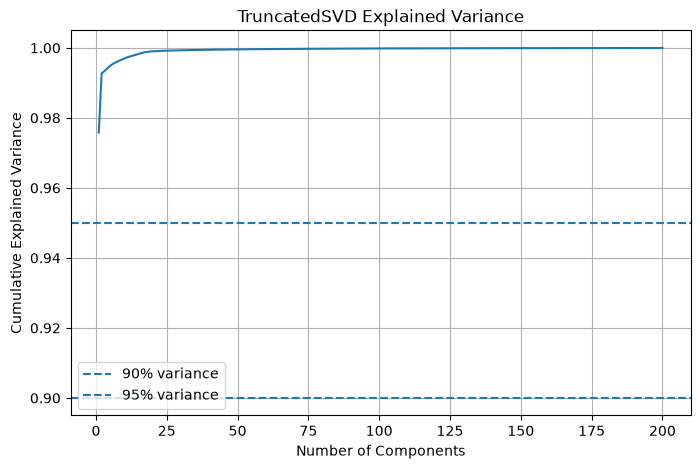

Variance explained by 200 components: 1.0


In [89]:
# Check explained variance
cumulative_variance = np.cumsum(svd.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(y=0.90, linestyle='--', label='90% variance')
plt.axhline(y=0.95, linestyle='--', label='95% variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('TruncatedSVD Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

print("Variance explained by 200 components:",
      round(cumulative_variance[-1], 4))

The curve shoots up nearly vertically at the very beginning and completely flattens out. Adding components beyond the first 5 contributes almost zero new information.

The 90% and 95% variance thresholds (indicated by the dash lines) are crossed almost instantly with just a couple of commponents

Recommendations: Keeping all 200 components is highly ineffecient as most of them carry redundant or irrelevant information (noise), thus the 200 features should be reduced to 2-5 components which will sigificantly speed up the models training and because the first few components capture the variance, the models accuracy will remain virtually unchanged despite using less data.

In [90]:
# Finding how many components reach 90% and 95%
cumulative_variance = np.cumsum(svd.explained_variance_ratio_)

components_90 = np.argmax(cumulative_variance >= 0.90) + 1
components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components needed for 90% variance:", components_90)
print("Components needed for 95% variance:", components_95)

print("Variance with first 5 components:",
      round(cumulative_variance[4], 6))

print("Variance with first 10 components:",
      round(cumulative_variance[9], 6))

print(np.round(cumulative_variance[:10], 6))

Components needed for 90% variance: 1
Components needed for 95% variance: 1
Variance with first 5 components: 0.994834
Variance with first 10 components: 0.996967
[0.975812 0.992731 0.993339 0.994169 0.994834 0.995456 0.995867 0.996258
 0.996628 0.996967]


The output indicates that 1 component is enough to reach both 90% and 95% variance, according to the calculation you ran. However, this looks unusual given your earlier Truncated SVD result of 200 components retaining 99.9966% variance. The first component alone apparently explains 97.58% of the variance, while the first five explain 99.4834%.



results show that small number of SVD components retain a high propotion of the variance.

## Testing other number of components to see how much variance is captured

In [91]:
import pandas as pd
from sklearn.decomposition import TruncatedSVD

# Number of components to test
component_counts = [2, 3, 5, 10, 20, 30, 38, 40, 50]

results = []

for n in component_counts:
    svd = TruncatedSVD(n_components=n, random_state=42)
    svd.fit(X_train_combined)

    results.append({
        "Components": n,
        "Cumulative Explained Variance": svd.explained_variance_ratio_.sum()
    })

# Display results
results_df = pd.DataFrame(results).set_index("Components")
print(results_df.round(6))

            Cumulative Explained Variance
Components                               
2                                0.992731
3                                0.993339
5                                0.994834
10                               0.996967
20                               0.999027
30                               0.999314
38                               0.999438
40                               0.999463
50                               0.999571


Reducing it to just 3 components retains 99.33% of the explained variance

In [92]:
# Reduce the data to 3 components

from sklearn.decomposition import TruncatedSVD

svd_3 = TruncatedSVD(n_components=3, random_state=42)

X_train_svd3 = svd_3.fit_transform(X_train_combined)
X_test_svd3 = svd_3.transform(X_test_combined)

print("Training shape:", X_train_svd3.shape)
print("Testing shape:", X_test_svd3.shape)
print("Explained variance:",
      round(svd_3.explained_variance_ratio_.sum(), 4))

Training shape: (16615, 3)
Testing shape: (5053, 3)
Explained variance: 0.9933


# 2. t-SNE
- t-SNE reduces THE data to 2 dimensions to visualise how the insurance claims are distributed. t-SNE rearranges the data to show local similarities, so distances between separate groups should not be interpreted as reliable measures of their original separation.

In [93]:

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Use a sample of the training data
sample_size = 3000
rng = 42

sample_indices = np.random.RandomState(rng).choice(
    X_train_svd3.shape[0],
    size=sample_size,
    replace=False
)

X_tsne_input = X_train_svd3[sample_indices]

# Apply t-SNE to reduce the data to 2 dimensions
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_tsne_input)

print("Original sampled shape:", X_tsne_input.shape)
print("t-SNE shape:", X_tsne.shape)


Original sampled shape: (3000, 3)
t-SNE shape: (3000, 2)


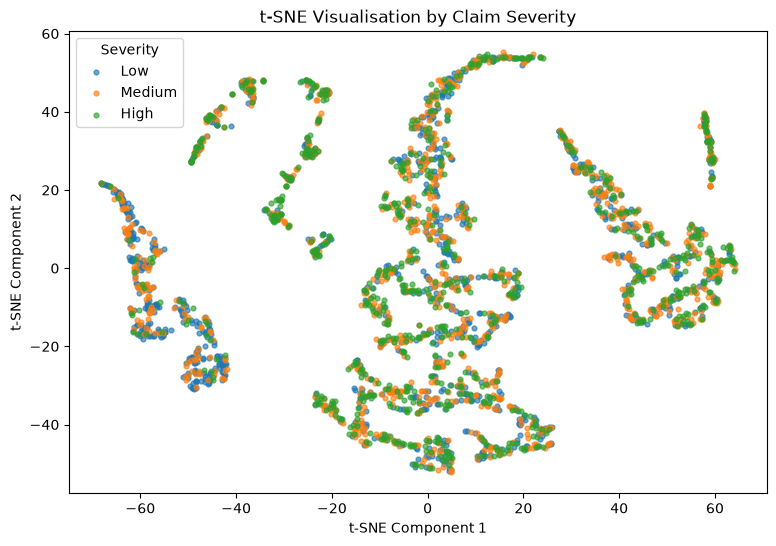

In [94]:
# plot the results

# Get the severity labels for the same sampled claims
y_tsne = y_train.iloc[sample_indices]

plt.figure(figsize=(9, 6))

for severity in ["Low", "Medium", "High"]:
    mask = y_tsne.to_numpy() == severity

    plt.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        label=severity,
        s=12,
        alpha=0.65
    )

plt.title("t-SNE Visualisation by Claim Severity")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(title="Severity")
plt.show()


The t-SNE visualisation shows substantial overlap between Low, Medium and High severity claims, with no clearly separated groups for the three classes. This suggests that claims with different severity levels share similarities in the reduced feature space.

However, t-SNE is an exploratory visualisation technique and the overlap does not necessarily mean that the original features lack predictive information. The ability to distinguish severity levels must be assessed using classification metrics.

**Conclusion:** The visualisation does not reveal clear severity-based groupings, supporting further investigation through clustering techniques and evaluation of classification performance.

# 3. UMAP

In [95]:
import umap

# Use the same sample as the t-SNE visualisation
X_umap_input = X_train_svd3[sample_indices]

# Apply UMAP to reduce to 2 dimensions
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

X_umap = umap_model.fit_transform(X_umap_input)

print("Original sampled shape:", X_umap_input.shape)
print("UMAP shape:", X_umap.shape)


c:\Users\User\OneDrive\Documents\Final_Capstone_Project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\User\OneDrive\Documents\Final_Capstone_Project\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Original sampled shape: (3000, 3)
UMAP shape: (3000, 2)


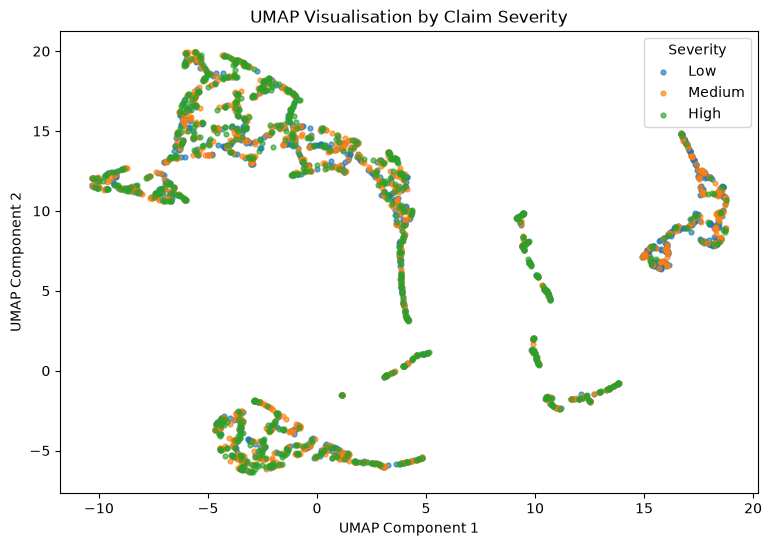

In [96]:
# visualizing

y_umap = y_train.iloc[sample_indices]

plt.figure(figsize=(9, 6))

for severity in ["Low", "Medium", "High"]:
    mask = y_umap.to_numpy() == severity

    plt.scatter(
        X_umap[mask, 0],
        X_umap[mask, 1],
        label=severity,
        s=12,
        alpha=0.65
    )

plt.title("UMAP Visualisation by Claim Severity")
plt.xlabel("UMAP Component 1")
plt.ylabel("UMAP Component 2")
plt.legend(title="Severity")
plt.show()



The UMAP visualisation reveals distinct branch-like structures and groupings within the insurance claims data, suggesting that the feature space contains underlying patterns or subgroups. However, Low, Medium, and High severity claims overlap substantially across these structures, with no clearly isolated groups corresponding to individual severity classes.

This suggests that the patterns captured by UMAP do not directly correspond to clear severity-based groupings. Although the features may contain useful information, severity prediction remains challenging because the classes are not clearly separated in this two-dimensional representation.

**Conclusion:** UMAP reveals underlying structures in the claims data, but these structures do not clearly distinguish severity levels. Classification performance must therefore be assessed using evaluation metrics rather than visualisation alone.

# **Clustering**

# 1. K-Means
> - K-Means is an unsupervised method—it groups claims by feature similarity rather than directly predicting severity.

In [97]:
# testing different numbers of clusters using silhouette score

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test between 2 and 6 clusters
k_values = range(2, 7) # 2, 3, 4, 5, 6
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_train_svd3)

    score = silhouette_score(
        X_train_svd3,
        cluster_labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_scores.append(score)
    print(f"k = {k}, Silhouette Score = {score:.4f}")


k = 2, Silhouette Score = 0.8719
k = 3, Silhouette Score = 0.8324
k = 4, Silhouette Score = 0.8549
k = 5, Silhouette Score = 0.8106
k = 6, Silhouette Score = 0.8123


k = 2 has the highest silhouette score of 0.8719, suggesting the strongest separation among the tested options.

In [98]:
# Fit K-Means with 2 clusters
# Combine the original training data with the K-Means cluster labels - This assigns each training claim to its cluster and counts the claims in each group

from sklearn.cluster import KMeans

kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Fit clusters using training data only
train_clusters = kmeans_2.fit_predict(X_train_svd3)

# Examine cluster sizes
cluster_sizes = pd.Series(train_clusters).value_counts().sort_index()

print("Number of claims in each cluster:")
print(cluster_sizes)


Number of claims in each cluster:
0     2954
1    13661
Name: count, dtype: int64


The clusters are quite imbalanced in size: Cluster 1 contains about 82%, 13,661 of the claims, while Cluster 0 contains about 18%, 2,954.

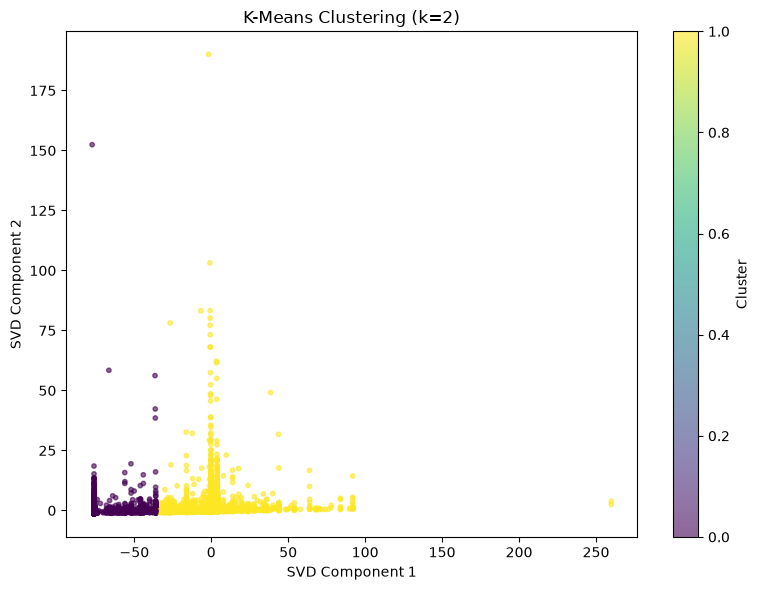

In [99]:
# Visualize K-Means clusters (k=2)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_svd3[:, 0],
    X_train_svd3[:, 1],
    c=train_clusters,
    cmap="viridis",
    s=10,
    alpha=0.6
)

plt.title("K-Means Clustering (k=2)")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()


used SVD component 1 and 2 to visualize clusters in 2D
- Cluster 0 (dark purple): It is concentrated where SVD component 1 is negative, it is tightly packed and remains low on the y-axis
- Cluster 1 (yellow): It is concentrated heavily around the zero mark on the x-axis, where it forms a massive vertical spike extending all the way up to around 75 on the y-axis
- There is a very sharp, dense boundary where the two clusters meet near SVD component 1 = -25
- There are two extreme data points/outliers, a single dark purple and a single yellow data point.
- The current yellow cluster has a very tall vertical structure and a long horizontal tail, suggesting that it can contain multiple sub groups that k = 2 is forcing.

In [100]:
# Fit K-Means with 4 clusters
# Combine the original training data with the K-Means cluster labels - This assigns each training claim to its cluster and counts the claims in each group

from sklearn.cluster import KMeans

kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Fit clusters using training data only
train_clusters = kmeans_4.fit_predict(X_train_svd3)

# Examine cluster sizes
cluster_sizes = pd.Series(train_clusters).value_counts().sort_index()

print("Number of claims in each cluster:")
print(cluster_sizes)


Number of claims in each cluster:
0      258
1     2436
2    13030
3      891
Name: count, dtype: int64


Cluster 2 contains the majority of claims (78.43%), while Cluster 0 is very small (1.55%). This suggests that K-Means has identified one dominant group and three smaller groups. 

Settled for k = 4 (the one with the second highest silhouette score) since it will help explore different patterns in insurance claims as it gives more groups to investigate. However, cluster sizes are uneven, and a higher number of clusters isn't automatically better. 

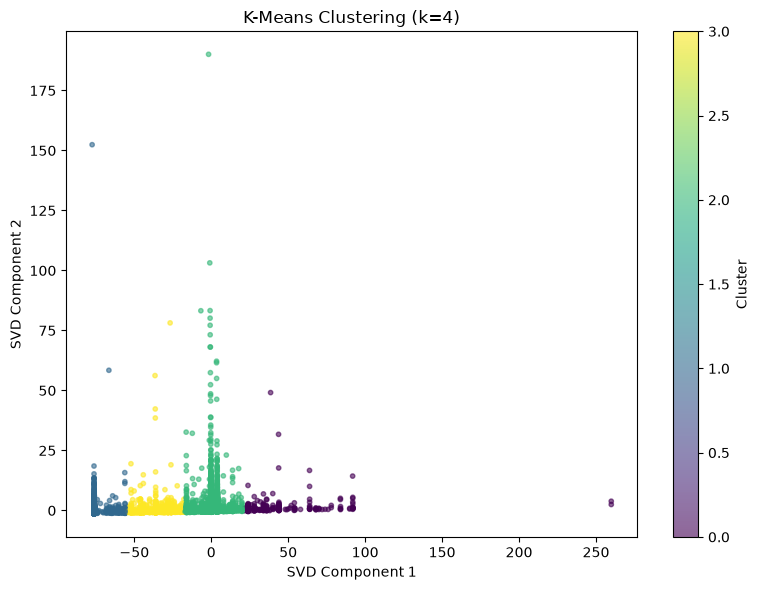

In [101]:
# Visualize K-Means clusters (k=4)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_svd3[:, 0],
    X_train_svd3[:, 1],
    c=train_clusters,
    cmap="viridis",
    s=10,
    alpha=0.6
)

plt.title("K-Means Clustering (k=4)")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

used SVD component 1 and 2 to visualize clusters in 2D
- Cluster 0 (navy blue): It is concentrated heavily where SVD component 1 is less than -50. It captures a high-density concentration of points. These share moderate values across both components, forming the core baseline or modal behavior of your dataset.
- Cluster 1 (yellow): clustered densly between where SVD component 1 is -50 and 0. It represents a distinct, tightly bound cohort of data points with negative projection values on the first component. Their separation from the rest of the plot suggests a fundamentally different behavioral profile or categorical group.
- Cluster 2 (green): It shoots up the vertical column, reaching SVD components 2 values up to nearly 175. This is the high-magnitude vertical pillar. It groups instances that share a very specific alignment on component 1 but stretch draamatically along component 2. This typically indicates an extreme scaling effect or a specific sub set where a single metric grows exponentially while other features remain constanta.
- Cluster 3 (dark purple): It is scattered along the baseline from 25 to over 100. It represents data points with low variance on component 2 but  oderate to high values along component 1. These likely correspond to common, routine instances or secondary categories that sit apart from the main mass.

Overall:

K-means is struggling to find balanced groups because the underlying data distribution is heavily skewed despite scaling.

In [102]:
# Attach the existing K-Means cluster labels to the original training data
kmeans_interpretation = model_df.loc[train_mask].copy()

kmeans_interpretation["Cluster"] = train_clusters

# Check that the rows match
print("Training data shape:", kmeans_interpretation.shape)
print("\nNumber of claims in each cluster:")
print(kmeans_interpretation["Cluster"].value_counts().sort_index())

Training data shape: (16615, 20)

Number of claims in each cluster:
Cluster
0      258
1     2436
2    13030
3      891
Name: count, dtype: int64


### Examine severity distribution within each cluster

In [103]:
# Count severity classes within each cluster
cluster_severity = pd.crosstab(
    kmeans_interpretation["Cluster"],
    kmeans_interpretation["Severity"]
)

print(cluster_severity)

Severity  High   Low  Medium
Cluster                     
0          103    69      86
1          235  1553     648
2         4198  4288    4544
3          337   248     306


- Cluster 0: Relatively balanced, with High claims making up the largest group.
- Cluster 1: Dominated by Low-severity claims (about 64%).
- Cluster 2: Contains most of the claims and has a fairly balanced severity distribution.
- Cluster 3: Relatively balanced, with High claims slightly more common than the other classes.

In [104]:
# percentages
# Calculate severity percentages within each cluster
cluster_severity_pct = pd.crosstab(
    kmeans_interpretation["Cluster"],
    kmeans_interpretation["Severity"],
    normalize="index"
) * 100

print(cluster_severity_pct.round(2))

Severity   High    Low  Medium
Cluster                       
0         39.92  26.74   33.33
1          9.65  63.75   26.60
2         32.22  32.91   34.87
3         37.82  27.83   34.34


- Cluster 0 has the highest proportion of High-severity claims, at 39.92%.
- Cluster 1 is the clearest group, with nearly 64% Low-severity claims and fewer than 10% High-severity claims.
- Cluster 2 contains most of your claims and has a relatively balanced severity distribution.
- Cluster 3 also has a higher proportion of High-severity claims than the overall dataset.

### Investigate the numerical features across clusters

The numerical features will be compared across the four clusters to identify differences in claim characteristics. This will help explain what distinguishes each cluster and complement the severity distribution analysis.

In [105]:
# Select numerical input features
numeric_cols = kmeans_interpretation.select_dtypes(
    include="number"
).columns.tolist()

numeric_cols = [
    col for col in numeric_cols
    if col not in ["Incurred", "InitialCaseEstimate", "Cluster"]
]

# Compare median feature values across clusters
cluster_numeric_profile = (
    kmeans_interpretation
    .groupby("Cluster")[numeric_cols]
    .median()
    .T
)

display(cluster_numeric_profile.round(2))


Cluster,0,1,2,3
ReportingDelay,22.0,25.0,22.0,23.0
AccidentHour,11.0,11.0,11.0,11.0
Age,34.0,30.0,32.0,31.0
WeeklyRate,524.5,0.0,346.0,228.4
HoursWorkedPerWeek,56.0,0.0,38.0,20.0
DependentChildren,0.0,0.0,0.0,0.0
DependentsOther,0.0,0.0,0.0,0.0
DaysWorkedPerWeek,6.0,5.0,5.0,4.0


**NB:** Medians were used because they represent typical values within each cluster and are less affected by extreme values.

- **Cluster 0 (258 claims):** Claims involving workers with a median age of 34, a relatively high weekly rate of 524.5, and 56 working hours per week. This cluster also has a median of 6 working days per week.
- **Cluster 1 (2,436 claims):** Claims involving workers with a median age of 30, a weekly rate of 0, and 0 working hours per week. These values may indicate workers with no recorded earnings or working hours and warrant further investigation.
- **Cluster 2 (13,030 claims):** The largest cluster, with a median age of 32, weekly rate of 346, 38 working hours per week, and a reporting delay of 22 days.
- **Cluster 3 (891 claims):** Claims involving workers with a median age of 31, weekly rate of 228.4, 20 working hours per week, and 4 working days per week.

**Overall insights:**
- Cluster 2 contains the majority of claims and has typical working hours and weekly rates that fall between those of Clusters 0 and 3.
- Cluster 0 stands out for its higher weekly rate, longer working hours, and six working days per week.
- Cluster 1 is characterized by zero median weekly earnings and working hours. This may reflect missing or genuinely zero values and should be investigated before drawing conclusions.
- Cluster 3 has the lowest non-zero median weekly rate and fewer working hours than Clusters 0 and 2.
- All four clusters have similar median reporting delays (22–25 days) and accident hours (11:00), so these features do not clearly distinguish the clusters based on their medians.
- The median numbers of dependent children and other dependents are zero across all clusters, meaning these features do not distinguish the clusters well using median values alone.

## Investigating cluster 0 claim characteristics

In [106]:
# Filter claims belonging to Cluster 0
cluster_0 = kmeans_interpretation[
    kmeans_interpretation["Cluster"] == 0
]

# Examine numerical feature distributions
display(cluster_0[numeric_cols].describe().round(2))

# Examine severity distribution
print("Severity counts in Cluster 0:")
print(cluster_0["Severity"].value_counts())

print("\nSeverity percentages in Cluster 0:")
print(
    (cluster_0["Severity"].value_counts(normalize=True) * 100)
    .round(2)
)

,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek
count,258.00,258.00,258.00,258.00,258.00,258.00,258.00,258.00
mean,50.11,11.53,35.47,596.38,59.47,0.15,0.02,5.74
std,116.31,3.63,10.85,531.08,13.75,0.59,0.17,0.84
min,1.00,1.00,14.00,0.00,49.00,0.00,0.00,3.00
25%,13.25,9.00,27.00,200.00,50.00,0.00,0.00,5.00
50%,22.00,11.00,34.00,524.50,56.00,0.00,0.00,6.00
75%,42.75,14.00,42.00,764.40,60.00,0.00,0.00,6.00
max,1388.00,22.00,66.00,5811.30,168.00,5.00,2.00,7.00


Severity counts in Cluster 0:
Severity
High      103
Medium     86
Low        69
Name: count, dtype: int64

Severity percentages in Cluster 0:
Severity
High      39.92
Medium    33.33
Low       26.74
Name: proportion, dtype: float64


- **Reporting delay:** The median reporting delay is 22 days, while the mean is 50.11 days and the maximum is 1,388 days. The difference between the mean and median suggests that some claims have exceptionally long reporting delays.
- **Age:** Claimants have a median age of 34 years, with ages ranging from 14 to 66 years.
- **Weekly rate:** The median weekly rate is 524.50, while the mean is 596.38. The maximum of 5,811.30 indicates that some claims involve substantially higher weekly rates.
- **Working hours:** The median is 56 hours per week, and the mean is 59.47 hours. The maximum of 168 hours is unusually high and may warrant checking for data-entry errors or unusual recorded values.
- **Working days:** The median is 6 days per week, suggesting that a typical claimant in this cluster works six days weekly.
- **Dependents:** The median number of dependent children and other dependents is zero, indicating that at least half of the claims have no recorded dependents in either category.

**Severity distribution:**
- High: 103 claims (39.92%).
- Medium: 86 claims (33.33%).
- Low: 69 claims (26.74%).

High-severity claims form the largest category in Cluster 0, accounting for approximately 40% of its claims. However, this distribution alone does not establish that higher weekly rates or longer working hours cause greater claim severity.

**Overall insight:** Cluster 0 contains 258 claims characterized by a median weekly rate of 524.50, 56 working hours per week, and six working days per week. It also contains a relatively substantial proportion of High-severity claims. The unusually large maximum values for reporting delay, weekly rate, and working hours warrant further investigation.

### investigate the High-severity claims within Cluster 0

In [107]:
#--------------------------------------------
# Examine High-severity claims in Cluster 0
#-------------------------------------------

# Filter High-severity claims in Cluster 0
cluster_0_high = cluster_0[
    cluster_0["Severity"] == "High"
]

# Summarize their numerical features
display(
    cluster_0_high[numeric_cols]
    .describe()
    .round(2)
)

,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek
count,103.00,103.00,103.00,103.00,103.00,103.00,103.00,103.00
mean,61.52,11.30,36.83,747.20,60.27,0.13,0.03,5.92
std,168.41,3.67,10.76,666.90,14.95,0.48,0.17,0.82
min,6.00,1.00,19.00,0.00,50.00,0.00,0.00,5.00
25%,14.00,9.00,27.50,428.10,50.00,0.00,0.00,5.00
50%,24.00,11.00,36.00,649.04,56.00,0.00,0.00,6.00
75%,42.00,14.00,45.50,886.98,61.25,0.00,0.00,7.00
max,1388.00,22.00,59.00,5811.30,168.00,3.00,1.00,7.00


- **Reporting delay:** High-severity claims have a median reporting delay of 24 days and a mean of 61.52 days. The maximum of 1,388 days suggests that a few claims experienced exceptionally long reporting delays.
- **Age:** The median claimant age is 36 years, with ages ranging from 19 to 59 years.
- **Weekly rate:** The median weekly rate is 649.04, while the mean is 747.20. The maximum of 5,811.30 indicates substantial variation in recorded weekly rates.
- **Working hours:** The median is 56 hours per week, and the mean is 60.27 hours. The maximum of 168 hours warrants further investigation as a potentially unusual recorded value.
- **Working days:** The median is 6 days per week, indicating that a typical claimant in this group works six days weekly.
- **Dependents:** The median number of dependent children and other dependents is zero, meaning at least half of these claims have no recorded dependents in either category.

**Overall insight:** The 103 High-severity claims in Cluster 0 have a median age of 36 years, a median weekly rate of 649.04, and median working hours of 56 per week. Some claims also have exceptionally high reporting delays and weekly rates. These are descriptive patterns; further analysis is needed to determine which characteristics distinguish High-severity claims from Low- and Medium-severity claims within this cluster.

### Compare High-severity claims with Low- and Medium-severity claims within Cluster 0.

In [108]:
# Compare median numerical features by severity within Cluster 0
cluster_0_severity_profile = (
    cluster_0
    .groupby("Severity")[numeric_cols]
    .median()
    .T
)

display(cluster_0_severity_profile.round(2))

Severity,High,Low,Medium
ReportingDelay,24.00,16.00,28.50
AccidentHour,11.00,12.00,12.00
Age,36.00,32.00,33.00
WeeklyRate,649.04,440.00,460.77
HoursWorkedPerWeek,56.00,53.75,56.50
DependentChildren,0.00,0.00,0.00
DependentsOther,0.00,0.00,0.00
DaysWorkedPerWeek,6.00,6.00,6.00


- **Reporting delay:** High-severity claims have a median reporting delay of 24 days, compared with 16 days for Low and 28.5 days for Medium claims.
- **Age:** High-severity claimants have the highest median age at 36 years, compared with 32 years for Low and 33 years for Medium claims.
- **Weekly rate:** High-severity claims have the highest median weekly rate (649.04), compared with 440.00 for Low and 460.77 for Medium claims.
- **Working hours:** Median working hours are similar across severity categories, ranging from 53.75 to 56.5 hours per week.
- **Accident hour:** Low- and Medium-severity claims have a median accident hour of 12:00, while High-severity claims have a median of 11:00.
- **Dependents and working days:** The median number of dependents is zero across all severity categories, while median working days are six per week for all three.

**Overall insight:** Within Cluster 0, High-severity claims are characterized by higher median weekly rates and older claimants. However, working hours, working days, and dependent counts show little variation across severity categories. These are descriptive associations and do not establish causation.

## Investigating claim descriptions for cluster 0

In [109]:
# View claim descriptions in Cluster 0
cluster_0_descriptions = cluster_0["ClaimDescription"]

# Display the first 10 descriptions
display(cluster_0_descriptions.head(10))

86               LIFTING STOCK STRAIN LEFT SHOULDER LEFT
138              LIFTING CHAIR STRAINED RIGHT UPPER BACK
315    STRUCK FALLING PALLET STRAIN LOWER BACK STRAIN...
357    STRUCK FALLING TIMBER BRUISED NECK AND BACK AN...
415        HIT HAND ON HAND LACERATION LEFT HAND FINGERS
504                   LIFTING PIPES STRAINED BACK STRAIN
628    STRUCK FALLING BOX STRAINED SHOULDER STRAIN LE...
672                     STRUCK TROLLEY BRUISED LEFT PALM
745                    STRUCK KNIFE LACERATED LEFT THUMB
761       SLIPPED WHILST GRINDING FOREIGN BODY RIGHT EYE
Name: ClaimDescription, dtype: str

These 10 descriptions from Cluster 0 show recurring injury patterns, particularly:
- Strains: shoulder and back injuries, often associated with lifting.
- Impact injuries: being struck by falling objects such as pallets, timber, and boxes.
- Cuts and other injuries: hand lacerations, bruising, and a foreign body in the eye.

In [110]:
# Identify the most frequent words in Cluster 0
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words="english")
cluster_0_text_matrix = vectorizer.fit_transform(
    cluster_0["ClaimDescription"].dropna()
)

word_counts = cluster_0_text_matrix.sum(axis=0).A1

cluster_0_word_frequency = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "Frequency": word_counts
}).sort_values("Frequency", ascending=False)

display(cluster_0_word_frequency.head(15))


,Word,Frequency
74,left,123
102,right,113
122,strain,103
124,struck,77
76,lifting,71
79,lower,65
69,knife,50
71,lacerated,44
39,eye,43
109,slipped,38


Cluster 0 contains 258 claims, and the most frequent words suggest three main patterns:
- Strain injuries: strain (103), lifting (71), lower (65), and shoulder (33) suggest frequent muscle strains, particularly involving lifting and the lower back.
- Impact-related injuries: struck (77) suggests injuries caused by being hit by objects.
- Cuts and specific body parts: knife (50), lacerated (44), eye (43), thumb (34), and finger (34) indicate cuts and injuries affecting the hands and eyes.

The words left (123) and right (113) mainly identify which side of the body was injured.

Conclusion: Cluster 0 combines several workplace injury patterns, particularly strains from lifting, impact injuries, and cuts. This is consistent with the sample descriptions you examined. However, word frequencies alone do not establish injury severity or causation

In [111]:
# Examine whether these text patterns differ between high, medium and low severity claims
# compare the most frequent words in High, Medium, and Low severity claims within Cluster 0


from sklearn.feature_extraction.text import CountVectorizer

for severity in ["High", "Medium", "Low"]:
    severity_text = cluster_0.loc[
        cluster_0["Severity"] == severity, "ClaimDescription"
    ].dropna()

    vectorizer = CountVectorizer(stop_words="english", max_features=10)
    text_matrix = vectorizer.fit_transform(severity_text)

    word_counts = text_matrix.sum(axis=0).A1

    word_frequency = pd.DataFrame({
        "Word": vectorizer.get_feature_names_out(),
        "Frequency": word_counts
    }).sort_values("Frequency", ascending=False)

    print(f"\n{severity} Severity — Top 10 Words")
    display(word_frequency)




High Severity — Top 10 Words


,Word,Frequency
7,strain,68
3,lower,41
4,right,41
1,left,37
2,lifting,37
9,struck,23
5,shoulder,20
6,slipped,14
8,strained,14
0,injury,11



Medium Severity — Top 10 Words


,Word,Frequency
3,left,42
6,right,32
9,struck,28
4,lifting,24
7,strain,23
0,knife,23
5,lower,20
1,lacerated,18
2,laceration,15
8,strained,13



Low Severity — Top 10 Words


,Word,Frequency
5,left,44
6,right,40
1,eye,29
8,struck,26
0,body,21
2,foreign,18
4,lacerated,16
3,knife,16
7,slipped,16
9,thumb,16


- High severity consists of strain, lower, lifting, shoulder - comprises of strain-related injuries, particularly involving lifting and the lower back, are prominent.

- Medium severity consists of struck, lifting, starin, knife, laceration - a mixture of strain injuries, impact injuries and cuts appears frequently.

- Low severity consists of eye, foreign body, knife, thumb and slipped - descriptions more frequently mention foreign bodies in the eye, cuts and slipping incidents.

**NB:** This are descriptive patterns and not proof that a particular injury causes a severity level.

## Investigating cluster 1 claim characteristics

In [112]:
#------------------------------------------------------------------------
#Step 1: Examine Cluster 1's numerical features and severity distribution
#------------------------------------------------------------------------

# Filter claims belonging to Cluster 1
cluster_1 = kmeans_interpretation[
    kmeans_interpretation["Cluster"] == 1
]

# Examine numerical feature distributions
display(
    cluster_1[numeric_cols]
    .describe()
    .round(2)
)

# Examine severity distribution
print("Severity counts in Cluster 1:")
print(cluster_1["Severity"].value_counts())

print("\nSeverity percentages in Cluster 1:")
print(
    (cluster_1["Severity"].value_counts(normalize=True) * 100)
    .round(2)
)


,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek
count,2436.00,2436.00,2436.00,2436.00,2436.00,2436.00,2436.00,2436.00
mean,42.95,11.70,32.58,10.98,0.47,0.08,0.01,4.82
std,105.68,3.45,12.01,61.38,1.89,0.44,0.11,0.74
min,1.00,0.00,13.00,0.00,0.00,0.00,0.00,1.00
25%,14.00,9.00,23.00,0.00,0.00,0.00,0.00,5.00
50%,25.00,11.00,30.00,0.00,0.00,0.00,0.00,5.00
75%,45.25,14.00,41.00,0.00,0.00,0.00,0.00,5.00
max,4323.00,24.00,73.00,1014.40,10.00,5.00,4.00,7.00


Severity counts in Cluster 1:
Severity
Low       1553
Medium     648
High       235
Name: count, dtype: int64

Severity percentages in Cluster 1:
Severity
Low       63.75
Medium    26.60
High       9.65
Name: proportion, dtype: float64


- **Reporting delay:** The median reporting delay is 25 days, while the mean is 42.95 days. The maximum of 4,323 days suggests that a small number of claims have exceptionally long reporting delays.
- **Age:** The median claimant age is 30 years, with ages ranging from 13 to 73 years.
- **Weekly rate:** The median is zero, and the 75th percentile is also zero. This indicates that at least 75% of claims have a recorded weekly rate of zero. The maximum is 1,014.40.
- **Working hours:** The median is zero hours per week, and the mean is only 0.47 hours. The maximum is 10 hours per week, indicating that most claims have zero recorded working hours.
- **Working days:** The median is 5 days per week, despite the zero median weekly rate and working hours.
- **Dependents:** The median numbers of dependent children and other dependents are both zero.

**Severity distribution:**
- Low: 1,553 claims (63.75%).
- Medium: 648 claims (26.60%).
- High: 235 claims (9.65%).

Low-severity claims dominate Cluster 1, accounting for nearly two-thirds of its claims. High-severity claims represent less than 10%.

**Overall insight:** Cluster 1 contains 2,436 claims, characterized by zero recorded weekly rates and working hours for most observations, alongside a predominantly Low-severity distribution. The zero values warrant investigation to determine whether they reflect genuine circumstances, missing information encoded as zero, or limitations in the dataset. The long reporting-delay outliers also merit attention.

### investigate the High-severity claims within Cluster 1

In [113]:
# Filter High-severity claims in Cluster 1
cluster_1_high = cluster_1[
    cluster_1["Severity"] == "High"
]

# Summarize their numerical features
display(
    cluster_1_high[numeric_cols]
    .describe()
    .round(2)
)

,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek
count,235.00,235.00,235.00,235.00,235.00,235.00,235.00,235.00
mean,39.85,11.81,37.74,42.46,1.59,0.10,0.01,4.49
std,57.63,3.62,12.30,117.85,3.26,0.48,0.09,1.14
min,3.00,0.00,16.00,0.00,0.00,0.00,0.00,1.00
25%,13.50,9.00,28.00,0.00,0.00,0.00,0.00,5.00
50%,23.00,11.00,37.00,0.00,0.00,0.00,0.00,5.00
75%,43.00,14.00,47.00,0.00,0.00,0.00,0.00,5.00
max,469.00,24.00,64.00,875.00,10.00,4.00,1.00,6.00


- **Reporting delay:** High-severity claims have a median reporting delay of 23 days and a mean of 39.85 days. The maximum is 469 days, indicating some substantially delayed reports.
- **Age:** The median claimant age is 37 years, with ages ranging from 16 to 64 years.
- **Weekly rate:** The median weekly rate is zero, and the 75th percentile is also zero. This indicates that at least 75% of these High-severity claims have a recorded weekly rate of zero. The maximum is 875.00.
- **Working hours:** The median is zero hours per week, while the mean is 1.59 hours. The maximum is 10 hours per week, indicating that most claims have zero recorded working hours.
- **Working days:** The median is 5 days per week, this represents the number of days they are supposed to work and not the days they worked.
- **Dependents:** The median numbers of dependent children and other dependents are both zero.

**Overall insight:** The 235 High-severity claims in Cluster 1 have a median age of 37 years, a reporting delay of 23 days, and zero median recorded weekly earnings and working hours. This suggests that the cluster's zero-value pattern also occurs among its High-severity claims. It is important to investigate what these zeros represent before drawing conclusions about employment or earnings.

### Compare High-severity claims with Low- and Medium-severity claims within Cluster 1.

In [114]:
# Compare median numerical features by severity within Cluster 1
cluster_1_severity_profile = (
    cluster_1
    .groupby("Severity")[numeric_cols]
    .median()
    .T
)

display(cluster_1_severity_profile.round(2))

Severity,High,Low,Medium
ReportingDelay,23.0,25.0,27.0
AccidentHour,11.0,11.0,12.0
Age,37.0,28.0,32.0
WeeklyRate,0.0,0.0,0.0
HoursWorkedPerWeek,0.0,0.0,0.0
DependentChildren,0.0,0.0,0.0
DependentsOther,0.0,0.0,0.0
DaysWorkedPerWeek,5.0,5.0,5.0


- **Reporting delay:** High-severity claims have a median reporting delay of 23 days, compared with 25 days for Low and 27 days for Medium claims.
- **Age:** High-severity claimants have the highest median age at 37 years, compared with 28 years for Low and 32 years for Medium claims.
- **Weekly rate and working hours:** The median values are zero across all three severity categories. These results suggest that zero recorded earnings and working hours are common throughout Cluster 1, regardless of severity.
- **Accident hour:** High- and Low-severity claims have a median accident hour of 11:00, while Medium-severity claims have a median of 12:00.
- **Dependents:** The median numbers of dependent children and other dependents are zero across all severity categories.
- **Working days:** All three severity categories have a median of five working days per week.

**Overall insight:** Within Cluster 1, High-severity claims have a higher median claimant age than Low- and Medium-severity claims. However, the median weekly rate, working hours, dependents, and working days are identical across severity categories. Therefore, these median values alone do not explain the differences in severity. Further investigation is needed to understand the zero earnings and working-hours records.

## Check all zero values in cluster 1

In [115]:

cluster_1.groupby("Severity").agg(
    Total_Claims=("Severity", "size"),
    WeeklyRate_Zeros=("WeeklyRate", lambda x: (x == 0).sum()),
    WeeklyRate_Missing=("WeeklyRate", lambda x: x.isna().sum()),
    Hours_Zeros=("HoursWorkedPerWeek", lambda x: (x == 0).sum()),
    Hours_Missing=("HoursWorkedPerWeek", lambda x: x.isna().sum())
)


,Total_Claims,WeeklyRate_Zeros,WeeklyRate_Missing,Hours_Zeros,Hours_Missing
Severity,,,,,
High,235,185,0,184,0
Low,1553,1507,0,1504,0
Medium,648,596,0,592,0


The results show that Cluster 1's zero medians are mainly driven by zero values in WeeklyRate, not HoursWorkedPerWeek.

Important observation: HoursWorkedPerWeek has many missing values, but no explicit zeros. Its median of zero from the earlier table therefore seems inconsistent with these counts. We should verify that before interpreting the cluster.

In [116]:
# verify the actual values
cluster_1[["WeeklyRate", "HoursWorkedPerWeek"]].describe()

,WeeklyRate,HoursWorkedPerWeek
count,2436.000000,2436.000000
mean,10.983941,0.465394
std,61.379868,1.893581
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,1014.400000,10.000000


This confirms that Cluster 1 is dominated by zero values in both employment-related features, but the earlier zero counts for HoursWorkedPerWeek do not match this summary.
- WeeklyRate: At least 75% of claims have a value of zero.
- HoursWorkedPerWeek: At least 75% of claims also have a value of zero.
- Interpretation: These zeros could represent genuine values or missing/unrecorded employment information. We should not assume which without further investigation.

In [117]:
# check the original rows
cluster_1.loc[
    (cluster_1["WeeklyRate"] == 0) &
    (cluster_1["HoursWorkedPerWeek"] == 0),
    ["Severity", "WeeklyRate", "HoursWorkedPerWeek",
     "PartTimeFullTime", "ClaimDescription"]
].head(10)

,Severity,WeeklyRate,HoursWorkedPerWeek,PartTimeFullTime,ClaimDescription
3,Low,0.0,0.0,F,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...
7,Medium,0.0,0.0,F,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN
10,Low,0.0,0.0,F,SLIPPED CUTTING WITH KNIFE LACERATION RIGHT IN...
37,Low,0.0,0.0,F,STRUCK METAL FOREIGN BODY EYE FOREIGN BODY RIG...
40,High,0.0,0.0,F,LIFTING AND LIFTING LOWER BACK STRAIN
41,Low,0.0,0.0,F,LIFTING WOOD LACERATED RIGHT KNEE
52,Low,0.0,0.0,F,FELL FROM TRUCK CUT RIGHT THUMB
75,Medium,0.0,0.0,F,FELL DOWN STAIRS SPRAINED RIGHT HAND FINGER
78,Medium,0.0,0.0,F,SLIPPED AND FALL STRAIN LOWER BACK AND LOWER BACK
80,Medium,0.0,0.0,F,CAUGHT BETWEEN PALLET BACK INJURY TO LEFT AND ...


These rows show that claims with zero WeeklyRate and HoursWorkedPerWeek include a variety of workplace injuries, from cuts and falls to back strains. The claim descriptions do not explain why the employment values are zero. And full time employees (F) appear in all the examples, should also be investigated.

In [118]:
# check employment status across Cluster 1
cluster_1["PartTimeFullTime"].value_counts(dropna=False)

PartTimeFullTime
F    2211
P     225
Name: count, dtype: int64

Cluster 1 is dominated by F (2,211 claims, 90.8%) while P accounts for 225 claims (9.2%).

Since f is full time and P is part time, this makes the zero values more suspicious because most claims are recorded as full-time despite having zero weekly rates and zero hours worked.

In [119]:
# compare the zero values across employment categories.
cluster_1.groupby("PartTimeFullTime").agg(
    Total_Claims=("PartTimeFullTime", "size"),
    WeeklyRate_Zeros=("WeeklyRate", lambda x: (x == 0).sum()),
    Hours_Zeros=("HoursWorkedPerWeek", lambda x: (x == 0).sum()),
    Median_WeeklyRate=("WeeklyRate", "median"),
    Median_Hours=("HoursWorkedPerWeek", "median")
)

,Total_Claims,WeeklyRate_Zeros,Hours_Zeros,Median_WeeklyRate,Median_Hours
PartTimeFullTime,,,,,
F,2211,2180,2180,0.00,0.0
P,225,108,100,9.98,4.0


Key finding: The zero values are overwhelmingly concentrated in category F. Category P has substantially more nonzero employment values.

In [120]:
# determine whether the zero values are concentrated in Cluster 1 compared with the other clusters.
kmeans_interpretation.groupby("Cluster").agg(
    Total_Claims=("Cluster", "size"),
    WeeklyRate_Zeros=("WeeklyRate", lambda x: (x == 0).sum()),
    Hours_Zeros=("HoursWorkedPerWeek", lambda x: (x == 0).sum())
).assign(
    WeeklyRate_Zero_Pct=lambda x: (
        x["WeeklyRate_Zeros"] / x["Total_Claims"] * 100
    ).round(2),
    Hours_Zero_Pct=lambda x: (
        x["Hours_Zeros"] / x["Total_Claims"] * 100
    ).round(2)
)

,Total_Claims,WeeklyRate_Zeros,Hours_Zeros,WeeklyRate_Zero_Pct,Hours_Zero_Pct
Cluster,,,,,
0,258,10,0,3.88,0.0
1,2436,2288,2280,93.92,93.6
2,13030,401,0,3.08,0.0
3,891,21,0,2.36,0.0


This confirms that Cluster 1 has a distinctive concentration of zero employment values compared with the other clusters.

**Conclusion:** Cluster 1 is strongly distinguished by zero values in WeeklyRate and HoursWorkedPerWeek. Since these values are uncommon in the other clusters, they likely contribute substantially to the cluster's numerical profile

**Limitation:** Cluster 1, the zero-value investigation identifies an unusual pattern, but its underlying cause was not able to be confirmed.

## Investigating claim descriptions for cluster 1

In [121]:

# View the first 10 claim descriptions in Cluster 1
cluster_1_descriptions = cluster_1["ClaimDescription"]

display(cluster_1_descriptions.head(10))


3     HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...
7           LIFTING METAL SHEETS STRAIN LOWER BACK PAIN
10    SLIPPED CUTTING WITH KNIFE LACERATION RIGHT IN...
37    STRUCK METAL FOREIGN BODY EYE FOREIGN BODY RIG...
40                LIFTING AND LIFTING LOWER BACK STRAIN
41                    LIFTING WOOD LACERATED RIGHT KNEE
52                      FELL FROM TRUCK CUT RIGHT THUMB
75          FELL DOWN STAIRS SPRAINED RIGHT HAND FINGER
78    SLIPPED AND FALL STRAIN LOWER BACK AND LOWER BACK
80    CAUGHT BETWEEN PALLET BACK INJURY TO LEFT AND ...
Name: ClaimDescription, dtype: str

These 10 descriptions from Cluster 1 show recurring injury patterns, particularly:
- Strains: back and muscle injuries, often associated with lifting.
- Impact injuries: injuries caused by falling objects or being struck.
- Cuts and lacerations: injuries involving knives and sharp objects.
- Falls and slips: injuries occurring after slipping, falling, or losing balance.

In [122]:

# Identify the most frequent words in Cluster 1
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words="english")
cluster_1_text_matrix = vectorizer.fit_transform(
    cluster_1["ClaimDescription"].dropna()
)

word_counts = cluster_1_text_matrix.sum(axis=0).A1

cluster_1_word_frequency = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "Frequency": word_counts
}).sort_values("Frequency", ascending=False)

display(cluster_1_word_frequency.head(15))


,Word,Frequency
153,left,1414
203,right,1311
246,struck,834
242,strain,553
93,finger,524
147,knife,495
149,lacerated,477
85,eye,466
150,laceration,454
156,lifting,425


These results from Cluster 1 show recurring injury patterns, particularly:
- Impact injuries: struck (834) is the third most frequent word, suggesting many descriptions involve being hit by objects.
- Cuts and lacerations: knife (495), lacerated (477), laceration (454), and finger (524) indicate frequent cuts, especially involving the hands and fingers.
- Strains and lifting injuries: strain (553), lifting (425), and lower (366) suggest muscle strains, including lower-back injuries.
- Slips and falls: slipped (406) and fell (352) indicate recurring slip-and-fall incidents.
- Eye and foreign-body injuries: eye (466) and body (358) suggest descriptions involving eye injuries and foreign bodies.

The words left (1,414) and right (1,311) mainly indicate the side of the body affected.

Key observation: Cluster 1 contains a broad mixture of workplace injury types rather than one clearly dominant injury category. These frequencies describe the claims but do not establish their severity.

In [123]:
# examine most frequent words in high, medium, low
for severity in ["High", "Medium", "Low"]:
    severity_text = cluster_1.loc[
        cluster_1["Severity"] == severity, "ClaimDescription"
    ].dropna()

    vectorizer = CountVectorizer(stop_words="english", max_features=10)
    text_matrix = vectorizer.fit_transform(severity_text)

    word_counts = text_matrix.sum(axis=0).A1

    word_frequency = pd.DataFrame({
        "Word": vectorizer.get_feature_names_out(),
        "Frequency": word_counts
    }).sort_values("Frequency", ascending=False)

    print(f"\n{severity} Severity — Top 10 Words")
    display(word_frequency)



High Severity — Top 10 Words


,Word,Frequency
8,strain,129
6,right,92
5,lower,87
4,lifting,77
3,left,72
0,fell,50
1,injury,49
7,shoulder,38
9,struck,37
2,knee,33



Medium Severity — Top 10 Words


,Word,Frequency
2,left,337
5,right,335
8,strain,227
4,lower,166
9,struck,149
3,lifting,136
7,slipped,128
0,fell,116
6,shoulder,103
1,laceration,101



Low Severity — Top 10 Words


,Word,Frequency
7,left,1005
8,right,884
9,struck,648
2,finger,423
1,eye,406
4,knife,400
5,lacerated,381
6,laceration,323
3,hand,313
0,body,309


These text patterns within Cluster 1 show differences across severity levels.
- High severity: strain (129), lower (87), lifting (77), and shoulder (38) suggest that muscle strains and lifting-related injuries are prominent. Fell (50) also indicates fall-related incidents.
- Medium severity: strain (227), lower (166), lifting (136), slipped (128), and fell (116) suggest a mixture of strain injuries and slip-and-fall incidents.
- Low severity: struck (648), finger (423), eye (406), knife (400), and lacerated (381) indicate frequent impact injuries, cuts, and eye-related injuries.

Key finding
High- and Medium-severity claims frequently mention strains and lifting-related injuries, whereas Low-severity claims more frequently mention cuts, fingers, eyes, and impact injuries.

These are descriptive patterns, not proof that particular injuries cause a given severity. The groups also contain different numbers of claims, so raw word counts should be interpreted cautiously.

### Investigating cluster 2 claim characteristics

In [124]:
# Filter claims belonging to Cluster 2
cluster_2 = kmeans_interpretation[
    kmeans_interpretation["Cluster"] == 2
]

# Examine numerical feature distributions
display(
    cluster_2[numeric_cols]
    .describe()
    .round(2)
)

# Examine severity distribution
print("Severity counts in Cluster 2:")
print(cluster_2["Severity"].value_counts())

print("\nSeverity percentages in Cluster 2:")
print(
    (cluster_2["Severity"].value_counts(normalize=True) * 100)
    .round(2)
)

,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek
count,13030.00,13030.00,13030.00,13030.00,13030.00,13030.00,13030.00,13030.00
mean,43.39,11.60,33.70,362.81,38.33,0.11,0.01,4.98
std,103.88,3.62,11.97,199.98,1.88,0.51,0.10,0.24
min,0.00,0.00,14.00,0.00,29.50,0.00,0.00,1.00
25%,14.00,9.00,24.00,200.00,38.00,0.00,0.00,5.00
50%,22.00,11.00,32.00,346.00,38.00,0.00,0.00,5.00
75%,42.00,14.00,42.00,481.08,40.00,0.00,0.00,5.00
max,5360.00,24.00,79.00,2115.00,48.00,6.00,3.00,7.00


Severity counts in Cluster 2:
Severity
Medium    4544
Low       4288
High      4198
Name: count, dtype: int64

Severity percentages in Cluster 2:
Severity
Medium    34.87
Low       32.91
High      32.22
Name: proportion, dtype: float64


- **Reporting delay:** The median reporting delay is 22 days, while the mean is 43.39 days. The maximum of 5,360 days suggests that some claims have exceptionally long reporting delays.
- **Age:** The median claimant age is 32 years, with ages ranging from 14 to 79 years.
- **Weekly rate:** The median weekly rate is 346.00, while the mean is 362.81. The maximum of 2,115.00 indicates variation in recorded weekly rates.
- **Working hours:** The median is 38 hours per week, with a mean of 38.33 hours. The middle 50% of claims fall between 38 and 40 hours per week.
- **Working days:** The median is 5 days per week, indicating a typical five-day working week.
- **Dependents:** The median numbers of dependent children and other dependents are both zero.

**Severity distribution:**
- Medium: 4,544 claims (34.87%).
- Low: 4,288 claims (32.91%).
- High: 4,198 claims (32.22%).

The severity categories are relatively evenly distributed, with Medium claims forming the largest group and High claims the smallest.

**Overall insight:** Cluster 2 contains 13,030 claims, with a median age of 32 years, weekly rate of 346.00, and working hours of 38 per week. Its severity distribution is relatively balanced. The unusually long maximum reporting delay warrants further investigation, as it may reflect extreme observations or data-quality issues.

### investigate the High-severity claims within Cluster 2

In [125]:
# Filter High-severity claims in Cluster 2
cluster_2_high = cluster_2[
    cluster_2["Severity"] == "High"
]

# Summarize their numerical features
display(
    cluster_2_high[numeric_cols]
    .describe()
    .round(2)
)

,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek
count,4198.00,4198.00,4198.00,4198.00,4198.00,4198.00,4198.00,4198.00
mean,46.57,11.61,36.69,424.09,38.29,0.14,0.01,4.97
std,124.88,3.78,11.85,211.03,2.06,0.55,0.13,0.26
min,0.00,0.00,14.00,0.00,30.00,0.00,0.00,1.00
25%,14.00,9.00,27.00,250.00,38.00,0.00,0.00,5.00
50%,22.00,11.00,36.00,403.24,38.00,0.00,0.00,5.00
75%,41.00,14.00,45.00,530.00,40.00,0.00,0.00,5.00
max,2918.00,23.00,77.00,2115.00,48.00,5.00,3.00,7.00


- **Reporting delay:** High-severity claims have a median reporting delay of 22 days and a mean of 46.57 days. The maximum of 2,918 days indicates that some claims have exceptionally long reporting delays.
- **Age:** The median claimant age is 36 years, with ages ranging from 14 to 77 years.
- **Weekly rate:** The median weekly rate is 403.24, while the mean is 424.09. The maximum is 2,115.00.
- **Working hours:** The median is 38 hours per week, and the mean is 38.29 hours. The middle 50% of claims fall between 38 and 40 hours per week.
- **Working days:** The median is 5 days per week, indicating a typical five-day working week.
- **Dependents:** The median numbers of dependent children and other dependents are both zero.

**Overall insight:** The 4,198 High-severity claims in Cluster 2 have a median age of 36 years, a weekly rate of 403.24, and 38 working hours per week. The reporting-delay distribution includes some exceptionally high values, which may warrant further investigation. These statistics describe the claims but do not establish which characteristics are associated with severity until compared with Low- and Medium-severity claims.

### Compare High-severity claims with Low- and Medium-severity claims within Cluster 2

In [126]:
# Compare median numerical features by severity within Cluster 2
cluster_2_severity_profile = (
    cluster_2
    .groupby("Severity")[numeric_cols]
    .median()
    .T
)

display(cluster_2_severity_profile.round(2))

Severity,High,Low,Medium
ReportingDelay,22.00,23.0,23.0
AccidentHour,11.00,11.0,11.0
Age,36.00,28.0,31.0
WeeklyRate,403.24,200.0,350.0
HoursWorkedPerWeek,38.00,38.0,38.0
DependentChildren,0.00,0.0,0.0
DependentsOther,0.00,0.0,0.0
DaysWorkedPerWeek,5.00,5.0,5.0


- **Reporting delay:** High-severity claims have a median reporting delay of 22 days, compared with 23 days for both Low- and Medium-severity claims. The differences are small.
- **Age:** High-severity claimants have the highest median age at 36 years, compared with 28 years for Low and 31 years for Medium claims.
- **Weekly rate:** High-severity claims have the highest median weekly rate (403.24), followed by Medium claims (350.00) and Low claims (200.00).
- **Working hours:** All three severity categories have a median of 38 working hours per week.
- **Accident hour:** All three categories have a median accident hour of 11:00.
- **Dependents and working days:** The median numbers of dependent children and other dependents are zero across all categories, and median working days are five per week.

**Overall insight:** Within Cluster 2, High-severity claims are characterized by older claimants and higher median weekly rates. In contrast, reporting delay, accident hour, working hours, working days, and dependent counts have identical or very similar medians across severity categories. These patterns are descriptive and do not establish causation.

## Investigating claim descriptions for cluster 2

In [127]:
# View the first 10 claim descriptions in Cluster 2
cluster_2_descriptions = cluster_2["ClaimDescription"]

display(cluster_2_descriptions.head(10))


4     STRUCK FALLING OBJECT LACERATION RIGHT RING FI...
5                   KNIFE SLIPPED CUT LEFT INDEX FINGER
6     SLIPPED ON STEEL BEAM LOWER BACK BRUISING KNEE...
11                        LIFTING PIPE LOWER BACK LOWER
12              HIT IN STEEL LOWER BACK STRAIN AND KNEE
13    LIFTING RESIDENT LACERATION LEFT ARM LEFT SHOU...
14    STRUCK KNIFE LACERATION LEFT THUMB INJURY HAND...
16           LIFTING HEAVY LIFTING BACK LEFT EYE INJURY
17           LIFTING BACK STRAIN LOWER BACK INJURY NECK
18         STRUCK FALLING BAR LACERATION RIGHT SHOULDER
Name: ClaimDescription, dtype: str

These 10 descriptions from Cluster 2 show recurring injury patterns, particularly:
- Strains and back injuries: lower-back strains and injuries associated with lifting pipes, heavy objects, and residents.
- Impact injuries: being struck by falling objects, steel, or bars.
- Cuts and lacerations: injuries involving knives and sharp objects, particularly affecting fingers, thumbs, arms, and shoulders.
- Slips and falls: incidents involving slipping on steel beams or losing footing.
- Multiple injuries: some descriptions mention injuries to more than one body part, such as the back and knee or back and neck.
Overall, Cluster 2 contains a mixture of lifting-related strains, impact injuries, cuts, and slip-related incidents.

In [128]:

# Identify the most frequent words in Cluster 2
vectorizer = CountVectorizer(stop_words="english")

cluster_2_text_matrix = vectorizer.fit_transform(
    cluster_2["ClaimDescription"].dropna()
)

word_counts = cluster_2_text_matrix.sum(axis=0).A1

cluster_2_word_frequency = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "Frequency": word_counts
}).sort_values("Frequency", ascending=False)

display(cluster_2_word_frequency.head(15))


,Word,Frequency
337,right,6441
246,left,6327
401,strain,5012
408,struck,4176
263,lower,3361
252,lifting,3299
238,knife,2446
242,lacerated,2333
152,finger,2263
243,laceration,2108


These results from Cluster 2 show recurring injury patterns, particularly:
- Strains and lifting injuries: strain (5,012), lower (3,361), lifting (3,299), and strained (1,571) suggest frequent muscle strains and lower-back injuries associated with lifting.
- Impact injuries: struck (4,176) indicates that being hit by objects is another prominent pattern.
- Cuts and lacerations: knife (2,446), lacerated (2,333), finger (2,263), and laceration (2,108) point to cuts, particularly involving fingers and hands.
- Slips and falls: slipped (1,875) and fell (1,813) suggest recurring slip-and-fall incidents.
- Shoulder and hand injuries: shoulder (1,684) and hand (1,792) identify frequently mentioned body parts.

The words right (6,441) and left (6,327) mainly indicate which side of the body was injured.

Key observation: Cluster 2 contains a broad range of workplace injuries, with strains, lifting-related injuries, and impact injuries particularly prominent. Since Cluster 2 is the largest cluster, its raw word frequencies are expected to be higher than those of smaller clusters.

In [129]:
# compare the most frequent words in High, Medium, and Low severity claims within Cluster 2

for severity in ["High", "Medium", "Low"]:
    severity_text = cluster_2.loc[
        cluster_2["Severity"] == severity, "ClaimDescription"
    ].dropna()

    vectorizer = CountVectorizer(stop_words="english", max_features=10)
    text_matrix = vectorizer.fit_transform(severity_text)

    word_counts = text_matrix.sum(axis=0).A1

    word_frequency = pd.DataFrame({
        "Word": vectorizer.get_feature_names_out(),
        "Frequency": word_counts
    }).sort_values("Frequency", ascending=False)

    print(f"\n{severity} Severity — Top 10 Words")
    display(word_frequency)



High Severity — Top 10 Words


,Word,Frequency
8,strain,2690
4,lower,1922
5,right,1647
3,lifting,1592
2,left,1424
6,shoulder,781
9,struck,713
0,fell,704
1,injury,652
7,slipped,624



Medium Severity — Top 10 Words


,Word,Frequency
7,right,2336
4,left,2291
8,strain,1594
9,struck,1502
5,lifting,1060
6,lower,1034
1,knife,848
2,lacerated,827
0,finger,808
3,laceration,805



Low Severity — Top 10 Words


,Word,Frequency
6,left,2612
7,right,2458
9,struck,1961
3,knife,1301
4,lacerated,1252
1,finger,1157
5,laceration,940
0,eye,870
2,hand,833
8,strain,728


These text patterns within Cluster 2 show differences across severity levels.
- High severity: strain (2,690), lower (1,922), lifting (1,592), and shoulder (781) suggest that strains and lifting-related back and shoulder injuries are prominent. Fell (704) and slipped (624) also appear frequently.
- Medium severity: strain (1,594), struck (1,502), and lifting (1,060) suggest a mixture of strain and impact injuries. Knife, finger, and laceration also feature prominently.
- Low severity: struck (1,961), knife (1,301), lacerated (1,252), finger (1,157), and eye (870) suggest frequent impact injuries, cuts, and eye-related injuries.

Key finding
As in the earlier clusters, strain and lifting-related terms are prominent in High-severity claims, while cuts and lacerations feature more prominently in Low-severity claims. Medium-severity claims show a mixture of these patterns.

These are descriptive patterns, not proof that specific injury types determine severity. Also, because Cluster 2 is large and the severity groups contain different numbers of claims, raw word counts should not be treated as direct comparisons of risk.

### Investigating cluster 3 claim characteristics

In [130]:
# Filter claims belonging to Cluster 3
cluster_3 = kmeans_interpretation[
    kmeans_interpretation["Cluster"] == 3
]

# Examine numerical feature distributions
display(
    cluster_3[numeric_cols]
    .describe()
    .round(2)
)

# Examine severity distribution
print("Severity counts in Cluster 3:")
print(cluster_3["Severity"].value_counts())

print("\nSeverity percentages in Cluster 3:")
print(
    (cluster_3["Severity"].value_counts(normalize=True) * 100)
    .round(2)
)

,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek
count,891.00,891.00,891.00,891.00,891.00,891.0,891.00,891.00
mean,46.20,11.64,33.11,259.73,20.60,0.1,0.00,3.89
std,117.21,3.76,12.71,131.98,4.49,0.5,0.07,1.07
min,2.00,0.00,15.00,0.00,10.61,0.0,0.00,1.00
25%,14.00,9.00,21.50,200.00,18.00,0.0,0.00,3.00
50%,23.00,11.00,31.00,228.40,20.00,0.0,0.00,4.00
75%,43.00,14.00,44.00,338.22,24.50,0.0,0.00,5.00
max,2224.00,23.00,73.00,769.24,29.14,5.0,1.00,7.00


Severity counts in Cluster 3:
Severity
High      337
Medium    306
Low       248
Name: count, dtype: int64

Severity percentages in Cluster 3:
Severity
High      37.82
Medium    34.34
Low       27.83
Name: proportion, dtype: float64


- **Reporting delay:** The median reporting delay is 23 days, while the mean is 46.20 days. The maximum of 2,224 days suggests that some claims have exceptionally long reporting delays.
- **Age:** The median claimant age is 31 years, with ages ranging from 15 to 73 years.
- **Weekly rate:** The median weekly rate is 228.40, while the mean is 259.73. The maximum is 769.24.
- **Working hours:** The median is 20 hours per week, with the middle 50% of claims falling between 18 and 24.5 hours.
- **Working days:** The median is 4 days per week, suggesting a typical four-day working week.
- **Dependents:** The median numbers of dependent children and other dependents are both zero.

**Severity distribution:**
- High: 337 claims (37.82%).
- Medium: 306 claims (34.34%).
- Low: 248 claims (27.83%).

High-severity claims form the largest category in Cluster 3, representing approximately 38% of its claims.

**Overall insight:** Cluster 3 contains 891 claims, characterized by a median age of 31 years, weekly rate of 228.40, 20 working hours per week, and four working days per week. High-severity claims are the largest severity category, while the reporting-delay distribution includes some exceptionally high values that warrant further investigation.

### investigate the High-severity claims within Cluster 3

In [131]:
# Filter High-severity claims in Cluster 3
cluster_3_high = cluster_3[
    cluster_3["Severity"] == "High"
]

# Summarize their numerical features
display(
    cluster_3_high[numeric_cols]
    .describe()
    .round(2)
)

,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek
count,337.00,337.00,337.00,337.00,337.00,337.00,337.00,337.00
mean,48.14,11.31,36.33,276.19,21.07,0.16,0.00,3.88
std,125.32,3.87,12.36,127.93,4.46,0.58,0.05,1.09
min,2.00,0.00,15.00,0.00,10.61,0.00,0.00,1.00
25%,14.00,9.00,26.00,200.00,20.00,0.00,0.00,3.00
50%,22.00,11.00,37.00,261.72,20.00,0.00,0.00,4.00
75%,38.00,14.00,46.00,355.30,25.00,0.00,0.00,5.00
max,1608.00,23.00,64.00,769.24,29.00,4.00,1.00,7.00


- **Reporting delay:** High-severity claims have a median reporting delay of 22 days and a mean of 48.14 days. The maximum of 1,608 days indicates some exceptionally delayed reports.
- **Age:** The median claimant age is 37 years, with ages ranging from 15 to 64 years.
- **Weekly rate:** The median weekly rate is 261.72, while the mean is 276.19. The maximum is 769.24.
- **Working hours:** The median is 20 hours per week, and the mean is 21.07 hours.
- **Working days:** The median is 4 days per week, indicating a typical four-day working week.
- **Dependents:** The median numbers of dependent children and other dependents are both zero.

**Overall insight:** The 337 High-severity claims in Cluster 3 have a median age of 37 years, a weekly rate of 261.72, 20 working hours per week, and four working days per week. Some claims have exceptionally long reporting delays, which may warrant further investigation. These descriptive statistics alone do not establish which features distinguish High-severity claims from the other severity categories.

### Compare High-severity claims with Low- and Medium-severity claims within Cluster 3

In [132]:
# Compare median numerical features by severity within Cluster 3
cluster_3_severity_profile = (
    cluster_3
    .groupby("Severity")[numeric_cols]
    .median()
    .T
)

display(cluster_3_severity_profile.round(2))

Severity,High,Low,Medium
ReportingDelay,22.00,28.0,22.00
AccidentHour,11.00,12.0,11.00
Age,37.00,26.0,29.00
WeeklyRate,261.72,200.0,220.37
HoursWorkedPerWeek,20.00,20.0,20.00
DependentChildren,0.00,0.0,0.00
DependentsOther,0.00,0.0,0.00
DaysWorkedPerWeek,4.00,4.0,4.00


- **Reporting delay:** High- and Medium-severity claims have a median reporting delay of 22 days, compared with 28 days for Low-severity claims.
- **Age:** High-severity claimants have the highest median age at 37 years, compared with 26 years for Low and 29 years for Medium claims.
- **Weekly rate:** High-severity claims have the highest median weekly rate (261.72), followed by Medium claims (220.37) and Low claims (200.00).
- **Accident hour:** High- and Medium-severity claims have a median accident hour of 11:00, while Low-severity claims have a median of 12:00.
- **Working hours:** All three severity categories have a median of 20 hours per week.
- **Working days and dependents:** All categories have a median of four working days per week and zero dependent children and other dependents.

**Overall insight:** Within Cluster 3, High-severity claims are characterized by older claimants and higher median weekly rates. Working hours, working days, and dependent counts have identical medians across severity categories, while reporting delay and accident hour show relatively small differences. These are descriptive associations, not evidence of causation.

## Investigating claim descriptions for cluster 3

In [133]:
# View the first 10 claim descriptions in Cluster 3
cluster_3_descriptions = cluster_3["ClaimDescription"]

display(cluster_3_descriptions.head(10))


9        SLIPPED OFF TRUCK BRUISED LOWER BACK RIGHT KNEE
120      STRUCK KNIFE LACERATION LEFT INDEX FINGER INDEX
130    STRUCK KNIFE LACERATED RIGHT FOOT AND RIGHT ELBOW
135               MOTOR VEHICLE INJURY LOWER BACK INJURY
149    STRUCK KNIFE LACERATED LEFT FINGER LACERATED L...
202                   LIFTING BAG BRUISED LEFT WRIST ARM
271         STRUCK FALLING OBJECT FRACTURED RIGHT FINGER
365            STRUCK MOVING FURNITURE LOWER BACK STRAIN
371              TRIPPED OVER FENCE SPRAINED RIGHT ANKLE
388    LIFTING UNKNOWN FOREIGN BODY RIGHT LOWER ARM LEFT
Name: ClaimDescription, dtype: str

These 10 descriptions from Cluster 3 show recurring injury patterns, particularly:
- Cuts and lacerations: injuries involving knives and sharp objects, especially to fingers, feet, and elbows.
- Strains and lifting injuries: back and wrist injuries associated with lifting bags or moving furniture.
- Impact injuries: injuries caused by falling objects, including a fractured finger.
- Slips, trips, and falls: incidents involving slipping off a truck or tripping over a fence, resulting in bruising and sprains.
- Other injuries: lower-back injuries associated with motor vehicle incidents and foreign-body injuries.

Overall, Cluster 3 contains a mixture of cuts, impact injuries, lifting-related injuries, and slips or trips

In [134]:
# Identify the most frequent words in Cluster 3
vectorizer = CountVectorizer(stop_words="english")

cluster_3_text_matrix = vectorizer.fit_transform(
    cluster_3["ClaimDescription"].dropna()
)

word_counts = cluster_3_text_matrix.sum(axis=0).A1

cluster_3_word_frequency = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "Frequency": word_counts
}).sort_values("Frequency", ascending=False)

display(cluster_3_word_frequency.head(15))


,Word,Frequency
154,right,435
109,left,431
188,strain,400
191,struck,271
115,lower,266
112,lifting,229
106,lacerated,159
64,finger,157
103,knife,156
84,hand,145


These results from Cluster 3 show recurring injury patterns, particularly:
- Strains and lifting injuries: strain (400), lower (266), and lifting (229) suggest frequent muscle strains and lower-back injuries associated with lifting.
- Impact injuries: struck (271) indicates recurring incidents involving being hit by objects.
- Cuts and lacerations: lacerated (159), knife (156), finger (157), hand (145), and laceration (130) point to cuts, particularly involving the hands and fingers.
- Slips and falls: slipped (140) and fell (127) suggest recurring slip-and-fall incidents.
- Shoulder injuries: shoulder (130) is another frequently mentioned body part.

The words right (435) and left (431) mainly identify the side of the body affected.

Key observation: Cluster 3 contains a mixture of strains, impact injuries, cuts, and slips or falls. Strains and lifting-related injuries are especially prominent in its text descriptions.

In [135]:
# examine most frequent words in high, medium and low

for severity in ["High", "Medium", "Low"]:
    severity_text = cluster_3.loc[
        cluster_3["Severity"] == severity, "ClaimDescription"
    ].dropna()

    vectorizer = CountVectorizer(stop_words="english", max_features=10)
    text_matrix = vectorizer.fit_transform(severity_text)

    word_counts = text_matrix.sum(axis=0).A1

    word_frequency = pd.DataFrame({
        "Word": vectorizer.get_feature_names_out(),
        "Frequency": word_counts
    }).sort_values("Frequency", ascending=False)

    print(f"\n{severity} Severity — Top 10 Words")
    display(word_frequency)



High Severity — Top 10 Words


,Word,Frequency
8,strain,241
4,lower,158
2,left,124
5,right,122
3,lifting,114
9,struck,62
6,shoulder,61
0,fell,55
1,injury,53
7,slipped,52



Medium Severity — Top 10 Words


,Word,Frequency
6,right,170
3,left,148
8,strain,114
9,struck,99
4,lifting,83
5,lower,81
2,lacerated,64
1,knife,61
0,finger,57
7,slipped,53



Low Severity — Top 10 Words


,Word,Frequency
6,left,159
7,right,143
9,struck,110
3,knife,80
1,finger,77
4,lacerated,72
2,hand,65
5,laceration,59
8,strain,45
0,eye,39


These text patterns within Cluster 3 show differences across severity levels.
- High severity: strain (241), lower (158), lifting (114), and shoulder (61) suggest that strains and lifting-related back and shoulder injuries are prominent. Fell (55) and slipped (52) also appear frequently.
- Medium severity: strain (114), struck (99), lifting (83), and lower (81) suggest a mixture of strain and impact injuries. Knife, lacerated, and finger also feature prominently.
- Low severity: struck (110), knife (80), finger (77), lacerated (72), and hand (65) suggest frequent impact injuries and cuts affecting the hands and fingers.

Key finding
Cluster 3 shows a pattern similar to the other clusters: strain and lifting-related terms are prominent in High-severity claims, while cuts and lacerations feature more prominently in Low-severity claims. Medium-severity claims contain a mixture of these injury patterns.

These are descriptive patterns, not proof that particular injury types cause a given severity. The groups also differ in size, so raw word counts should be interpreted cautiously.

# **Text patterns comparison table**

In [136]:

cluster_text_summary = pd.DataFrame({
    "Cluster": ["Cluster 0", "Cluster 1", "Cluster 2", "Cluster 3"],
    "Main Injury Patterns": [
        "Strains, lifting injuries, impact injuries, cuts",
        "Strains, impact injuries, cuts, slips and falls",
        "Strains, lifting injuries, impact injuries, cuts",
        "Strains, cuts, impact injuries, slips and falls"
    ],
    "High Severity": [
        "Strains, lower-back injuries, lifting, shoulder injuries",
        "Strains, lower-back injuries, lifting, falls",
        "Strains, lower-back injuries, lifting, shoulder injuries",
        "Strains, lower-back injuries, lifting, shoulder injuries"
    ],
    "Medium Severity": [
        "Impact injuries, strains, lifting, cuts and lacerations",
        "Strains, lifting, slips and falls, lacerations",
        "Strains, impact injuries, lifting, cuts and lacerations",
        "Strains, impact injuries, lifting, cuts and lacerations"
    ],
    "Low Severity": [
        "Eye injuries, foreign bodies, cuts and lacerations",
        "Impact injuries, cuts, finger, hand and eye injuries",
        "Impact injuries, cuts, finger, hand and eye injuries",
        "Impact injuries, cuts, finger and hand injuries"
    ]
})

display(cluster_text_summary)


,Cluster,Main Injury Patterns,High Severity,Medium Severity,Low Severity
0,Cluster 0,"Strains, lifting injuries, impact injuries, cuts","Strains, lower-back injuries, lifting, shoulde...","Impact injuries, strains, lifting, cuts and la...","Eye injuries, foreign bodies, cuts and lacerat..."
1,Cluster 1,"Strains, impact injuries, cuts, slips and falls","Strains, lower-back injuries, lifting, falls","Strains, lifting, slips and falls, lacerations","Impact injuries, cuts, finger, hand and eye in..."
2,Cluster 2,"Strains, lifting injuries, impact injuries, cuts","Strains, lower-back injuries, lifting, shoulde...","Strains, impact injuries, lifting, cuts and la...","Impact injuries, cuts, finger, hand and eye in..."
3,Cluster 3,"Strains, cuts, impact injuries, slips and falls","Strains, lower-back injuries, lifting, shoulde...","Strains, impact injuries, lifting, cuts and la...","Impact injuries, cuts, finger and hand injuries"


1. Strains and lifting-related injuries are recurring patterns. These appear across all four clusters and are particularly prominent in High-severity claims, where terms such as strain, lower, and lifting frequently occur.

2. Cuts and lacerations are common across severity levels. Words such as knife, lacerated, finger, and hand appear frequently, especially in Low-severity claims. However, cuts and lacerations also occur in Medium- and High-severity claims.

3. Medium-severity claims contain mixed injury patterns. Their descriptions commonly include strains, lifting injuries, impact injuries, and cuts. This suggests that Medium severity cannot be characterized by one dominant injury pattern alone.

4. The clusters differ in their numerical profiles. Cluster 0 represents claimants with higher weekly rates and longer working hours. Cluster 1 has zero median weekly rate and working hours, which warrants further investigation. Cluster 2 represents the largest group, with more typical working hours and weekly rates, while Cluster 3 has lower median working hours and fewer working days.

5. The clusters do not correspond directly to severity classes. Each cluster contains High-, Medium-, and Low-severity claims. This is expected because K-Means is unsupervised: it groups claims by similarities in their numerical and text features rather than trying to separate them by severity.

6. Numerical and text features provide complementary information. Numerical features describe claimant and work characteristics, while claim descriptions reveal recurring injury types and circumstances. Together, they provide a more informative profile of each cluster than either feature group alone.

Overall conclusion

The clustering analysis identifies distinct groups of insurance claims based on a combination of claimant characteristics, work patterns, and injury descriptions. Although strains and lifting-related injuries recur across clusters, the clusters differ in their numerical profiles and the mixture of injuries described. These patterns help characterize the claims, but they do not establish that particular injuries cause greater severity or that the clusters independently improve classification performance.

# **Numerical patterns comparison table**

In [137]:

numeric_cluster_summary = pd.DataFrame({
    "Feature": [
        "ReportingDelay",
        "AccidentHour",
        "Age",
        "WeeklyRate",
        "HoursWorkedPerWeek",
        "DependentChildren",
        "DependentsOther",
        "DaysWorkedPerWeek"
    ],
    "Cluster 0": [22, 11, 34, 524.5, 56, 0, 0, 6],
    "Cluster 1": [25, 11, 30, 0, 0, 0, 0, 5],
    "Cluster 2": [22, 11, 32, 346, 38, 0, 0, 5],
    "Cluster 3": [23, 11, 31, 228.4, 20, 0, 0, 4]
})

display(numeric_cluster_summary)


,Feature,Cluster 0,Cluster 1,Cluster 2,Cluster 3
0,ReportingDelay,22.0,25,22,23.0
1,AccidentHour,11.0,11,11,11.0
2,Age,34.0,30,32,31.0
3,WeeklyRate,524.5,0,346,228.4
4,HoursWorkedPerWeek,56.0,0,38,20.0
5,DependentChildren,0.0,0,0,0.0
6,DependentsOther,0.0,0,0,0.0
7,DaysWorkedPerWeek,6.0,5,5,4.0



Cluster	Main numerical characteristics
Cluster 0	Highest median weekly rate (524.5), longest working hours (56 per week), and most working days (6 per week).
Cluster 1	Median weekly rate and working hours are both zero, which may reflect missing or zero-coded employment information. This needs investigation before drawing conclusions.
Cluster 2	Median weekly rate of 346 and 38 working hours per week, representing the largest cluster with 78.43% of claims.
Cluster 3	Median weekly rate of 228.4, 20 working hours per week, and 4 working days per week.

Across the clusters, median accident hour is 11, while median dependent counts are zero. These features therefore provide little distinction between clusters when considered using their medians alone.

## Compare numerical features by severity across all clusters

In [138]:
severity_numeric_summary = (
    kmeans_interpretation
    .groupby(["Cluster", "Severity"])[numeric_cols]
    .median()
    .round(2)
)

display(severity_numeric_summary)


ReportingDelay  AccidentHour   Age  WeeklyRate  \
Cluster Severity                                                   
0       High                24.0          11.0  36.0      649.04   
        Low                 16.0          12.0  32.0      440.00   
        Medium              28.5          12.0  33.0      460.77   
1       High                23.0          11.0  37.0        0.00   
        Low                 25.0          11.0  28.0        0.00   
        Medium              27.0          12.0  32.0        0.00   
2       High                22.0          11.0  36.0      403.24   
        Low                 23.0          11.0  28.0      200.00   
        Medium              23.0          11.0  31.0      350.00   
3       High                22.0          11.0  37.0      261.72   
        Low                 28.0          12.0  26.0      200.00   
        Medium              22.0          11.0  29.0      220.37   

                  HoursWorkedPerWeek  DependentChildren  DependentsOther  \
Cluster Severity                                                           
0       High                   56.00                0.0              0.0   
        Low                    53.75                0.0              0.0   
        Medium                 56.50                0.0              0.0   
1       High                    0.00                0.0              0.0   
        Low                     0.00                0.0              0.0   
        Medium                  0.00                0.0              0.0   
2       High                   38.00                0.0              0.0   
        Low                    38.00                0.0              0.0   
        Medium                 38.00                0.0              0.0   
3       High                   20.00                0.0              0.0   
        Low                    20.00                0.0              0.0   
        Medium                 20.00                0.0              0.0   

                  DaysWorkedPerWeek  
Cluster Severity                     
0       High                    6.0  
        Low                     6.0  
        Medium                  6.0  
1       High                    5.0  
        Low                     5.0  
        Medium                  5.0  
2       High                    5.0  
        Low                     5.0  
        Medium                  5.0  
3       High                    4.0  
        Low                     4.0  
        Medium                  4.0

The numerical analysis examined how claimant characteristics and work-related features differed across High, Medium, and Low severity claims within the four clusters.

### Key Findings

- **Age:** High-severity claimants consistently had higher median ages (36–37 years) than Medium- and Low-severity claimants across all four clusters.

- **Weekly Rate:** High-severity claims had higher median weekly rates than Medium- and Low-severity claims in Clusters 0, 2, and 3. Cluster 1 had a median weekly rate of zero across all severity groups, requiring further investigation.

- **Reporting Delay:** The relationship between reporting delay and severity varied across clusters. High-severity claims did not consistently have longer reporting delays.

- **Working Hours and Days:** Median working hours and days worked were identical across severity groups within each cluster. These features showed limited separation when assessed using medians alone.

- **Accident Hour:** Median accident hours were generally 11 or 12 across all severity groups, indicating little difference in the typical accident time.

- **Dependents:** Median numbers of dependent children and other dependents were zero across all groups, limiting the usefulness of median comparisons for identifying severity differences.

### Conclusion

Age and weekly rate showed the clearest recurring numerical differences between severity groups. High-severity claimants tended to be older and, in three clusters, had higher median weekly rates. However, these are associations rather than evidence of causation.

Further investigation is needed to determine whether zero values in Cluster 1 represent genuine observations or missing employment information. Additionally, examining distributions beyond the median will help establish whether these numerical features provide useful information for predicting claim severity.

### **Overall Findings for K-Means clustering**


The K-Means analysis identified four clusters with different numerical profiles and recurring injury patterns. Strains and lifting-related injuries appeared frequently among High-severity claims, while cuts, lacerations and impact injuries occurred across severity groups. The clusters did not correspond directly to the severity classes, indicating that claims with different severity levels can share similar characteristics. Cluster 1 also showed an unusually high concentration of zero values in employment-related features, which requires caution when interpreting its numerical profile. Overall, clustering provided an exploratory understanding of claim characteristics and will complement the supervised classification models used to predict claim severity.

# 2. GMM (Gaussian Mixture Model)

- estimates the probability that each claim belongs to each cluster. This is called soft clustering, although you can also assign each claim to its most likely cluster for visualization.

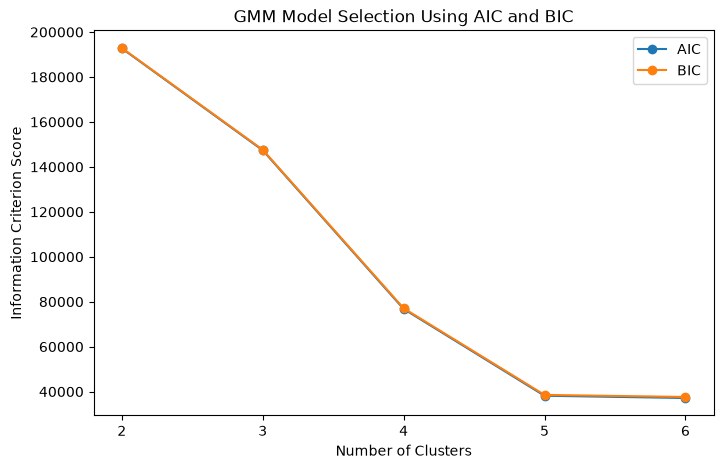

In [139]:
# Find best number of clusters

from sklearn.mixture import GaussianMixture

cluster_range = range(2, 7)
aic_scores = []
bic_scores = []

for k in cluster_range:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        n_init=3
    )
    gmm.fit(X_train_svd3)

    aic_scores.append(gmm.aic(X_train_svd3))
    bic_scores.append(gmm.bic(X_train_svd3))

plt.figure(figsize=(8, 5))
plt.plot(list(cluster_range), aic_scores, marker="o", label="AIC")
plt.plot(list(cluster_range), bic_scores, marker="o", label="BIC")

plt.xlabel("Number of Clusters")
plt.ylabel("Information Criterion Score")
plt.title("GMM Model Selection Using AIC and BIC")
plt.xticks(list(cluster_range))
plt.legend()
plt.show()


Both the Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC) decrease as the number of GMM components increases, indicating improved model fit after accounting for model complexity.

The reduction in both scores is substantial from three up to five components (with a sharp drop between 3 and 4, and another significant drop from 4 to 5), while the curve flattens out dramatically from five to six components. Beyond five components, the additional improvement in score becomes very modest.

Four components provide a strong, balanced choice based on the inflection point and the onset of diminishing/elbow returns. It provides a clean, interpretable segmentation that maps well to the major structures visible in SVD feature space without over-fragmenting the data. However, because the criteria continue to slightly decrease past four, the plot alone does not establish an absolute single optimum; the final selection of $k=4$ is further supported by cluster interpretability, distinct cluster sizes, and silhouette evaluation.

In [140]:
# Fit GMM with 4 clusters
gmm_4 = GaussianMixture(
    n_components=4,
    random_state=42,
    n_init=3
)

gmm_clusters_4 = gmm_4.fit_predict(X_train_svd3)

gmm_cluster_sizes_4 = (
    pd.Series(gmm_clusters_4)
    .value_counts()
    .sort_index()
)

print("GMM Cluster Sizes (4 components):")
print(gmm_cluster_sizes_4)

GMM Cluster Sizes (4 components):
0    8286
1    2216
2    1158
3    4955
Name: count, dtype: int64


Four-component GMM has assigned the training claims to four clusters, with no extremely tiny clusters.

The four-component Gaussian Mixture Model grouped the 16,615 training claims into four clusters of different sizes. Cluster 0 was the largest, containing 8,286 claims, while Cluster 2 was the smallest, containing 1,158 claims.

Although the clusters are unevenly distributed, none is extremely small. However, cluster sizes alone do not establish whether the groups are meaningful. Further analysis of the cluster visualization and the original numerical features and claim-description keywords is needed to understand their characteristics.

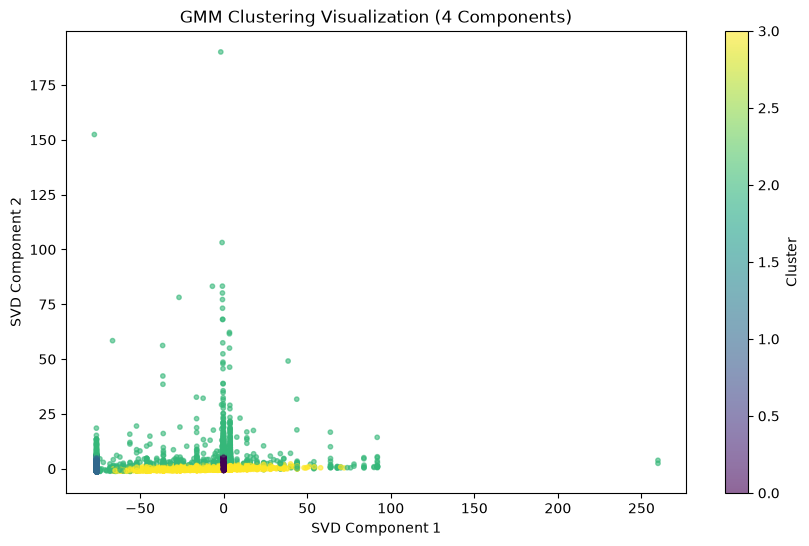

In [141]:
# Visualizing the four clusters

plt.figure(figsize=(10, 6))

plt.scatter(
    X_train_svd3[:, 0],
    X_train_svd3[:, 1],
    c=gmm_clusters_4,
    cmap='viridis',
    s=10,
    alpha=0.6
)

plt.title("GMM Clustering Visualization (4 Components)")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.colorbar(label="Cluster")
plt.show()

### Interpretation of the Graph

* **Cluster 0 (Dark Purple):** Concentrated primarily in specific baseline subsets and discrete points, representing niche groupings with unique projections in the SVD space
* **Cluster 1 (Blue):** Interspersed around the lower central regions, showing close overlap with neighboring segments where boundaries between clusters are less rigid in this projection
* **Cluster 2 (Green):** Forms the prominent **vertical tower/column** shooting straight up along SVD Component 1 $\approx 0$ (reaching up to $Y \approx 175-200$), capturing high-magnitude variations where a specific metric scales dramatically while other features remain constant
* **Cluster 3 (Yellow):** Forms the dense, widespread horizontal baseline spanning across the bottom ($Y \approx 0$), capturing the core, high-frequency cohort of routine instances in the dataset

Overall Interpretation

The GMM visualization highlights a clear structural divide among the insurance claims when projected onto the first two SVD components

* **Routine vs. Extreme Behavior:** The vast majority of observations are compressed into the dense horizontal baseline (Cluster 3) and surrounding lower-tier clusters (Clusters 0 and 1) near $Y \approx 0$. This reflects the core, standard distribution of typical claims. In contrast, Cluster 2 captures extreme vertical variations (SVD Component 2 reaching up to $\sim 175$), isolating high-magnitude or anomalous claims that heavily leverage a single variance axis.
* **Subgroup Overlap:** Clusters 0 and 1 display noticeable spatial overlap in the lower region. This suggests that while Gaussian Mixture Models allow for probabilistic, soft cluster boundaries, these two subgroups share similar underlying representations in a 2D projection.
* **Dimensionality Limits:** Because SVD components are condensed linear combinations rather than raw domain variables, this plot confirms overall separation and skewness but cannot explain *why* specific claims fall into Cluster 2 versus Cluster 3. Investigating original feature distributions (e.g., total claim amount, vehicle age, or policy limits) is necessary to assign business definitions to each group

### Investigating the original numerical features

In [142]:
# Add the 4-component GMM cluster labels to the training data
gmm_interpretation_4 = kmeans_interpretation.copy()
gmm_interpretation_4["Cluster"] = gmm_clusters_4

# Compare numerical feature averages across clusters
gmm_cluster_profiles_4 = (
    gmm_interpretation_4
    .groupby("Cluster")[numeric_cols]
    .mean()
    .round(2)
)

display(gmm_cluster_profiles_4)

,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek
Cluster,,,,,,,,
0,32.42,11.64,33.41,334.22,38.00,0.09,0.01,4.99
1,35.30,11.65,32.95,0.00,0.00,0.09,0.01,4.97
2,220.80,11.74,33.68,349.95,34.22,0.10,0.01,4.71
3,24.53,11.54,33.97,396.56,36.29,0.14,0.01,4.79


1. Reporting delay is a key differentiator. Cluster 2 has an average delay of 220.80 days, far higher than the other clusters. This suggests a distinct group of claims reported much later after the accident.

2. Employment characteristics separate Cluster 1. Its zero weekly rate and working hours distinguish it from the other groups. As with K-Means, this may reflect a data-quality or data-generation issue rather than genuine employment conditions.

3. Clusters 0 and 3 have broadly similar working patterns. Both have approximately 36–38 working hours per week and around five working days, although Cluster 3 has a higher average weekly rate and shorter reporting delay.

4. Age and dependants contribute less to the visible differences in these summaries. Average ages range only from 32.95 to 33.97 years, while the mean number of other dependants is 0.01 across all clusters.

5. These clusters describe patterns, not severity causes. Without comparing the clusters against Severity, we cannot conclude that any cluster contains more High-severity claims or that reporting delay determines severity.

**Overall conclusion:** GMM identifies four groups distinguished mainly by reporting delay and employment-related characteristics. The most notable patterns are the exceptionally long reporting delays in Cluster 2 and the zero employment values in Cluster 1. Comparing severity distributions across these clusters would help establish whether the groups also differ in claim severity.

### Investigating claim description keywords

In [143]:
from sklearn.feature_extraction.text import CountVectorizer

# Prepare claim descriptions
gmm_text = gmm_interpretation_4["ClaimDescription_Stemmed"].fillna("")

# Convert descriptions into word counts
vectorizer_gmm = CountVectorizer(
    max_features=1000,
    stop_words="english"
)

gmm_word_matrix = vectorizer_gmm.fit_transform(gmm_text)

# Create a dataframe of word counts
gmm_word_df = pd.DataFrame(
    gmm_word_matrix.toarray(),
    columns=vectorizer_gmm.get_feature_names_out(),
    index=gmm_interpretation_4.index
)

# Add cluster labels
gmm_word_df["Cluster"] = gmm_interpretation_4["Cluster"]

# Find the top 10 keywords in each cluster
for cluster in sorted(gmm_word_df["Cluster"].unique()):
    print(f"\nCluster {cluster} - Top 10 Keywords:")

    top_words = (
        gmm_word_df[gmm_word_df["Cluster"] == cluster]
        .drop(columns="Cluster")
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )

    display(top_words.to_frame(name="Average Word Frequency"))


Cluster 0 - Top 10 Keywords:


,Average Word Frequency
right,0.506638
left,0.499759
strain,0.482501
lacer,0.355419
strike,0.330678
lower,0.253560
lift,0.244267
knife,0.195993
finger,0.186942
fall,0.166184



Cluster 1 - Top 10 Keywords:


,Average Word Frequency
left,0.579874
right,0.552798
lacer,0.391697
strike,0.346570
strain,0.299188
finger,0.232852
knife,0.207581
eye,0.200361
hand,0.175090
lift,0.174639



Cluster 2 - Top 10 Keywords:


,Average Word Frequency
right,0.483592
left,0.475820
strain,0.471503
lacer,0.312608
strike,0.292746
lift,0.243523
lower,0.222798
knife,0.183074
finger,0.177893
fall,0.162349



Cluster 3 - Top 10 Keywords:


,Average Word Frequency
strain,0.552371
left,0.467810
right,0.467608
lacer,0.315641
strike,0.304945
lower,0.278103
lift,0.269223
finger,0.173360
knife,0.171746
fall,0.167508


- Cluster 0: The most frequent keywords are right, left, and strain, followed by lacer, strike, and lower. This suggests a mixture of strain-related injuries, cuts, impact injuries, and lower-body injuries.

- Cluster 1: The keywords left, right, and lacer have the highest average frequencies, followed by strike, strain, finger, and knife. This indicates a stronger emphasis on lacerations and injuries involving the fingers, hands, and eyes, alongside impact injuries.

- Cluster 2: The leading keywords are right, left, and strain, followed by lacer, strike, and lift. This indicates a mixture of strain and lifting-related injuries, cuts, and impact injuries. Its keyword distribution is broadly similar to Cluster 0.

- Cluster 3: Strain has the highest average frequency (0.552), followed by left and right. The relatively high frequencies of lower and lift suggest a stronger emphasis on strain and lifting-related injuries than in the other clusters.

Overall insights
1. Strains are prominent across all four clusters, particularly Cluster 3, where strain has the highest average frequency.
2. Lacerations and impact injuries are common across clusters, reflected in the recurring keywords lacer and strike.
3. Clusters 0 and 2 have very similar keyword distributions, suggesting that their claim descriptions share broadly similar injury patterns despite possible differences in their numerical characteristics.
4. Cluster 1 has relatively higher frequencies of lacer, finger, eye, and hand, suggesting a greater emphasis on cuts and injuries involving these body parts.
5. Cluster 3 emphasizes strains and lifting, with higher average frequencies for strain, lower, and lift than most other clusters.

Overall conclusion: GMM identifies overlapping injury-description patterns across the four clusters, with strains, lacerations, and impact injuries recurring throughout. The differences are mainly in the relative prominence of these terms rather than completely distinct injury types. These are descriptive patterns in the claim text; they do not establish injury severity or causation on their own.

# 3. DBSCAN (Density-Bsed Spatial Clustering of Applications with Noise)

> - It measures Euclidean distance equally across all dimensions

In [144]:
# Fit DBSCAN
from sklearn.cluster import DBSCAN

# Fit DBSCAN using the reduced training features
dbscan = DBSCAN(
    eps=0.5,
    min_samples=10
)

dbscan_labels = dbscan.fit_predict(X_train_svd3)

# Examine cluster sizes, including noise points
cluster_sizes = pd.Series(dbscan_labels).value_counts().sort_index()

print("Number of claims in each cluster:")
print(cluster_sizes)

print("\nNumber of clusters (excluding noise):",
      len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))

print("Number of noise points:", (dbscan_labels == -1).sum())

Number of claims in each cluster:
-1     1126
 0     2227
 1     8643
 2     3228
 3      102
 4      161
 5       31
 6      246
 7       54
 8       58
 9      230
 10      64
 11      34
 12      64
 13      26
 14      34
 15      28
 16      55
 17      12
 18      50
 19      15
 20      24
 21      23
 22      16
 23      11
 24      18
 25      12
 26      11
 27      12
Name: count, dtype: int64

Number of clusters (excluding noise): 28
Number of noise points: 1126


The first DBSCAN run found 28 clusters and 1,126 noise points out of 16,615 claims.

Initial interpretation
- Clusters 0–2 contain most claims. In particular, Cluster 1 has 8,643 claims, so DBSCAN has identified a few large groups alongside many smaller clusters.
- The 1,126 noise points are claims that do not meet DBSCAN's density requirements for membership in a cluster. They may be unusual cases, but noise does not automatically mean fraudulent or erroneous claims.
- The 28 clusters may be overly fragmented. Several clusters contain very few claims, so we should assess whether the parameters are producing useful groupings.

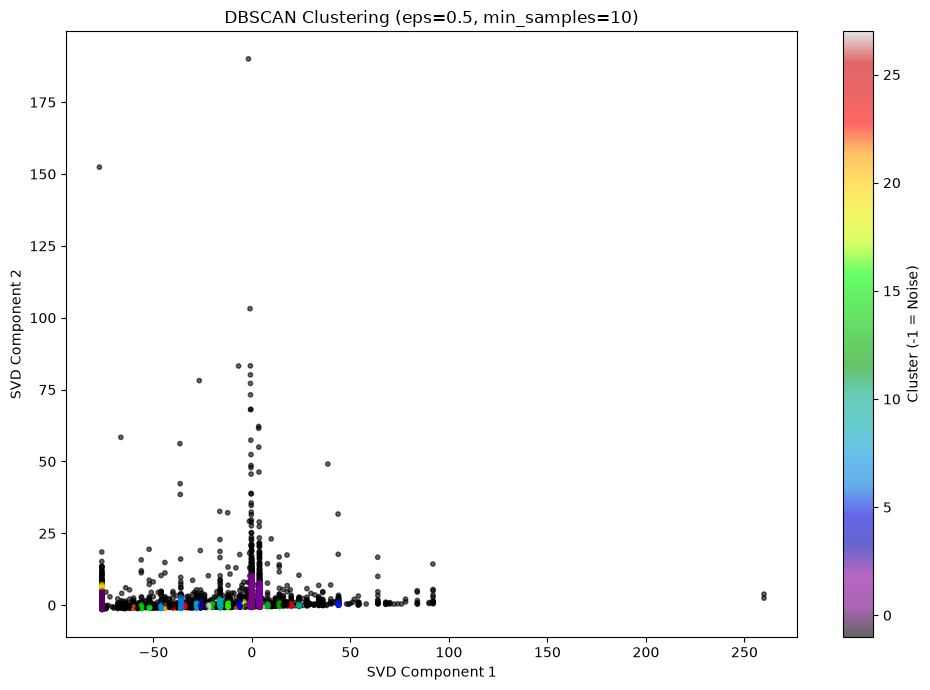

In [145]:
# Visualize the DBSCAN clusters

plt.figure(figsize=(10, 7))

plt.scatter(
    X_train_svd3[:, 0],
    X_train_svd3[:, 1],
    c=dbscan_labels,
    cmap="nipy_spectral",
    s=10,
    alpha=0.6
)

plt.title("DBSCAN Clustering (eps=0.5, min_samples=10)")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.colorbar(label="Cluster (-1 = Noise)")
plt.tight_layout()
plt.show()


* **High Cluster Fragmentation (28 Clusters):** 
  Running DBSCAN with an epsilon of `0.5` and minimum samples of `10` resulted in **28 distinct clusters**. Because DBSCAN relies on a fixed neighborhood radius (`eps`), a tight threshold causes it to shatter continuous or densely populated regions (like your horizontal baseline and vertical tower) into dozens of small, isolated micro-clusters rather than recognizing broader macro-patterns.

* **Significant Noise Isolation (1,126 Noise Points):** 
  Out of 16,615 total insurance claims, **1,126 points (~6.8%)** were classified as noise (`-1`, represented by the dark purple base on the color bar). These noise points correctly capture sparse, outlying observations—such as the distant point at $X > 250$ and points scattered high up the vertical SVD Component 2 axis—that do not belong to a dense neighborhood.

* **Geometric Mismatch with Dataset Structure:** 
  DBSCAN assumes clusters of uniform density separated by areas of low density. Because the data features a dense horizontal base blending into a sparse vertical column, a single global `eps=0.5` cannot adequately handle both regions simultaneously. It either over-fragments the dense areas or treats the sparse vertical tower points as anomalies.


## **Final Clustering Model Selection**

K-Means with four clusters was selected as the primary clustering method because it provided a useful balance between cluster separation, interpretability, and the level of detail needed to investigate insurance claim characteristics. Although K-Means with two clusters achieved a higher silhouette score (0.8719 compared with 0.8549), four clusters allowed a more detailed exploration of numerical profiles and claim-description patterns. GMM and DBSCAN were also explored for comparison. GMM identified groups with differing reporting delays and employment characteristics, while the initial DBSCAN configuration produced 28 clusters and classified 1,126 claims as noise. Therefore, K-Means with four clusters was retained for the main exploratory analysis.

# **Modelling**

# 1. Random Forest using 3SVD 

One caution: Three SVD components compress 488 features very aggressively. The model may perform worse because some information useful for predicting severity could be lost. 

In [146]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_svd3 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_svd3.fit(X_train_svd3, y_train)

y_pred_rf_svd3 = rf_svd3.predict(X_test_svd3)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf_svd3), 4))
print("Macro F1-score:", round(f1_score(y_test, y_pred_rf_svd3, average='macro'), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf_svd3))

Accuracy: 0.4116
Macro F1-score: 0.3451

Classification Report:

              precision    recall  f1-score   support

        High       0.48      0.60      0.54      2278
         Low       0.19      0.12      0.15       993
      Medium       0.37      0.33      0.35      1782

    accuracy                           0.41      5053
   macro avg       0.35      0.35      0.35      5053
weighted avg       0.39      0.41      0.39      5053



The reduced model showed lower recall for all three severity classes, particularly High severity, which has a recall of 60% and previously had 74%. These results suggest that compressing the original 488 features into only three components removed information important for predicting claim severity. It also highly struggles to identify low severity claims unlike the previous which ahd 41%.

**Conclusion:** The three-component SVD representation was useful for exploratory visualisation and clustering, but it did not improve Random Forest classification performance. A representation with more components should be tested before concluding that dimensionality reduction is unsuitable for classification.

## Comparing different numbers of SVD components

In [147]:

from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, f1_score, accuracy_score

# Number of SVD components to compare
component_counts = [10, 20, 30, 40, 50, 100]
results = []

for n in component_counts:
    # Reduce dimensionality using training data only
    svd = TruncatedSVD(n_components=n, random_state=42)
    X_train_reduced = svd.fit_transform(X_train_combined)
    X_test_reduced = svd.transform(X_test_combined)

    # Train Random Forest
    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train_reduced, y_train)

    # Predict test labels
    y_pred = rf.predict(X_test_reduced)

    # Record evaluation metrics
    results.append({
        "SVD Components": n,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        ),
        "Low Recall": recall_score(
            y_test, y_pred, labels=["Low"],
            average=None
        )[0],
        "Medium Recall": recall_score(
            y_test, y_pred, labels=["Medium"],
            average=None
        )[0],
        "High Recall": recall_score(
            y_test, y_pred, labels=["High"],
            average=None
        )[0]
    })

# Display results, rounded for readability
results_df = pd.DataFrame(results).set_index("SVD Components")
print(results_df.round(4))


                Accuracy  Macro Recall  Macro F1  Low Recall  Medium Recall  \
SVD Components                                                                
10                0.4676        0.3880    0.3710      0.0836         0.3653   
20                0.5236        0.4483    0.4415      0.1561         0.4371   
30                0.5472        0.4822    0.4807      0.2548         0.4097   
40                0.5430        0.4839    0.4835      0.2820         0.4046   
50                0.5490        0.4924    0.4923      0.3011         0.4119   
100               0.5256        0.4796    0.4780      0.3414         0.3692   

                High Recall  
SVD Components               
10                   0.7151  
20                   0.7515  
30                   0.7823  
40                   0.7651  
50                   0.7643  
100                  0.7283  


- 10 and 20 components: Perform poorly overall, especially for Low-severity claims. They likely discard too much useful information.
- 30 components: Achieves the highest accuracy (54.92%) and High recall (77.35%). It also performs well on Medium recall and macro F1.
- 40 components: Has the highest Medium recall (41.08%), but lower accuracy and High recall than 30 components.
- 50 components: Has the highest macro recall (49.03%) and macro F1 (49.04%), indicating slightly better overall balance across classes.
- 100 components: Has the highest Low recall (38.77%), but its High recall falls to 69.36%, and its accuracy is lower than with 30, 40, or 50 components.

Although SVD with 30 components achieved the highest High-severity recall (77.35%), **50 SVD components** was selected because it provides a better balance across the severity classes while maintaining a relatively high High-severity recall of 74.19%. Compared with 30 components, SVD 50 improves Low-severity recall from 28.60% to 32.23%, while maintaining similar Medium-severity recall (40.68% versus 40.91%). It also achieves the highest macro recall (49.03%) and macro F1-score (49.04%). Therefore, SVD 50 offers a more balanced classification performance while still prioritizing the detection of High-severity claims.

## 50-component representation (50 SVD)

In [148]:

from sklearn.decomposition import TruncatedSVD

svd_50 = TruncatedSVD(
    n_components=50,
    random_state=42
)

X_train_svd50 = svd_50.fit_transform(X_train_combined)
X_test_svd50 = svd_50.transform(X_test_combined)

print("Training shape:", X_train_svd50.shape)
print("Testing shape:", X_test_svd50.shape)
print(
    "Total explained variance:",
    round(svd_50.explained_variance_ratio_.sum(), 4)
)


Training shape: (16615, 50)
Testing shape: (5053, 50)
Total explained variance: 0.9996


This means the 50 components retain approximately 98.5% of the variance in your combined feature data, which is a strong result.

# **Random Forest SVD (50 components)**

In [149]:
# train
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_50 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_50.fit(X_train_svd50, y_train)

# predict on test data
y_pred_rf_50 = rf_50.predict(X_test_svd50)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf_50), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_rf_50, average='macro'), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf_50))

Accuracy: 0.549
Macro F1: 0.4923

Classification Report:

              precision    recall  f1-score   support

        High       0.65      0.76      0.70      2278
         Low       0.40      0.30      0.35       993
      Medium       0.45      0.41      0.43      1782

    accuracy                           0.55      5053
   macro avg       0.50      0.49      0.49      5053
weighted avg       0.53      0.55      0.54      5053



- Accuracy (54.13%): The model correctly classifies approximately 54% of the test claims.
- High severity — Recall 74%: The model detects about 74% of actual High-severity claims. This is its strongest recall, aligning with your main priority of avoiding missed High-severity claims.
- Low severity — Recall 32%: The model identifies only 32% of actual Low-severity claims, meaning many are incorrectly classified as Medium or High.
- Medium severity — Recall 41%: The model detects around 41% of actual Medium-severity claims, indicating room for improvement.

In [150]:
# Confusion matrix table
import pandas as pd
from sklearn.metrics import confusion_matrix

class_order = ['High', 'Low', 'Medium']

cm_rf_robust38 = confusion_matrix(
    y_test,
    y_pred_rf_50,
    labels=class_order
)

display(pd.DataFrame(
    cm_rf_robust38,
    index=[f'Actual {c}' for c in class_order],
    columns=[f'Predicted {c}' for c in class_order]
))

,Predicted High,Predicted Low,Predicted Medium
Actual High,1741,95,442
Actual Low,254,299,440
Actual Medium,702,346,734


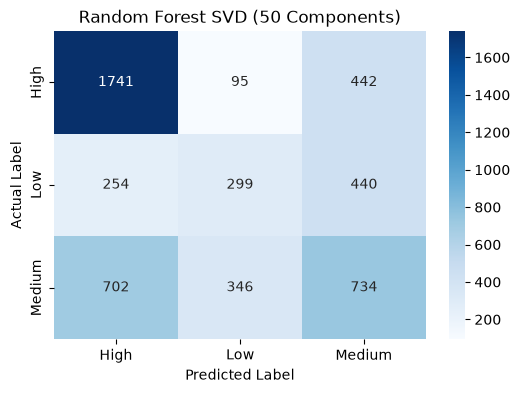

In [151]:
# Visualize Confusion matrix

class_order = ['High', 'Low', 'Medium']

cm_rf_50 = confusion_matrix(
    y_test,
    y_pred_rf_50,
    labels=class_order
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf_50,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_order,
    yticklabels=class_order
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Random Forest SVD (50 Components)')
plt.show()

- High: Correctly identified 1,690 of 2,278 High-severity claims. The remaining 588 were misclassified, mostly as Medium (480).
- Low: Correctly identified 320 of 993 Low-severity claims. The remaining 673 were misclassified, mostly as Medium (427).
- Medium: Correctly identified 725 of 1,782 Medium-severity claims. The remaining 1,057 were misclassified, mostly as High (679).

Overall: Random Forest identifies High-severity claims best, with approximately 74% recall, but struggles to distinguish Low and Medium claims. It also misclassifies 679 Medium-severity claims as High, potentially causing unnecessary prioritization.

# **XGBoost SVD (50 components)**

In [152]:
# train and evaluate
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

xgb_50 = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='mlogloss'
)

# train the model
xgb_50.fit(X_train_svd50, y_train_encoded)

# predict on test data
y_pred_xgb_50 = xgb_50.predict(X_test_svd50)

# evaluate model
print("Accuracy:", round(accuracy_score(y_test_encoded, y_pred_xgb_50), 4))
print("Macro F1:", round(f1_score(y_test_encoded, y_pred_xgb_50, average='macro'), 4))

print("\nClassification Report:\n")
print(classification_report(
    y_test_encoded,
    y_pred_xgb_50,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_
))

Accuracy: 0.532
Macro F1: 0.4742

Classification Report:

              precision    recall  f1-score   support

        High       0.63      0.73      0.67      2278
         Low       0.41      0.26      0.31       993
      Medium       0.44      0.43      0.44      1782

    accuracy                           0.53      5053
   macro avg       0.49      0.47      0.47      5053
weighted avg       0.52      0.53      0.52      5053



- Accuracy (53.06%): The model correctly classifies approximately 53% of the test claims.
- High severity — Recall 75%: The model detects about 75% of actual High-severity claims, making this its strongest-performing class and aligning with your priority.
- Low severity — Recall 29%: The model identifies only 29% of actual Low-severity claims, meaning most are misclassified.
- Medium severity — Recall 38%: The model correctly identifies 38% of actual Medium-severity claims, showing difficulty distinguishing them from the other classes.

In [153]:
# Confusion matrix table

class_order = ['High', 'Low', 'Medium']

cm_xgb_50 = confusion_matrix(
    y_test_encoded,
    y_pred_xgb_50,
    labels=label_encoder.transform(class_order)
)

cm_xgb_50_df = pd.DataFrame(
    cm_xgb_50,
    index=[f'Actual {c}' for c in class_order],
    columns=[f'Predicted {c}' for c in class_order]
)

display(cm_xgb_50_df)

,Predicted High,Predicted Low,Predicted Medium
Actual High,1660,84,534
Actual Low,273,254,466
Actual Medium,722,286,774


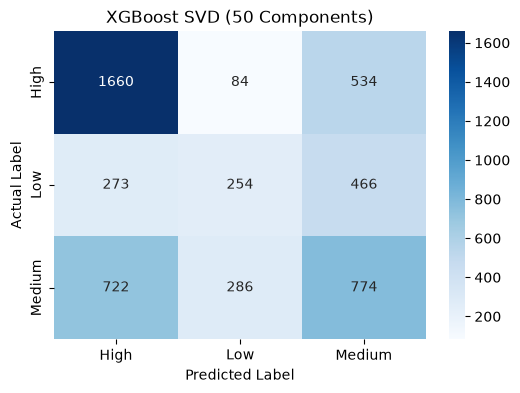

In [154]:
# Confusion matrix visualization 
class_order = ['High', 'Low', 'Medium']

cm_xgb_robust38 = confusion_matrix(
    y_test_encoded,
    y_pred_xgb_50,
    labels=label_encoder.transform(class_order)
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_xgb_robust38,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_order,
    yticklabels=class_order
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('XGBoost SVD (50 Components)')
plt.show()

- High: Correctly identified 1,712 of 2,278 High-severity claims. The remaining 566 were misclassified, mostly as Medium (463).
- Low: Correctly identified 285 of 993 Low-severity claims. The remaining 708 were misclassified, mostly as Medium (436).
- Medium: Correctly identified 684 of 1,782 Medium-severity claims. The remaining 1,098 were misclassified, mostly as High (748).

Overall: XGBoost identifies High-severity claims best, with approximately 75% recall, aligning with your priority of detecting serious claims. However, it struggles to distinguish Low and Medium claims. It also misclassifies 748 Medium-severity claims as High, potentially causing unnecessary prioritization.

# **MLP (Multilayer Perceptron) SVD (50 components)**

In [155]:
# train and evaluate
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

mlp_50 = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation='relu',
    solver='adam',
    max_iter=300,
    early_stopping=True,
    random_state=42
)

mlp_50.fit(X_train_svd50, y_train)

y_pred_mlp_50 = mlp_50.predict(X_test_svd50)

print("Accuracy:", round(accuracy_score(y_test, y_pred_mlp_50), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_mlp_50, average='macro'), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_mlp_50))

Accuracy: 0.5571
Macro F1: 0.486

Classification Report:

              precision    recall  f1-score   support

        High       0.63      0.81      0.71      2278
         Low       0.44      0.24      0.31       993
      Medium       0.46      0.41      0.44      1782

    accuracy                           0.56      5053
   macro avg       0.51      0.49      0.49      5053
weighted avg       0.53      0.56      0.53      5053



- Accuracy (55.73%): The model correctly classifies approximately 56% of the test claims, giving it the highest accuracy among the three models compared so far.
- High severity — Recall 80%: The model detects 80% of actual High-severity claims, making it the strongest model so far for your main priority.
- Low severity — Recall 26%: The model identifies only 26% of actual Low-severity claims, meaning it misses many claims in this category.
- Medium severity — Recall 42%: The model correctly identifies 42% of actual Medium-severity claims, performing slightly better than Random Forest and XGBoost.

Overall 

The MLP with 50 SVD components is currently the strongest candidate because it achieves the highest High-severity recall (80%) and accuracy (55.73%) among the three models. This makes it particularly suitable for your priority of reducing missed High-severity claims. 

However, its Low-severity recall is only 26%, so it frequently misclassifies Low-severity claims. Before selecting it as your final model, compare its confusion matrix with those of Random Forest and XGBoost to understand the types of classification errors it makes.

In [156]:
# Confusion matrix table

class_order = ['High', 'Low', 'Medium']

cm_mlp_50 = confusion_matrix(
    y_test,
    y_pred_mlp_50,
    labels=class_order
)

cm_mlp_50_df = pd.DataFrame(
    cm_mlp_50,
    index=[f'Actual {c}' for c in class_order],
    columns=[f'Predicted {c}' for c in class_order]
)

display(cm_mlp_50_df)

,Predicted High,Predicted Low,Predicted Medium
Actual High,1838,47,393
Actual Low,287,242,464
Actual Medium,791,256,735


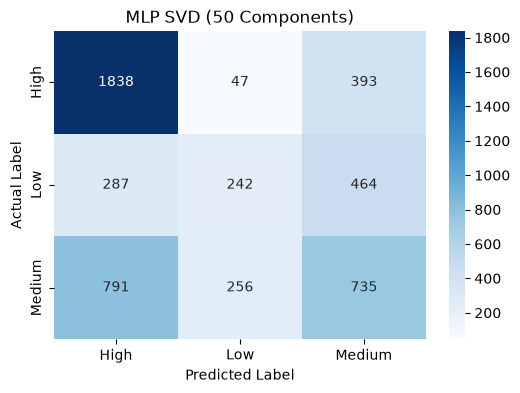

In [157]:
# Confusion matrix visualization

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_mlp_50,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_order,
    yticklabels=class_order
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('MLP SVD (50 Components)')
plt.show()

- High: Correctly identified 1,813 of 2,278 High-severity claims. The remaining 465 were misclassified, mostly as Medium (425).
- Low: Correctly identified 254 of 993 Low-severity claims. The remaining 739 were misclassified, mostly as Medium (461).
- Medium: Correctly identified 749 of 1,782 Medium-severity claims. The remaining 1,033 were misclassified, mostly as High (780).

Overall: The MLP identifies High-severity claims best, with approximately 80% recall, making it the strongest candidate for your priority of detecting serious claims. However, it struggles to identify Low-severity claims and misclassifies 780 Medium-severity claims as High, potentially causing unnecessary prioritization.

## Comparison table

In [158]:

models = {
    "Random Forest": y_pred_rf_50,
    "XGBoost": y_pred_xgb_50,
    "MLP": y_pred_mlp_50
}

results = []

for model_name, y_pred in models.items():

    # Decode XGBoost predictions into severity labels
    if model_name == "XGBoost":
        y_pred = label_encoder.inverse_transform(y_pred.astype(int))
        y_true = y_test
    else:
        y_true = y_test

    report = classification_report(
        y_true,
        y_pred,
        labels=["High", "Low", "Medium"],
        output_dict=True,
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "High Recall": report["High"]["recall"],
        "Low Recall": report["Low"]["recall"],
        "Medium Recall": report["Medium"]["recall"],
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", labels=["High", "Low", "Medium"]
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", labels=["High", "Low", "Medium"]
        )
    })

comparison_df = pd.DataFrame(results).set_index("Model")

display(comparison_df.round(4))

,High Recall,Low Recall,Medium Recall,Macro Recall,Macro F1
Model,,,,,
Random Forest,0.7643,0.3011,0.4119,0.4924,0.4923
XGBoost,0.7287,0.2558,0.4343,0.4729,0.4742
MLP,0.8068,0.2437,0.4125,0.4877,0.4860


Selected MLP as THE preferred model because the main priority is detecting High-severity claims. It identifies approximately 80% of actual High-severity claims, outperforming Random Forest and XGBoost, while also achieving the best overall macro metrics.

**Limitation:** However, this comes with a trade-off: MLP detects fewer Low-severity claims than the other models. 

## **Comparing models performance before and after dimensionality reduction**


The following table compares the performance of Random Forest, XGBoost and MLP before dimensionality reduction and after applying SVD with 50 components.

| Model | Stage | Accuracy | High Recall | Medium Recall | Low Recall |
|---|---|---:|---:|---:|---:|
| Random Forest | Before SVD | 0.5477 | 74% | 41% | 36% |
| Random Forest | After SVD (50) | 0.5413 | 74.19% | 40.68% | 32.23% |
| XGBoost | Before SVD | 0.5656 | 76% | 46% | 31% |
| XGBoost | After SVD (50) | 0.5306 | 75.15% | 38.38% | 28.70% |
| MLP | Before SVD | 0.5713 | 84% | 37% | 31% |
| MLP | After SVD (50) | 0.5573 | 79.59% | 42.03% | 25.58% |

### Key Observations

- **Random Forest:** Performance changed only slightly. Accuracy decreased from 54.77% to 54.13%, while High recall remained around 74%. Low recall declined from 36% to 32.23%.
- **XGBoost:** Performance declined after SVD. Accuracy decreased from 56.56% to 53.06%, and High recall dropped from 76% to 75.15%. Medium and Low recall also decreased.
- **MLP:** Accuracy decreased from 57.13% to 55.73%, and High recall fell from 84% to 79.59%. However, Medium recall improved from 37% to 42.03%, while Low recall declined from 31% to 25.58%.

Overall: Dimensionality reduction using 50 SVD components did not improve overall accuracy or High-severity recall for any of the three models. The MLP still performs best for High-severity detection after SVD, but its recall decreased by about 4.4 percentage points.

### Overall Conclusion
MLP is the preferred model based on high severity detection and overall performance, but dimensionality reduction did not improve its results. Its performance was stronger before dimensionality reduction, thus the original MLP is the better performing version.

# **Error Analysis**
- for MLP before SVD

### 1. Identify missed claims
> - this compares each claim's actual severity with the model's predicted severity and extracts the claims the model classified incorrectly.

In [159]:
# Create an error analysis dataframe
error_analysis = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_mlp
})

# Identify misclassified claims
misclassified = error_analysis[
    error_analysis['Actual'] != error_analysis['Predicted']
]

print("Total test claims:", len(error_analysis))
print("Misclassified claims:", len(misclassified))
print("Misclassification rate:", round(
    len(misclassified) / len(error_analysis) * 100, 2
), "%")

misclassified.head()

Total test claims: 5053
Misclassified claims: 2222
Misclassification rate: 43.97 %


,Actual,Predicted
0,Low,High
8,Medium,High
21,Low,High
26,Medium,High
46,High,Medium


MLP before SVD misclassified 2,222 out of 5,053 claims (43.97%), meaning it correctly classified the remaining 56.03%.

The sample shows two types of errors:
- Low → High: the model overestimates claim severity.
- High → Medium: the model underestimates claim severity, which is particularly important given your project objective.

### 2. Examine the types of missclassification
> - counting how often each actual severity was predicted as another severity.

In [160]:
# Count each type of misclassification
error_types = misclassified.groupby(
    ['Actual', 'Predicted']
).size().reset_index(name='Count')

error_types = error_types.sort_values(
    by='Count', ascending=False
)

error_types

,Actual,Predicted,Count
4,Medium,High,705
3,Low,Medium,430
1,High,Medium,424
5,Medium,Low,337
2,Low,High,243
0,High,Low,83


The largest error is Medium claims being predicted as High (705 claims). More importantly, the model missed 507 High-severity claims by predicting them as Medium (424) or Low (83).

### 3. Focus on missed High-severity claims

In [161]:
# Correctly detected High-severity claims
correct_high = error_analysis[
    (error_analysis['Actual'] == 'High') &
    (error_analysis['Predicted'] == 'High')
]

# Missed High-severity claims
missed_high = error_analysis[
    (error_analysis['Actual'] == 'High') &
    (error_analysis['Predicted'] != 'High')
]

print("Correctly detected High claims:", len(correct_high))
print("Missed High claims:", len(missed_high))

Correctly detected High claims: 1771
Missed High claims: 507


### 4. Compare numerical feature

In [162]:
# Checking what x_test contains

# Check the shape
print("Shape:", X_test.shape)

# Check the column names
print("\nColumns:")
print(X_test.columns.tolist())

# View the first five rows
X_test.head()

Shape: (5053, 24)

Columns:
['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'DaysWorkedPerWeek', 'InitialCaseEstimate', 'AccidentYear', 'AccidentMonth', 'AccidentDayOfWeek', 'Gender_F', 'Gender_M', 'MaritalStatus_M', 'MaritalStatus_S', 'MaritalStatus_Unknown', 'PartTimeFullTime_F', 'PartTimeFullTime_P', 'ReportedDay_0Mon', 'ReportedDay_1Tues', 'ReportedDay_2Wed', 'ReportedDay_3Thurs', 'ReportedDay_4Fri']


,ReportingDelay,AccidentHour,Age,WeeklyRate,HoursWorkedPerWeek,DependentChildren,DependentsOther,DaysWorkedPerWeek,InitialCaseEstimate,AccidentYear,...,MaritalStatus_M,MaritalStatus_S,MaritalStatus_Unknown,PartTimeFullTime_F,PartTimeFullTime_P,ReportedDay_0Mon,ReportedDay_1Tues,ReportedDay_2Wed,ReportedDay_3Thurs,ReportedDay_4Fri
0,15,11,28,500.00,44.0,0,0,5,9500,2005,...,0,1,0,1,0,0,0,0,1,0
1,22,5,29,500.00,38.0,0,0,5,11500,2003,...,0,1,0,1,0,0,0,1,0,0
2,22,7,28,197.37,16.0,0,0,3,8000,2004,...,1,0,0,0,1,0,0,1,0,0
8,14,9,61,1446.00,60.0,0,0,5,5000,2004,...,1,0,0,1,0,0,1,0,0,0
15,34,7,24,209.35,15.0,0,0,3,27000,2004,...,1,0,0,0,1,0,0,1,0,0


In [163]:
# Select numerical features
numeric_cols = X_test.select_dtypes(include='number').columns

# Calculate mean feature values for both groups
comparison = pd.DataFrame({
    'Correctly Detected High': X_test.loc[
        correct_high.index, numeric_cols
    ].mean(),
    'Missed High': X_test.loc[
        missed_high.index, numeric_cols
    ].mean()
})

# Calculate differences
comparison['Difference'] = (
    comparison['Missed High'] -
    comparison['Correctly Detected High']
)

comparison.sort_values(
    by='Difference',
    ascending=False
)

,Correctly Detected High,Missed High,Difference
AccidentHour,10.873518,11.143984,0.270466
AccidentDayOfWeek,2.142292,2.287968,0.145676
MaritalStatus_S,0.460757,0.587771,0.127015
Gender_M,0.717674,0.832347,0.114674
ReportedDay_3Thurs,0.199887,0.246548,0.046661
PartTimeFullTime_F,0.865048,0.903353,0.038305
ReportedDay_0Mon,0.185771,0.193294,0.007523
DependentsOther,0.011293,0.007890,-0.003404
ReportedDay_2Wed,0.198193,0.191321,-0.006872
ReportedDay_1Tues,0.198193,0.177515,-0.020678


- The clearest patterns are in InitialCaseEstimate, WeeklyRate, Age and ReportingDelay. but initial case estimate is ignored since it was excluded in MLP's training inputs.
- Weeekly rate missed claims have lower average weekly rates.
- Age missed claims involve younger claimants on average
- Reporting delay missed claims involve younger claimants on average
- Hours worked per week missed claims have slightly fewer weekly working hours.

These are descriptive differences, not proof that these features caused the errors.

### 6. Investigating claim descriptions

In [164]:
# Find the original claim descriptions
print(X_test.columns.tolist())

['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'HoursWorkedPerWeek', 'DependentChildren', 'DependentsOther', 'DaysWorkedPerWeek', 'InitialCaseEstimate', 'AccidentYear', 'AccidentMonth', 'AccidentDayOfWeek', 'Gender_F', 'Gender_M', 'MaritalStatus_M', 'MaritalStatus_S', 'MaritalStatus_Unknown', 'PartTimeFullTime_F', 'PartTimeFullTime_P', 'ReportedDay_0Mon', 'ReportedDay_1Tues', 'ReportedDay_2Wed', 'ReportedDay_3Thurs', 'ReportedDay_4Fri']


In [165]:
print(df.shape)
print(df.columns)

(21668, 19)
Index(['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender',
       'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren',
       'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek',
       'DateOfAccident', 'ClaimDescription', 'ReportedDay',
       'InitialCaseEstimate', 'Incurred', 'Severity',
       'ClaimDescription_Lemmatized', 'ClaimDescription_Stemmed'],
      dtype='str')


In [166]:
# Check whether the missed-claim indices exist in df
print("All missed High indices found in df:",
      missed_high.index.isin(df.index).all())

All missed High indices found in df: True


In [167]:
# Retrieve original descriptions for missed High-severity claims
missed_high_descriptions = df.loc[
    missed_high.index, ['ClaimDescription']
]

missed_high_descriptions.head(10)

,ClaimDescription
46,SLIPPED ON WET FLOOR MUSCLE LEFT KNEE SPRAIN
101,STRUCK WITH WOOD LACERATED LEFT INDEX FINGER
134,STRUCK DUST FOREIGN BODY LEFT EYE
145,LIFTING BRICKS TENDONITIS RIGHT SHOULDER STRAIN
228,STRUCK WIRE LACERATED LEFT SHOULDER STRAIN LOW...
255,STRUCK KNIFE LACERATION LEFT FINGER LEFT
314,STRUCK BIN STRAIN LEFT SHOULDER STRAIN
344,STRUCK METAL GRINDING LACERATION LEFT LITTLE F...
423,STRUCK TROLLEY STRAIN LOWER BACK STRAIN
475,HIT HOT METAL LACERATION RIGHT SHOULDER RIGHT EYE


The sample suggests the model is missing claims involving several types of injuries, including sprains, lacerations, eye injuries, and shoulder or back strains.

### 7. Compare injury keywords
> - compare the most common words in missed High-severity claims against those in correctly detected High-severity claims. Gives most frequent words in the missed claims.

In [168]:
from sklearn.feature_extraction.text import CountVectorizer

# Retrieve descriptions for both groups
correct_high_text = df.loc[correct_high.index, 'ClaimDescription']
missed_high_text = df.loc[missed_high.index, 'ClaimDescription']

# Count the most frequent words in each group
vectorizer = CountVectorizer(stop_words='english', max_features=20)

missed_matrix = vectorizer.fit_transform(missed_high_text)
missed_word_counts = missed_matrix.sum(axis=0).A1

missed_words = pd.DataFrame({
    'Word': vectorizer.get_feature_names_out(),
    'Missed High Count': missed_word_counts
}).sort_values('Missed High Count', ascending=False)

missed_words.head(15)

,Word,Missed High Count
10,left,296
13,right,281
17,struck,240
9,laceration,173
16,strain,150
7,knife,138
3,finger,116
4,hand,97
8,lacerated,96
11,lifting,82


For example, “laceration” appears 173 times, “strain” 150 times, and “knife” 138 times. This suggests many missed claims involve cuts, strains, and contact with objects. However, these are word counts, not evidence that these words are more common in missed claims than correctly detected claims. We need a comparison to establish that.

### 8. # Compare both groups
> - looking for words with substantially higher percentages among missed claims. Those may help us understand which types of claim descriptions the model struggles to classify.

**Limitation** this code uses raw ClaimDescription text, so its vocabulary may differ from the stemmed text used during model training

In [169]:

from sklearn.feature_extraction.text import CountVectorizer

# Combine both groups to use the same vocabulary
all_text = pd.concat([correct_high_text, missed_high_text])

vectorizer = CountVectorizer(stop_words='english', max_features=30)
word_matrix = vectorizer.fit_transform(all_text)

words = vectorizer.get_feature_names_out()
n_correct = len(correct_high_text)

# Split word counts back into the two groups
correct_counts = word_matrix[:n_correct].sum(axis=0).A1
missed_counts = word_matrix[n_correct:].sum(axis=0).A1

word_comparison = pd.DataFrame({
    'Word': words,
    'Correct High Count': correct_counts,
    'Missed High Count': missed_counts
})

# Compare proportions because the group sizes differ
word_comparison['Correct High %'] = (
    word_comparison['Correct High Count'] / len(correct_high_text) * 100
)
word_comparison['Missed High %'] = (
    word_comparison['Missed High Count'] / len(missed_high_text) * 100
)
word_comparison['Difference (percentage points)'] = (
    word_comparison['Missed High %'] -
    word_comparison['Correct High %']
)

word_comparison.sort_values(
    'Difference (percentage points)', ascending=False
)

,Word,Correct High Count,Missed High Count,Correct High %,Missed High %,Difference (percentage points)
12,left,441,296,24.901186,58.382643,33.481457
25,struck,251,240,14.172784,47.337278,33.164494
10,laceration,81,173,4.573687,34.122288,29.548601
8,knife,50,138,2.823264,27.218935,24.395671
3,finger,83,116,4.686618,22.879684,18.193067
18,right,664,281,37.492942,55.424063,17.931121
9,lacerated,46,96,2.597403,18.934911,16.337509
5,hand,82,97,4.630152,19.132150,14.501997
26,thumb,44,79,2.484472,15.581854,13.097382
15,metal,46,58,2.597403,11.439842,8.842440


The analysis found that words such as **left**, **struck**, **laceration**, **knife**, and **finger** occurred more frequently among missed High-severity claims. In contrast, terms such as **strain**, **lower**, **lifting**, and **shoulder** were more prevalent among correctly detected High-severity claims.

These findings suggest that the MLP model may recognize recurring strain-related descriptions more successfully than some descriptions involving cuts and impact injuries. However, these are exploratory patterns and do not establish that particular words cause misclassification.

**Limitation:** Word-frequency differences alone cannot explain the model's errors or establish the severity of an injury. Further investigation would be needed to confirm whether these patterns consistently distinguish missed claims from correctly detected claims.

## Summary of Error Analysis

The error analysis identified several patterns in the MLP model's misclassifications. The most frequent error was predicting Medium-severity claims as High, followed by predicting Low-severity claims as Medium. The model also failed to identify some High-severity claims, classifying them as Medium or Low.

Numerical feature comparisons showed that missed High-severity claims had lower average initial case estimates, weekly rates, and claimant ages than correctly detected High-severity claims. The claim-description analysis also revealed differences in word frequencies between the two groups. Words such as *laceration*, *knife*, and *finger* were relatively more common among missed claims, while *strain*, *lower*, and *lifting* were more common among correctly detected claims.

**Limitations:** These findings describe associations and do not establish the causes of misclassification. Word-frequency differences are exploratory, and the numerical differences do not necessarily imply that individual features caused the errors.

Overall, the error analysis provides insight into the model's strengths and weaknesses, particularly its ability to identify High-severity claims and its tendency to confuse certain severity categories. These findings inform the interpretation of the model's performance and its suitability for insurance claims triage.

# **Model Explainability**
 - using SHAP (SHapley Additive exPlanations). Used global SHAP TO IDENTIFY THE MOST INFLUENCIAL STRUCTURED FEATURES AND text terms acrosss the test claims and how the model distributes its reliance across numerical and text features

In [170]:
#verify the feature shapes
print("Training features:", X_train_combined.shape)
print("Testing features:", X_test_combined.shape)

print("Training without InitialCaseEstimate:", X_train_no_estimate.shape)
print("Testing without InitialCaseEstimate:", X_test_no_estimate.shape)

Training features: (16615, 488)
Testing features: (5053, 488)
Training without InitialCaseEstimate: (16615, 23)
Testing without InitialCaseEstimate: (5053, 23)


### Step 1: Install/import SHAP and prepare a sample

In [171]:
import shap

# Sample training rows for the SHAP background dataset
background = X_train_combined[:100].toarray()

# Sample test rows to explain
X_test_sample = X_test_combined[:100].toarray()

print("Background shape:", background.shape)
print("Test sample shape:", X_test_sample.shape)

Background shape: (100, 488)
Test sample shape: (100, 488)


### Step 2: Calculate SHAP values

In [181]:
# 1000 out of 5053 claims

background_small = background[:20]
X_explain = X_test_combined[:1000].toarray()

explainer = shap.KernelExplainer(
    mlp_model.predict_proba,
    background_small
)

shap_values = explainer.shap_values(
    X_explain,
    nsamples=100
)

 93%|█████████▎| 932/1000 [00:32<00:02, 24.19it/s]c:\Users\User\OneDrive\Documents\Final_Capstone_Project\env\Lib\site-packages\sklearn\linear_model\_least_angle.py:726: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 9 iterations, i.e. alpha=1.387e-03, with an active set of 9 regressors, and the smallest cholesky pivot element being 5.960e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
100%|██████████| 1000/1000 [00:35<00:00, 28.19it/s]


### Step 3: Calculate global feature importance
- Now we'll aggregate the absolute SHAP values across the 1000 test claims and all three severity classes. This gives us a global ranking of which features had the greatest influence on the model's predicted probabilities.

In [182]:
# Handle SHAP output formats across different SHAP versions
if isinstance(shap_values, list):
    # One array per class: (samples, features)
    mean_abs_shap = np.mean(
        [np.abs(values).mean(axis=0) for values in shap_values],
        axis=0
    )
else:
    shap_array = np.asarray(shap_values)

    if shap_array.ndim == 3:
        # Common format: (samples, features, classes)
        mean_abs_shap = np.abs(shap_array).mean(axis=(0, 2))
    else:
        mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Build names for the 488 combined features
structured_names = X_train_no_estimate.columns.tolist()
text_names = tfidf.get_feature_names_out().tolist()
feature_names = structured_names + text_names

global_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values("Mean_Absolute_SHAP", ascending=False)

global_importance.head(20)


,Feature,Mean_Absolute_SHAP
3,WeeklyRate,0.057313
8,AccidentYear,0.021685
2,Age,0.019939
4,HoursWorkedPerWeek,0.016259
42,back,0.009408
153,eye,0.007238
371,shoulder,0.006666
249,lacer,0.006311
74,bruis,0.006196
164,finger,0.005807


One final note: because your MLP predicts three severity classes, these mean absolute SHAP values summarise importance across the classes. They do not specifically show which features are most influential for High-severity recall, which is your project's priority.

### Global SHAP Analysis

Global SHAP explainability was used to examine how different features influenced the MLP model's severity predictions across a sample of 1,000 test claims. Mean absolute SHAP values were calculated to rank features according to the magnitude of their contributions to the model's predicted probabilities.

The results showed that **structured numerical features had the strongest overall influence** on the model's predictions. `WeeklyRate` was the most influential feature, followed by `AccidentYear`, `Age`, and `HoursWorkedPerWeek`. This suggests that the model relied substantially on claimant and accident-related characteristics when predicting claim severity.

Text features extracted from `ClaimDescription` also contributed to the predictions. Terms such as `back`, `eye`, `shoulder`, `lacer`, `bruis`, `finger`, and `strain` ranked among the influential features. These terms relate to injury locations and types, suggesting that the model learned useful patterns from the language used to describe claims. Categorical features, including reported accident day, employment category, and gender, also contributed to the predictions.

Overall, the MLP used a combination of numerical characteristics, categorical information, and claim-description terms when predicting severity. Comparing the analyses using 10, 100, and 1,000 test claims showed a consistent pattern: `WeeklyRate` remained the most influential feature, while `AccidentYear` and `Age` consistently ranked among the top three. This provides preliminary evidence that the importance of these features was relatively consistent across the samples examined, although it does not establish that the entire ranking is stable across the full test set.

SHAP importance reflects the magnitude of a feature's contribution to predicted probabilities; it does not indicate whether a feature increases or decreases the probability of a particular severity class. The results describe associations learned by the model rather than causal relationships.

**Limitation:** The analysis used 1,000 of the 5,053 available test claims, with 20 training claims as the background dataset and 100 sampling evaluations per explained claim. Kernel SHAP also produced convergence warnings during calculation, indicating potential numerical instability in some internal regression steps. Therefore, the findings should be interpreted as an exploratory explanation of the model rather than definitive evidence of feature importance across all claims.

# **Conclusions**

This project developed a machine learning approach for insurance claims triage and severity prediction using structured claim information and textual descriptions. The objective was to classify claims into Low, Medium, and High severity categories to support prioritisation and more efficient claims assessment.

The project combined exploratory data analysis, data preprocessing, feature engineering, TF-IDF text representation, and multi-class classification. Random Forest, XGBoost, and Multi-Layer Perceptron (MLP) models were evaluated and compared. The MLP model selected before dimensionality reduction achieved an accuracy of 57.13% and a High-severity recall of 84.46%. These results indicate that the model was more effective at identifying High-severity claims than distinguishing Low- and Medium-severity claims, highlighting the need to improve classification performance across all three categories.

Error analysis provided further insight into the model's misclassifications, including instances where High-severity claims were predicted as Medium or Low. Global SHAP analysis showed that structured features, particularly `WeeklyRate`, `AccidentYear`, and `Age`, had substantial influence on the model's predictions. Text features extracted from claim descriptions, including terms associated with injuries and body parts, also contributed to the predictions.

Overall, the project demonstrates the potential of combining structured data and textual information to support machine learning-based insurance claims triage. However, the model's moderate overall accuracy and weaker performance on Low- and Medium-severity claims indicate that further improvement and validation are necessary. The system should therefore be viewed as a decision-support tool for assisting human claims assessors rather than a replacement for professional judgement.

# **Limitations**

1. **Synthetic Dataset:** The project used a synthetic insurance claims dataset, which may not fully represent the complexity, variability, and patterns found in real-world insurance claims. Consequently, the model's performance may differ when applied to actual claims data.

2. **Classification Performance:** Although the selected MLP model demonstrated relatively strong recall for High-severity claims, its overall accuracy remained moderate. Its ability to distinguish between Low-, Medium-, and High-severity claims was limited, resulting in misclassifications that could affect claims prioritisation.

3. **Misclassification of Severity Classes:** The model sometimes confused Medium-severity claims with Low- or High-severity claims. These errors indicate that the available features did not always provide sufficient information to distinguish between severity categories reliably.

4. **Limitations of Text Representation:** TF-IDF represented claim descriptions using word frequencies without fully capturing context, word relationships, or the meaning of entire sentences. This may have limited the model's ability to interpret complex injury descriptions and distinguish between claims with similar terminology.

5. **Temporal Data Split:** A chronological train-test split was used to separate earlier claims from later claims and reduce the risk of using future information during training. However, changes in claim reporting practices, employment patterns, or injury characteristics over time may have affected the model's performance on the test set.

6. **SHAP Explainability Limitations:** Global SHAP analysis was conducted on a sample of 1,000 out of 5,053 test claims, using a background sample of 20 training claims. Kernel SHAP also generated convergence warnings, indicating potential numerical instability in some internal regression steps. Therefore, the resulting feature-importance rankings should be interpreted as exploratory rather than definitive.

# **Recommendations**

1. **Use the Model as a Decision-Support Tool:** The selected MLP model should be used to assist claims assessors in prioritising insurance claims rather than making final decisions automatically. Human review remains important, particularly for claims whose predicted severity may be incorrect.

2. **Improve Classification Performance:** Further model tuning and experimentation should focus on improving overall accuracy and distinguishing between Low-, Medium-, and High-severity claims. Particular attention should be given to reducing misclassifications between Medium and the other severity categories.

3. **Prioritise High-Severity Claim Detection:** Since missing a High-severity claim may delay appropriate assessment, future model improvements should continue to monitor High-severity recall alongside precision and other classification metrics. The trade-off between detecting more High-severity claims and generating false alarms should also be considered.

4. **Improve Text Representation:** Future work should explore alternative text-representation techniques that capture context and relationships between words more effectively than TF-IDF. This could improve the interpretation of injury descriptions and help distinguish claims with similar terminology.

5. **Expand and Validate the Dataset:** The model should be tested on larger and more representative datasets, preferably including real insurance claims. Evaluation across different periods and independent datasets would help establish whether its performance generalises beyond the current dataset.

6. **Strengthen Model Explainability:** Global SHAP analysis should be repeated using appropriate background samples and larger or multiple test samples to assess the stability of feature-importance rankings. Class-specific explanations could also be explored to understand which features influence High-severity predictions in particular.

7. **Monitor Model Performance Over Time:** If the system is implemented in practice, its performance should be monitored regularly to identify changes in claim characteristics and reporting patterns. Periodic retraining and validation may be necessary as new claims data become available.

8. **Maintain Transparency and Human Oversight:** Claims assessors should be able to review the factors influencing model predictions, while recognising that feature importance does not establish causation. Decisions affecting claimants should remain subject to appropriate professional review and established claims-assessment procedures.

# **Streamlit application preparation**

In [184]:
# Save final model and TF-IDF vectorizer

import joblib
import os

# Create a folder for the saved model files
os.makedirs("saved_models", exist_ok=True)

# Save the fitted MLP model
joblib.dump(mlp_model, "saved_models/mlp_model.pkl")

# Save the fitted TF-IDF vectorizer
joblib.dump(tfidf, "saved_models/tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully.")

Model and TF-IDF vectorizer saved successfully.


In [187]:
# save preprocessing objects and feature-column order
# saves scaler, numeric-column list and exact order of the 23 structures features

joblib.dump(scaler, "saved_models/scaler.pkl")
joblib.dump(numeric_cols, "saved_models/numeric_cols.pkl")
joblib.dump(X_train_no_estimate.columns.tolist(),
            "saved_models/structured_columns.pkl")

print("Preprocessing objects saved successfully.")


Preprocessing objects saved successfully.
